# Orman Yangını Duyarlılığı — Kitaptaki Deneylerin Bağımsız Doğrulaması

**Veri:** `DATA.xlsx` — Eriş (2026), Mendeley Data, doi:10.17632/mjz29dh3g8.1, CC BY 4.0
**Kitap:** *Makine Öğrenmesi Yöntemleriyle Muğla'da Orman Yangını Duyarlılığının Modellenmesi*
**Defterin işi:** Ham Excel dosyasından başlayıp kitaptaki temizliği, kodlamayı, bölünmeyi ve on bir algoritmayı yeniden uygulamak; çıkan her sayıyı kitaptaki değerle **yan yana** koymak.

> Kitabın kendi notebook'ları, önceden hazırlanmış `veri/orman_yangini.csv` dosyasını okur. Bu defter ise **ham `DATA.xlsx`** ile başlar. Böylece yalnızca modeller değil, veri hazırlama zincirinin tamamı da sınanır: 6.746 satır → 6.410 satır → 16 özellik → 5.128/1.282 bölünme → 11 algoritma.

### Doğrulanan zincir

| Adım | Kitaptaki değer | Bu defterde nasıl sınanıyor |
|---|---|---|
| Ham dosya | 6.746 satır × 12 sütun | Bölüm 2 |
| Bilinmeyen arazi örtüsü | 3 nokta çıkarıldı | Bölüm 4 |
| Çelişkili etiket | 214 nokta (104 grup) | Bölüm 4 |
| Yinelenen satır | 119 nokta | Bölüm 4 |
| Analize giren | 6.410 nokta (3.144 yangın / 3.266 değil) | Bölüm 4 |
| Modele giren özellik | 16 | Bölüm 5 |
| Eğitim / test | 5.128 / 1.282 (629 yangın) | Bölüm 7 |
| Algoritma | 11 | Bölüm 10–20 |
| Karşılaştırılan değer | 180'i aşkın metrik, matris hücresi ve doğrulama sonucu | Bölüm 22 |

### Neden ayrı bir doğrulama defteri?

Kitaptaki sayıların doğruluğu üç ayrı yoldan sınanabilir: (i) aynı notebook'ları yeniden çalıştırmak, (ii) hazır CSV'den tek bir modeli tekrar eğitmek, (iii) **ham dosyadan başlayıp bütün zinciri bağımsız kodla yeniden kurmak**. Bu defter üçüncüyü yapar. Kod, kitabın `ortak.py` modülünden bağımsızdır; aynı işlemleri kendi hücrelerinde, okunabilir biçimde tekrarlar. Amaç kitabın kodunu kopyalamak değil, **aynı sonucu bağımsız bir yoldan elde edip etmediğini göstermektir**.

> **Bir sınır notu.** Kitabın “26.380 değer birebir aynı” iddiası, on üç notebook'un bütün çıktılarını (satır satır test tahminleri dahil) kapsar. Bu defterde ise tablolara giren **başlıca metrikler, karmaşıklık matrisleri ve sözde mekânsal doğrulama sonuçları** karşılaştırılır. Sayı 180'i aşkındır ve hepsi tek tek raporlanır.

## Nasıl kullanılır?

1. **Dosya.** `DATA.xlsx` bu defterle aynı klasörde ya da `veri/ham/` altında olmalıdır. Defter dosyayı kendisi arar; bulamazsa Bölüm 2'deki `VERI_YOLU` satırına tam yolu yazabilirsiniz.
2. **Ortak hazırlık.** Bölüm 2–9'u bir kez, sırayla çalıştırın (yaklaşık 15 saniye). Bu bölümler veriyi okur, temizler, kodlar, böler ve karşılaştırma araçlarını kurar.
3. **Algoritmalar.** Bölüm 10–20'nin her biri kendi modelini kurar ve sonunda **kitap ile karşılaştırma tablosu** basar. İstediğiniz bölümü tek başına çalıştırabilirsiniz; yeter ki ortak hazırlık tamamlanmış olsun.
4. **Karne.** Bölüm 22, bütün karşılaştırmaları tek tabloda toplar ve toplam eşleşme sayısını verir.
5. **Hız.** Sözde mekânsal doğrulama (CV) hücreleri toplamda birkaç dakika sürer. Yalnızca test sonuçlarını görmek isterseniz CV hücrelerini atlayabilirsiniz; karşılaştırma tabloları CV olmadan da çalışır.

**İşaretler:** ✓ = fark 1e-5'ten küçük (kitaptaki değerle aynı) · ✗ = farklı · ⚠ = ortam sürümü kitaptakinden farklı.

**Yazım notu.** Kod çıktılarında ondalık ayırıcı **nokta**dır; kitaptaki tablolarda **virgül** kullanılır. Markdown metinlerinde kitabın yazımı korunmuştur.

**Kurulum.** Gerekli paketler: `numpy`, `pandas`, `scikit-learn`, `matplotlib`, `openpyxl`, `xgboost`, `lightgbm`, `catboost`. Kitabın ortamıyla birebir aynı sonuç için sürümler Bölüm 0.2'de listelenmiştir.

## İçindekiler

| # | Bölüm | Ne yapar |
|---|---|---|
| 1 | Veri künyesi | Veri setinin ne olduğu, neyi temsil ettiği, sınırları |
| 2 | Ham dosya | Dosyayı bulur, okur, tanıtır; satır sırasının tuzağını gösterir |
| 3 | Sözlük | Her sütunun anlamı, birimi, kaynağı; kategorik değerler |
| 4 | Temizlik | 3 + 214 + 119 noktanın neden çıkarıldığı |
| 5 | Kodlama | 11 sütundan 16 özellik; bakı ve arazi kodlaması; iklim grupları |
| 6 | Keşifsel analiz | Denge, dağılımlar, tek değişkenli AUC, korelasyon, kategorik oranlar |
| 7 | Bölünme | Katmanlı %80/20; sızıntı kuralları |
| 8 | Ölçütler ve motor | Metrikler, kitap değerleri, karşılaştırma fonksiyonları, CV döngüsü |
| 9 | Taban çizgileri | Ortalama, çoğunluk ve tek kural; modellerin geçmesi gereken çizgi |
| 10 | Lojistik Regresyon | Yalnızca sınıflandırma |
| 11 | Lineer Regresyon | Yalnızca regresyon |
| 12 | K-NN | Regresyon + sınıflandırma |
| 13 | SVM | Regresyon + sınıflandırma |
| 14 | Karar Ağacı | Regresyon + sınıflandırma |
| 15 | Rastgele Orman | Regresyon + sınıflandırma |
| 16 | Naive Bayes | Yalnızca sınıflandırma |
| 17 | GBM | Regresyon + sınıflandırma |
| 18 | XGBoost | Regresyon + sınıflandırma |
| 19 | CatBoost | Regresyon + sınıflandırma |
| 20 | LightGBM | Regresyon + sınıflandırma |
| 21 | Karşılaştırma | Bütün modeller yan yana; ROC eğrileri; yakalama oranı; eşik seçimi |
| 22 | Karne | Kaç değer karşılaştırıldı, kaçı eşleşti |
| 23 | Ekler | Hata analizi, tek nokta tahmini, yeniden üretilebilirlik, kaynaklar |

## 0. Ortam

Bu bölüm yalnızca hazırlıktır; veriyle ilgili hiçbir işlem yapmaz. Amaç, sonuçları okuyabilmek için gereken ayarları kurmak ve **hangi kütüphane sürümüyle çalıştığınızı** kayda geçirmektir. Kitaptaki değerler belirli sürümlerle üretildi; farklı sürümler özellikle gradyan artırma kütüphanelerinde son basamaklarda küçük farklar yaratabilir.

In [1]:
# =============================================================================
# 0.1  Ortam ve görsel ayarlar
# =============================================================================
import json
import os
import platform
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             f1_score, mean_absolute_error, mean_squared_error,
                             precision_score, r2_score, recall_score, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10.5,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

RENK = {"yangin": "#c0392b", "yok": "#2c7fb8", "vurgu": "#2e7d32", "gri": "#6b7280"}
TOHUM = 42
np.random.seed(TOHUM)

print("Python", sys.version.split()[0], "|", platform.system(), platform.release())
print("numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", plt.matplotlib.__version__)

Python 3.13.0 | Windows 10
numpy 2.2.6 | pandas 3.1.0 | matplotlib 3.11.2


In [2]:
# =============================================================================
# 0.2  Kütüphane sürümleri: kitaptaki ortam ile karşılaştırma
# =============================================================================
BEKLENEN = {"numpy": "2.2.6", "pandas": "3.1.0", "sklearn": "1.9.1", "scipy": "1.18.1",
            "matplotlib": "3.11.2", "xgboost": "3.4.1", "lightgbm": "4.6.0", "catboost": "1.2.10"}

satirlar = []
for paket, beklenen in BEKLENEN.items():
    try:
        modul = __import__(paket)
        bulunan = getattr(modul, "__version__", "?")
        satirlar.append({"paket": paket, "kitaptaki sürüm": beklenen, "bu ortamda": bulunan,
                         "durum": "✓" if bulunan == beklenen else "⚠"})
    except ImportError:
        satirlar.append({"paket": paket, "kitaptaki sürüm": beklenen,
                         "bu ortamda": "kurulu değil", "durum": "✗"})

display(pd.DataFrame(satirlar).set_index("paket"))
print("⚠ işaretli satırlar son basamaklarda küçük farklara yol açabilir;")
print("  farkın büyüklüğü Bölüm 22'deki karnede görülecektir.")

,kitaptaki sürüm,bu ortamda,durum
paket,,,
numpy,2.2.6,2.2.6,✓
pandas,3.1.0,3.1.0,✓
sklearn,1.9.1,1.9.1,✓
scipy,1.18.1,1.18.1,✓
matplotlib,3.11.2,3.11.2,✓
xgboost,3.4.1,3.4.1,✓
lightgbm,4.6.0,4.6.0,✓
catboost,1.2.10,1.2.10,✓


⚠ işaretli satırlar son basamaklarda küçük farklara yol açabilir;
  farkın büyüklüğü Bölüm 22'deki karnede görülecektir.


In [3]:
# =============================================================================
# 0.3  Kitaptaki değerler (referans tablosu)
# -----------------------------------------------------------------------------
# Bu sözlük, kitabın sonuç dosyalarından (sonuclar/*.json) alınmıştır.
# Aşağıdaki bütün karşılaştırmalar bu değerlere karşı yapılır.
# =============================================================================
ADLAR = {
    "lojistik_regresyon": "Lojistik Regresyon",
    "lineer_regresyon": "Lineer Regresyon",
    "knn": "K-NN",
    "svm": "SVM",
    "karar_agaci": "Karar Ağacı",
    "rastgele_orman": "Rastgele Orman",
    "naive_bayes": "Naive Bayes",
    "gbm": "GBM",
    "xgboost": "XGBoost",
    "catboost": "CatBoost",
    "lightgbm": "LightGBM",
    "taban": "Taban çizgisi",
}
ANAHTAR = {ad: anahtar for anahtar, ad in ADLAR.items()}   # görünen ad -> iç anahtar

KITAP = {'lojistik_regresyon': {'reg': None,
                        'cls': {'Accuracy': 0.734789,
                                'BalancedAcc': 0.735076,
                                'F1_macro': 0.734789,
                                'F1_weighted': 0.734781},
                        'cv_R2': [None, None],
                        'cv_F1': [0.68262, 0.047582],
                        'auc_olasilik': 0.829124,
                        'km': [[470, 183], [157, 472]],
                        'disari': None},
 'lineer_regresyon': {'reg': {'MAE': 0.356818, 'MSE': 0.171393, 'RMSE': 0.413997, 'R2': 0.314186, 'AUC': 0.828754},
                      'cls': None,
                      'cv_R2': [0.212608, 0.091688],
                      'cv_F1': [None, None],
                      'auc_olasilik': None,
                      'km': None,
                      'disari': 0.069423},
 'knn': {'reg': {'MAE': 0.236817, 'MSE': 0.119033, 'RMSE': 0.345011, 'R2': 0.523702, 'AUC': 0.907674},
         'cls': {'Accuracy': 0.838534, 'BalancedAcc': 0.839193, 'F1_macro': 0.838472, 'F1_weighted': 0.838413},
         'cv_R2': [0.34485, 0.133186],
         'cv_F1': [0.760198, 0.077853],
         'auc_olasilik': None,
         'km': [[525, 128], [79, 550]],
         'disari': None},
 'svm': {'reg': {'MAE': 0.227403, 'MSE': 0.113574, 'RMSE': 0.337007, 'R2': 0.545547, 'AUC': 0.917969},
         'cls': {'Accuracy': 0.836193, 'BalancedAcc': 0.836779, 'F1_macro': 0.836154, 'F1_weighted': 0.836106},
         'cv_R2': [0.331387, 0.182561],
         'cv_F1': [0.778535, 0.075123],
         'auc_olasilik': None,
         'km': [[526, 127], [83, 546]],
         'disari': None},
 'karar_agaci': {'reg': {'MAE': 0.14601, 'MSE': 0.114793, 'RMSE': 0.338811, 'R2': 0.540667, 'AUC': 0.902814},
                 'cls': {'Accuracy': 0.873635,
                         'BalancedAcc': 0.873357,
                         'F1_macro': 0.873512,
                         'F1_weighted': 0.873586},
                 'cv_R2': [0.040199, 0.249641],
                 'cv_F1': [0.730468, 0.067694],
                 'auc_olasilik': None,
                 'km': [[580, 73], [89, 540]],
                 'disari': None},
 'rastgele_orman': {'reg': {'MAE': 0.152812, 'MSE': 0.062131, 'RMSE': 0.249261, 'R2': 0.751389, 'AUC': 0.973371},
                    'cls': {'Accuracy': 0.924337,
                            'BalancedAcc': 0.9245,
                            'F1_macro': 0.924331,
                            'F1_weighted': 0.924344},
                    'cv_R2': [0.390109, 0.149851],
                    'cv_F1': [0.791976, 0.086248],
                    'auc_olasilik': None,
                    'km': [[598, 55], [42, 587]],
                    'disari': None},
 'naive_bayes': {'reg': None,
                 'cls': {'Accuracy': 0.73947, 'BalancedAcc': 0.741073, 'F1_macro': 0.738121, 'F1_weighted': 0.737769},
                 'cv_R2': [None, None],
                 'cv_F1': [0.690407, 0.071665],
                 'auc_olasilik': 0.82816,
                 'km': [[428, 225], [109, 520]],
                 'disari': None},
 'gbm': {'reg': {'MAE': 0.182165, 'MSE': 0.068541, 'RMSE': 0.261803, 'R2': 0.72574, 'AUC': 0.972807},
         'cls': {'Accuracy': 0.923557, 'BalancedAcc': 0.923442, 'F1_macro': 0.923515, 'F1_weighted': 0.923549},
         'cv_R2': [0.220838, 0.23467],
         'cv_F1': [0.767979, 0.073158],
         'auc_olasilik': None,
         'km': [[607, 46], [52, 577]],
         'disari': None},
 'xgboost': {'reg': {'MAE': 0.139114, 'MSE': 0.050512, 'RMSE': 0.224749, 'R2': 0.79788, 'AUC': 0.984321},
             'cls': {'Accuracy': 0.946958, 'BalancedAcc': 0.94691, 'F1_macro': 0.946936, 'F1_weighted': 0.946956},
             'cv_R2': [0.281749, 0.208523],
             'cv_F1': [0.78139, 0.078304],
             'auc_olasilik': None,
             'km': [[620, 33], [35, 594]],
             'disari': None},
 'catboost': {'reg': {'MAE': 0.140797, 'MSE': 0.050193, 'RMSE': 0.224037, 'R2': 0.799159, 'AUC': 0.983496},
              'cls': {'Accuracy': 0.941498, 'BalancedAcc': 0.941492, 'F1_macro': 0.941479, 'F1_weighted': 0.941498},
              'cv_R2': [0.42495, 0.144213],
              'cv_F1': [0.805315, 0.07731],
              'auc_olasilik': None,
              'km': [[615, 38], [37, 592]],
              'disari': None},
 'lightgbm': {'reg': {'MAE': 0.141391, 'MSE': 0.054201, 'RMSE': 0.232811, 'R2': 0.783121, 'AUC': 0.980201},
              'cls': {'Accuracy': 0.941498, 'BalancedAcc': 0.941375, 'F1_macro': 0.941463, 'F1_weighted': 0.94149},
              'cv_R2': [0.410832, 0.149376],
              'cv_F1': [0.79986, 0.071973],
              'auc_olasilik': None,
              'km': [[619, 34], [41, 588]],
              'disari': None}}

# Kitabın keşifsel analiz ve ek çözümleme değerleri
KITAP_EK = {'tek_auc': {'Yukseklik': 0.295436227832756,
             'Egim': 0.38513068954717355,
             'Sicaklik': 0.5989471581675027,
             'Yagis': 0.5714448072437279,
             'Ruzgar_Hizi': 0.4420000615486257,
             'NDVI': 0.6605424810173132,
             'Yol_Uzaklik': 0.3085541682443371,
             'Yerlesim_Uzaklik': 0.3151279412841692,
             'Akarsu_Uzaklik': 0.41246120099288064},
 'arazi': {'Orman': 0.6311977715877437,
           'Su ve Çıplak Alan': 0.09621993127147767,
           'Tarım': 0.6774834437086092,
           'Yerleşim': 0.8714285714285714,
           'Çalılık ve Çayır': 0.31338818249813016},
 'baki': {'Batı': 0.48635634028892455,
          'Doğu': 0.5245641838351822,
          'Düz': 0.4366883116883117,
          'Güney': 0.5587431693989071,
          'Güneybatı': 0.5135869565217391,
          'Güneydoğu': 0.5393258426966292,
          'Kuzey': 0.45047372954349696,
          'Kuzeybatı': 0.4569343065693431,
          'Kuzeydoğu': 0.46766169154228854},
 'tanim': {'Yukseklik': {'count': 6410.0,
                         'mean': 751.1612578858035,
                         'std': 653.8539762944511,
                         'min': -1.0,
                         '25%': 179.0,
                         '50%': 573.0,
                         '75%': 1241.974,
                         'max': 2928.0,
                         'çarpıklık': 0.7757119819966891},
           'Egim': {'count': 6410.0,
                    'mean': 14.644016706708268,
                    'std': 9.33674290225497,
                    'min': 0.0,
                    '25%': 7.151731,
                    '50%': 13.52111,
                    '75%': 20.83972,
                    'max': 66.94318,
                    'çarpıklık': 0.6365770106154462},
           'Sicaklik': {'count': 6410.0,
                        'mean': 17.329978290171606,
                        'std': 2.2919498569664305,
                        'min': 11.11987,
                        '25%': 16.025009999999998,
                        '50%': 17.69851,
                        '75%': 19.05959,
                        'max': 21.89213,
                        'çarpıklık': -0.7820171157281097},
           'Yagis': {'count': 6410.0,
                     'mean': 69.18475527613104,
                     'std': 17.916880514685467,
                     'min': 28.35122,
                     '25%': 55.600675,
                     '50%': 65.18832499999999,
                     '75%': 79.6130125,
                     'max': 129.9933,
                     'çarpıklık': 0.7293937751708685},
           'Ruzgar_Hizi': {'count': 6410.0,
                           'mean': 2.180873086583463,
                           'std': 0.7666866495503167,
                           'min': 0.827174,
                           '25%': 1.792369,
                           '50%': 1.951371,
                           '75%': 2.3394934999999997,
                           'max': 7.682755,
                           'çarpıklık': 3.195119865219113},
           'NDVI': {'count': 6410.0,
                    'mean': 0.18094394664586583,
                    'std': 0.08742457491395957,
                    'min': -0.479786,
                    '25%': 0.11371624999999999,
                    '50%': 0.184985,
                    '75%': 0.24545575,
                    'max': 0.697017,
                    'çarpıklık': -0.030319905534001643},
           'Yol_Uzaklik': {'count': 6410.0,
                           'mean': 670.266792873323,
                           'std': 895.0857417491942,
                           'min': 0.0484,
                           '25%': 87.57773625,
                           '50%': 319.5823355,
                           '75%': 885.19401125,
                           'max': 7983.795315,
                           'çarpıklık': 2.522825098836931},
           'Yerlesim_Uzaklik': {'count': 6410.0,
                                'mean': 3219.422644001092,
                                'std': 3344.2851360637565,
                                'min': 0.0,
                                '25%': 975.603218,
                                '50%': 2132.2519345,
                                '75%': 4066.0752695,
                                'max': 18816.120356,
                                'çarpıklık': 1.9302689946320486},
           'Akarsu_Uzaklik': {'count': 6410.0,
                              'mean': 825.2413265886115,
                              'std': 736.5243969067249,
                              'min': 0.08812,
                              '25%': 308.352339,
                              '50%': 668.7358165,
                              '75%': 1140.56996775,
                              'max': 7550.191187,
                              'çarpıklık': 2.431884968520809}},
 'grup': {'ayni_sinif_komsu': 0.9555382215288611,
          'saf_grup_orani': 0.36,
          'oran_min': 0.007957559681697613,
          'oran_max': 1.0,
          'boyut_min': 48,
          'boyut_max': 503},
 'sizinti': {'Tüm özellikler (16)': {'rastgele': 0.9804519618008889, 'grup': 0.8794801226374667},
             'İklim hariç (13)': {'rastgele': 0.8942088513691886, 'grup': 0.8279700100647716},
             'Yalnız iklim (3)': {'rastgele': 0.9744363606737281, 'grup': 0.7664760883399903}},
 'fpr10': {'XGBoost': 0.9634340222575517,
           'CatBoost': 0.9697933227344993,
           'LightGBM': 0.9491255961844197,
           'Rastgele Orman': 0.9381558028616852,
           'GBM': 0.9538950715421304,
           'SVM': 0.7481717011128777,
           'KNN': 0.6876788553259142,
           'Karar Ağacı': 0.811535064476241,
           'Lineer Regresyon': 0.48807631160572335},
 'hata_arazi': {'Orman': {'model': 0.17524607404572792, 'kural': 0.44633643170130155, 'nokta': 382},
                'Su ve Çıplak Alan': {'model': 0.04370312512583041, 'kural': 0.144897109213546, 'nokta': 64},
                'Tarım': {'model': 0.12354609749819885, 'kural': 0.361842972428926, 'nokta': 282},
                'Yerleşim': {'model': 0.15007143490947783, 'kural': 0.3934384185070055, 'nokta': 28},
                'Çalılık ve Çayır': {'model': 0.13226235794640914, 'kural': 0.40127470178172114, 'nokta': 526}},
 'iklim_payi': {'rastgele_orman': 0.394132, 'catboost': 0.524731}}

# Taban çizgileri (tam duyarlıkla)
KITAP_TABAN = {'regresyon': {'MAE': 0.4998211160895734,
               'MSE': 0.24991242141885364,
               'RMSE': 0.499912413747502,
               'R2': -1.5216549775765031e-07,
               'AUC': 0.5},
 'siniflandirma': {'Accuracy': 0.5093603744149766,
                   'BalancedAcc': 0.5,
                   'F1_macro': 0.33746770025839795,
                   'F1_weighted': 0.3437853483131574},
 'kural_regresyon': {'MAE': 0.3930580491262891,
                     'MSE': 0.19778702399298834,
                     'RMSE': 0.4447325308463373,
                     'R2': 0.20857453596571007,
                     'AUC': 0.6981754748172189},
 'kural_siniflandirma': {'Accuracy': 0.6934477379095164,
                         'BalancedAcc': 0.6981754748172189,
                         'F1_macro': 0.674798857530135,
                         'F1_weighted': 0.6733409646014538},
 'kural': {'ozellik': 'Yukseklik',
           'esik': 1257.9739990234375,
           'sol_oran': 0.6222566485928221,
           'sag_oran': 0.08366533864541832},
 'cogunluk_sinifi': 'Yangın Yok',
 'egitim_yangin_orani': 0.4904446177847114}

print(f"Kitaptan yüklenen algoritma: {len(KITAP)} · taban çizgisi: 4")
display(pd.DataFrame({
    "R² (test)": {ADLAR[a]: (KITAP[a]["reg"] or {}).get("R2") for a in KITAP},
    "AUC (test)": {ADLAR[a]: (KITAP[a]["reg"] or {}).get("AUC") for a in KITAP},
    "F1-makro (test)": {ADLAR[a]: (KITAP[a]["cls"] or {}).get("F1_macro") for a in KITAP},
    "CV F1": {ADLAR[a]: KITAP[a]["cv_F1"][0] for a in KITAP},
}).round(4))

Kitaptan yüklenen algoritma: 11 · taban çizgisi: 4


,R² (test),AUC (test),F1-makro (test),CV F1
Lojistik Regresyon,NaN,NaN,0.7348,0.6826
Lineer Regresyon,0.3142,0.8288,NaN,NaN
K-NN,0.5237,0.9077,0.8385,0.7602
SVM,0.5455,0.9180,0.8362,0.7785
Karar Ağacı,0.5407,0.9028,0.8735,0.7305
Rastgele Orman,0.7514,0.9734,0.9243,0.7920
Naive Bayes,NaN,NaN,0.7381,0.6904
GBM,0.7257,0.9728,0.9235,0.7680
XGBoost,0.7979,0.9843,0.9469,0.7814
CatBoost,0.7992,0.9835,0.9415,0.8053


## 1. Veri künyesi: elimizdeki dosya ne?

`DATA.xlsx`, Muğla ilinde 2015–2024 yılları arasındaki orman yangınlarını modellemek üzere hazırlanmış bir **nokta veri setidir**. Veri setini hazırlayan araştırmacı, yangın kaydı olan noktaların karşısına **aynı sayıda** yangın kaydı olmayan nokta yerleştirmiştir. Bu nedenle dosya, Muğla'nın doğal yangın dağılımını değil, **eşleştirilmiş (case–control) bir örneklemi** temsil eder. Bu tasarım sınıflandırma için idealdir (iki sınıf dengelidir); ancak üretilen olasılıkların “gerçek dünyadaki yangın olasılığı” olarak okunmasını engeller.

| Bilgi | Değer |
|---|---|
| Kaynak | Eriş, B. (2026). *Forest fire and non-fire sample points with eleven conditioning factors for Muğla, Türkiye (2015–2024)*. Mendeley Data, V1 |
| DOI / lisans | 10.17632/mjz29dh3g8.1 · CC BY 4.0 |
| Yangın kayıtları | OGM Muğla Orman Bölge Müdürlüğü, 2015–2024 |
| Kapsam | Muğla ili |
| Birim | 1 satır = 1 örnek nokta |
| Boyut | 6.746 satır × 12 sütun (11 etken + hedef) |
| Hedef | `Actual`: 1 = yangın noktası, 0 = yangın olmayan nokta |
| Eksik değer | 0 |
| Koordinat | **Yok** |

### Bir satır neyi temsil eder?

Bir örnek noktanın on bir etkeninin değerini ve o noktanın yangın kaydı olup olmadığını. Koordinat sütunu yoktur: noktanın nerede olduğu doğrudan bilinmez, yalnızca topografya, iklim ve arazi değerlerinden dolaylı olarak çıkarılabilir. Bu yüzden kitap, gerçek bir harita üretmek yerine **duyarlılık skoru** üretmekte ve mekânsal bağımlılığı iklim yüzeylerinden türetilen sözde gruplarla ölçmektedir.

### Hedef değişken nasıl okunmalı?

`Actual = 1`, 2015–2024 arasında **yangın kaydı olan** noktayı; `Actual = 0` ise **yangın kaydı olmayan** noktayı gösterir. “Yangın olmayan”, “asla yanmayacak” anlamına gelmez: yalnızca kayıtlarda yangını görülmemiş bir **kontrol noktasıdır**. Kontrol noktalarının nasıl seçildiği veri setinin açıklamasında belirtilmemiştir; bu, kitabın sınırlılıklar bölümünde açıkça tartışılan bir konudur.

### Neden bu veri seti?

Kitap, önerilen Kaggle “orman yangınları” veri setini incelemiş ve **sentetik** olduğunu görmüştür (28 bölgenin her birinde tam 145 kayıt, sıfıra yakın korelasyonlar, mevsim etkisi yok). Bu nedenle aynı konuda, gerçek kayıtlara dayanan, DOI'li ve CC BY 4.0 lisanslı bu veri seti kullanılmıştır.

### Veri setinin sınırları

- **Koordinat yok.** Gerçek mekânsal blok doğrulaması ve duyarlılık haritası üretilemez.
- **Negatif noktaların seçimi bilinmiyor.** Yerleşim alanındaki noktaların yaklaşık %87'sinin yangın noktası olması, kontrol noktalarının yerleşimlerden uzak seçilmiş olabileceğini düşündürür (örnekleme yanlılığı riski).
- **İklim değişkenleri uzun dönem ortalaması.** Yangının çıktığı günkü sıcaklık, nem ve rüzgâr veri setinde yoktur.
- **Yangın tarihleri yok.** Zamana göre doğrulama (eski yıllarla eğitip yeni yıllarda sınama) yapılamaz.
- **Sınıflar yarı yarıya.** Üretilen skorlar göreli bir duyarlılık ölçüsüdür, mutlak olasılık değildir.

## 2. Ham dosyayı tanıyalım

Aşağıdaki hücre dosyayı bulur, okur ve tanıtır. Çıktıda üç şeye dikkat edin: (i) satır ve sütun sayısı, (ii) eksik değer olup olmadığı, (iii) satırların sınıfa göre sıralı olup olmadığı. Üçüncüsü, bu veri setinin en kolay gözden kaçan tuzağıdır.

In [4]:
# =============================================================================
# 2.1  Dosyayı bul ve oku
# =============================================================================
ADAYLAR = ["DATA.xlsx",
           os.path.join("veri", "ham", "DATA.xlsx"),
           os.path.join("ORMAN YANGINI", "ORMAN YANGINI", "veri", "ham", "DATA.xlsx"),
           os.path.join("..", "DATA.xlsx"),
           os.path.join("..", "..", "DATA.xlsx")]


def veri_dosyasi_bul():
    for aday in ADAYLAR:
        if os.path.exists(aday):
            return os.path.abspath(aday)
    raise FileNotFoundError(
        "DATA.xlsx bulunamadı. Dosyayı bu defterle aynı klasöre koyun ya da "
        "VERI_YOLU satırına tam yolu yazın.")


VERI_YOLU = veri_dosyasi_bul()
ham = pd.read_excel(VERI_YOLU)

print("Dosya       :", VERI_YOLU)
print("Boyut       :", f"{ham.shape[0]:,} satır × {ham.shape[1]} sütun".replace(",", "."))
print("Eksik değer :", int(ham.isna().sum().sum()))
print("Yinelenen   :", int(ham.duplicated().sum()))
print("Hedef       :", ham["Actual"].value_counts().sort_index().to_dict())
print()
ham.head(5)

Dosya       : C:\Users\afy_1\OneDrive\Masaüstü\_\kitap\DATA.xlsx
Boyut       : 6.746 satır × 12 sütun
Eksik değer : 0
Yinelenen   : 125
Hedef       : {0: 3373, 1: 3373}



,Actual,Aspect,NDVI,Slope,Temperature,Wind Speed,Elevation,Rainfall,Land Cover,Distance to Roads,Distance to Streams,Distance to Settlements
0,1,Flat,0.2747,0.0000,19.1367,1.9851,16.0000,101.1027,Agricultural Area,72.4045,432.3346,341.0648
1,1,Flat,0.0975,0.0000,16.6858,1.6883,328.9822,49.1094,Agricultural Area,214.2932,538.5232,3204.0755
2,1,Flat,0.1190,0.0000,17.8283,1.7161,6.0000,52.2057,Agricultural Area,74.0943,473.2488,408.6951
3,1,East,0.1003,0.3722,18.9270,2.8886,3.0000,88.2700,Urban and Built-up Area,30.6198,1296.7828,83.3874
4,1,Northwest,0.3228,0.3722,19.0438,2.2157,6.0306,87.3731,Agricultural Area,133.7709,1165.2462,248.4643


In [5]:
# =============================================================================
# 2.2  Sütunlar, türler ve özet istatistikler
# =============================================================================
display(pd.DataFrame({
    "tür": ham.dtypes.astype(str),
    "benzersiz değer": ham.nunique(),
    "eksik": ham.isna().sum(),
}))

display(ham.describe().T.round(3))

,tür,benzersiz değer,eksik
Actual,int64,2,0
Aspect,str,9,0
NDVI,float64,6448,0
Slope,float64,2099,0
Temperature,float64,3998,0
Wind Speed,float64,6498,0
Elevation,float64,4873,0
Rainfall,float64,6511,0
Land Cover,str,6,0
Distance to Roads,float64,6517,0


,count,mean,std,min,25%,50%,75%,max
Actual,6746.0000,0.5000,0.5000,0.0000,0.0000,0.5000,1.0000,1.0000
NDVI,6746.0000,0.1810,0.0880,-0.4800,0.1130,0.1850,0.2470,0.6970
Slope,6746.0000,15.3750,10.1720,0.0000,7.4400,13.8720,21.7050,66.9430
Temperature,6746.0000,17.3490,2.2630,11.1200,16.0440,17.6970,19.0530,21.8920
Wind Speed,6746.0000,2.1750,0.7560,0.8270,1.7910,1.9510,2.3240,7.6830
Elevation,6746.0000,746.2540,645.7220,-1.0000,180.0000,576.5400,1218.5240,2928.0000
Rainfall,6746.0000,69.7120,18.1950,28.3510,55.7930,65.4690,80.4800,129.9930
Distance to Roads,6746.0000,668.6890,888.9660,0.0480,87.7980,324.5970,879.9940,7983.7950
Distance to Streams,6746.0000,818.3440,728.0070,0.0880,305.6600,664.1960,1131.3490,7550.1910
Distance to Settlements,6746.0000,3178.8870,3295.8660,0.0000,974.3940,2126.1660,4011.4790,18816.1200


In [6]:
# =============================================================================
# 2.3  Satır sırası tuzağı
# -----------------------------------------------------------------------------
# Ham dosyada önce bütün yangın noktaları, sonra bütün yangın olmayan noktalar
# gelir. Veri karıştırılmadan bölünürse eğitim kümesi yalnızca yangın, test
# kümesi yalnızca yangın olmayan noktalardan oluşur ve model hiçbir şey
# öğrenemez. Kitap bu yüzden bütün bölünmeleri karıştırarak yapar.
# =============================================================================
print("İlk 5 satırın etiketi :", ham["Actual"].head(5).tolist())
print("Son 5 satırın etiketi :", ham["Actual"].tail(5).tolist())

gecis = int(ham["Actual"].diff().fillna(0).ne(0).sum())
print("Etiketin değiştiği yer sayısı:", gecis)
print("Sınıfa göre sıralı mı? ->", "EVET" if gecis == 1 else "HAYIR")

İlk 5 satırın etiketi : [1, 1, 1, 1, 1]
Son 5 satırın etiketi : [0, 0, 0, 0, 0]
Etiketin değiştiği yer sayısı: 1
Sınıfa göre sıralı mı? -> EVET


## 3. Sözlük: hangi sütun ne anlama geliyor?

Aşağıdaki tablo, `DATA.xlsx` içindeki on iki sütunun tamamını açıklar. “Kaynak” sütunu, değerin hangi katmandan üretildiğini gösterir: SYM (sayısal yükseklik modeli), meteoroloji enterpolasyonu, CORINE arazi örtüsü, yol/akarsu/yerleşim katmanları ve OGM yangın kayıtları.

| # | Sütun (dosyada) | Türkçe adı | Birim | Ne anlama gelir | Kaynak |
|---|---|---|---|---|---|
| 1 | `Actual` | Yangın | 0 / 1 | **Hedef.** 1 = yangın kaydı olan nokta, 0 = yangın kaydı olmayan nokta | OGM kayıtları |
| 2 | `Aspect` | Bakı | 8 yön + düz | Yamacın baktığı yön (kuzey, kuzeydoğu, …, düz) | SYM |
| 3 | `NDVI` | NDVI | −1 … 1 | Normalleştirilmiş fark bitki örtüsü indeksi; yükseldikçe bitki örtüsü yoğunlaşır | Uydu görüntüsü |
| 4 | `Slope` | Eğim | derece | Yamaç eğimi; 0 = düz, 67° = çok dik | SYM |
| 5 | `Temperature` | Sıcaklık | °C | 2015–2024 yıllık ortalama sıcaklık | Meteoroloji (enterpolasyon) |
| 6 | `Wind Speed` | Rüzgâr hızı | m/s | Ortalama rüzgâr hızı | Meteoroloji (enterpolasyon) |
| 7 | `Elevation` | Yükseklik | m | Deniz seviyesinden yükseklik | SYM |
| 8 | `Rainfall` | Yağış | mm | Aylık ortalama yağış | Meteoroloji (enterpolasyon) |
| 9 | `Land Cover` | Arazi örtüsü | 5 sınıf | CORINE 2018 arazi örtüsü sınıfı | CORINE |
| 10 | `Distance to Roads` | Yola uzaklık | m | En yakın yola uzaklık | Yol ağı |
| 11 | `Distance to Streams` | Akarsuya uzaklık | m | En yakın akarsuya uzaklık | Akarsu ağı |
| 12 | `Distance to Settlements` | Yerleşime uzaklık | m | En yakın yerleşim yerine uzaklık | Yerleşim katmanı |

### Kategorik değerler

**Bakı (`Aspect`)** dokuz sınıflıdır: `North` (kuzey), `Northeast` (kuzeydoğu), `East` (doğu), `Southeast` (güneydoğu), `South` (güney), `Southwest` (güneybatı), `West` (batı), `Northwest` (kuzeybatı) ve `Flat` (düz). Düz alanın yönü yoktur; bu yüzden ayrı bir sınıf olarak kodlanmıştır.

**Arazi örtüsü (`Land Cover`)** beş sınıflıdır: `Forest Area` (orman), `Agricultural Area` (tarım), `Shrubland and Grassland` (çalılık ve çayır), `Urban and Built-up Area` (yerleşim), `Water and Barren Land` (su ve çıplak alan). Ham dosyada bunlara ek olarak üç noktada görülen `Unknown` (bilinmeyen) değeri vardır; aşağıdaki sayımda altı satır görmenizin nedeni budur. Bu üç nokta Bölüm 4'te çıkarılır.

### Bu değerler ne anlatıyor?

**Topografya.** Yükseklik −1 m ile 2.928 m arasında değişir; −1 değeri kıyı çizgisindeki noktalarda yükseklik modelinin küçük hatasıdır, veri hatası değildir. Eğim 0°–67° arasındadır; Muğla'nın dağlık yapısı nedeniyle ortanca eğim 13,5°'dir. Bakı, güneşlenme süresini ve dolayısıyla toprak nemini etkiler: güney yamaçlar daha kuru ve daha sıcaktır.

**İklim.** Üç değişken de meteoroloji istasyonlarının ölçümlerinden **enterpolasyonla üretilmiş düzgün yüzeylerden** okunmuştur. Bu ayrıntı kritiktir: birbirine yakın noktalar neredeyse aynı iklim değerlerini alır, yani iklim değişkenleri **konumun parmak izini** taşır. Kitabın sözde mekânsal doğrulaması bu gözleme dayanır.

**Bitki örtüsü.** NDVI 0'a yaklaştıkça yüzey çıplaklaşır, 0,7'ye yaklaştıkça bitki örtüsü yoğunlaşır; negatif değerler su ve çıplak kayalık içindir. Bu veri setinde ortalama NDVI 0,18'dir: Akdeniz'in seyrek maki örtüsüne uygun düşük bir değer.

**İnsan etkisi.** Üç uzaklık değişkeni metre cinsindendir ve belirgin biçimde **sağa çarpıktır**: noktaların çoğu yola birkaç yüz metre, az sayıda nokta kilometrelerce uzaktadır. Bu çarpıklık, normal dağılım varsayan Naive Bayes'i ve uzaklığa dayalı KNN/SVM'yi doğrudan etkiler.

In [7]:
# =============================================================================
# 3.1  Kategorik değerlerin sayımı ve tek bir noktanın okunuşu
# =============================================================================
print("Bakı (Aspect) sınıfları")
print(ham["Aspect"].value_counts().to_string())
print()
print("Arazi örtüsü (Land Cover) sınıfları")
print(ham["Land Cover"].value_counts().to_string())
print()
print("Hedef (Actual)")
for deger, adet in ham["Actual"].value_counts().sort_index().items():
    ad = "Yangın" if deger == 1 else "Yangın Yok"
    print(f"  {deger} = {ad:<11} {adet:5d}  (%{100 * adet / len(ham):.1f})")
print()
print("Ham dosyadaki 1. nokta, sütun sütun:")
display(ham.iloc[[0]].T.rename(columns={0: "değer"}))

Bakı (Aspect) sınıfları
Aspect
North        1222
South         785
Southwest     775
Northwest     713
East          673
Southeast     653
West          652
Flat          645
Northeast     628

Arazi örtüsü (Land Cover) sınıfları
Land Cover
Shrubland and Grassland    2782
Forest Area                1963
Agricultural Area          1557
Water and Barren Land       295
Urban and Built-up Area     146
Unknown                       3

Hedef (Actual)
  0 = Yangın Yok   3373  (%50.0)
  1 = Yangın       3373  (%50.0)

Ham dosyadaki 1. nokta, sütun sütun:


,değer
Actual,1
Aspect,Flat
NDVI,0.2747
Slope,0.0000
Temperature,19.1367
Wind Speed,1.9851
Elevation,16.0000
Rainfall,101.1027
Land Cover,Agricultural Area
Distance to Roads,72.4045


## 4. Temizlik: hangi satırlar neden çıkarıldı?

Ham dosya olduğu gibi modellere verilmez. Üç tür kayıt çıkarılır; her birinin gerekçesi farklıdır.

| Adım | Kural | Kitaptaki sonuç | Neden? |
|---|---|---|---|
| 1 | Arazi örtüsü “Unknown” | 3 nokta | Tek başına bir sınıf olarak öğrenilemeyecek kadar az; modele bilinmeyen bir kategori eklemek yanıltıcı olur |
| 2 | Aynı 11 etken, farklı etiket | 214 nokta (104 grup) | Aynı girdiye hem “yangın” hem “yangın değil” denmiş; hangisinin doğru olduğu bilinemez, ikisi de çıkarılır |
| 3 | Bütün sütunları aynı olan kopya | 119 nokta | Kopyanın biri eğitime, diğeri teste düşerse model test noktasını önceden görmüş olur (veri sızıntısı) |

> **Sıra önemlidir.** Çelişkili kayıtlar ve yinelenen satırlar **bölünmeden önce** çıkarılır. Sonradan çıkarmak, sızıntıyı önlemez; çünkü kopya çoktan test kümesine girmiş olur.
>
> **125 mi, 119 mu?** Ham dosyada 125 yinelenen satır vardır. Bunların 6'sı bilinmeyen arazi örtüsü veya çelişkili grup içinde olduğu için ilk iki adımda zaten çıkarılmıştır; üçüncü adımda kalan 119 satır çıkarılır. Sayılar bu yüzden farklı görünür.

In [8]:
# =============================================================================
# 4.1  Temizlik adımları (kitaptaki veri_hazirla.py ile aynı kurallar)
# =============================================================================
AD = {"Actual": "Yangin", "Aspect": "Baki_Ham", "NDVI": "NDVI", "Slope": "Egim",
      "Temperature": "Sicaklik", "Wind Speed": "Ruzgar_Hizi", "Elevation": "Yukseklik",
      "Rainfall": "Yagis", "Land Cover": "Arazi_Ham", "Distance to Roads": "Yol_Uzaklik",
      "Distance to Streams": "Akarsu_Uzaklik", "Distance to Settlements": "Yerlesim_Uzaklik"}

BAKI = {"North": ("Kuzey", 0), "Northeast": ("Kuzeydoğu", 45), "East": ("Doğu", 90),
        "Southeast": ("Güneydoğu", 135), "South": ("Güney", 180),
        "Southwest": ("Güneybatı", 225), "West": ("Batı", 270),
        "Northwest": ("Kuzeybatı", 315), "Flat": ("Düz", None)}

ARAZI = {"Forest Area": ("Orman", None),
         "Agricultural Area": ("Tarım", "Arazi_Tarim"),
         "Shrubland and Grassland": ("Çalılık ve Çayır", "Arazi_Calilik"),
         "Urban and Built-up Area": ("Yerleşim", "Arazi_Yerlesim"),
         "Water and Barren Land": ("Su ve Çıplak Alan", "Arazi_Su_Ciplak")}

d = ham.rename(columns=AD).copy()
d.insert(0, "Nokta_No", np.arange(1, len(d) + 1))
HAM_OZELLIK = [c for c in AD.values() if c != "Yangin"]

adimlar = [("0. Ham veri", 0, len(d))]

# 1) Bilinmeyen arazi örtüsü
bilinmeyen = d["Arazi_Ham"].eq("Unknown")
d = d[~bilinmeyen]
adimlar.append(("1. Bilinmeyen arazi örtüsü", int(bilinmeyen.sum()), len(d)))

# 2) Çelişkili etiketler (örnek, silmeden önce alınır)
celiski = d.groupby(HAM_OZELLIK)["Yangin"].transform("nunique").gt(1)
n_celiski, n_grup = int(celiski.sum()), int(d[celiski].groupby(HAM_OZELLIK).ngroups)
_g = d.assign(_grup=d.groupby(HAM_OZELLIK).ngroup())
ornek_grup = int(_g.loc[celiski, "_grup"].iloc[0])
ornek_celiski = _g.loc[_g["_grup"] == ornek_grup,
                      ["Nokta_No", "Yukseklik", "Egim", "Sicaklik", "NDVI", "Yangin"]]
d = d[~celiski]
adimlar.append((f"2. Çelişkili etiket ({n_grup} grup)", n_celiski, len(d)))

# 3) Yinelenen satırlar
yinelenen = d.duplicated(subset=HAM_OZELLIK + ["Yangin"], keep="first")
ornek_yinelenen = d[d.duplicated(subset=HAM_OZELLIK + ["Yangin"], keep=False)][
    ["Nokta_No", "Yukseklik", "Egim", "Yangin"]].head(6)
d = d[~yinelenen].reset_index(drop=True)
adimlar.append(("3. Yinelenen satır", int(yinelenen.sum()), len(d)))

display(pd.DataFrame(adimlar, columns=["adım", "çıkarılan nokta", "kalan nokta"]))
print(f"Analize giren: {len(d)} nokta · yangın {int(d['Yangin'].sum())} · "
      f"yangın yok {int((1 - d['Yangin']).sum())}")

# Kitaptaki sayılarla birebir kontrol
assert (int(bilinmeyen.sum()), n_celiski, n_grup, int(yinelenen.sum()), len(d)) == (3, 214, 104, 119, 6410)
print("✓ Temizlik sayıları kitaptaki değerlerle aynı (3 · 214 · 104 · 119 · 6410)")

,adım,çıkarılan nokta,kalan nokta
0,0. Ham veri,0,6746
1,1. Bilinmeyen arazi örtüsü,3,6743
2,2. Çelişkili etiket (104 grup),214,6529
3,3. Yinelenen satır,119,6410


Analize giren: 6410 nokta · yangın 3144 · yangın yok 3266
✓ Temizlik sayıları kitaptaki değerlerle aynı (3 · 214 · 104 · 119 · 6410)


In [9]:
# =============================================================================
# 4.2  Çıkarılan kayıtlardan örnekler
# =============================================================================
print("Aynı 11 etkene iki farklı etiket verilmiş bir grup (tamamı çıkarıldı):")
display(ornek_celiski)

print("Bütün sütunları aynı olan kopyalar (yalnızca ilki tutuldu):")
display(ornek_yinelenen)

Aynı 11 etkene iki farklı etiket verilmiş bir grup (tamamı çıkarıldı):


,Nokta_No,Yukseklik,Egim,Sicaklik,NDVI,Yangin
3266,3267,197.0256,33.6990,19.8791,0.2434,1
6639,6640,197.0256,33.6990,19.8791,0.2434,0


Bütün sütunları aynı olan kopyalar (yalnızca ilki tutuldu):


,Nokta_No,Yukseklik,Egim,Yangin
11,12,6.6818,0.3722,1
12,13,6.6818,0.3722,1
38,39,5.4271,0.7444,1
39,40,5.4271,0.7444,1
136,137,127.1215,1.3419,1
138,139,127.1215,1.3419,1


**Sonuç.** 6.746 noktadan 336'sı çıkarıldı ve 6.410 nokta kaldı. Yangın oranı %50,9'dan %49,0'a indi: temizlik sınıf dengesini bozmadı, yalnızca gürültüyü azalttı. Kitaptaki bütün sonuçlar bu 6.410 nokta üzerinden üretilmiştir.

## 5. Kodlama: 11 sütundan 16 modele girdi

Ham dosyadaki 11 etken, modellere olduğu gibi verilemez: bakı dokuz sınıflı bir yön değişkenidir, arazi örtüsü beş sınıflı kategorik bir değişkendir. İki kodlama kararı verilir.

| Grup | Modele giren özellikler | Sayı |
|---|---|---|
| Topografya | Yükseklik, eğim, bakının sinüsü, bakının kosinüsü, düz alan göstergesi | 5 |
| İklim | Sıcaklık, yağış, rüzgâr hızı | 3 |
| Bitki örtüsü | NDVI + dört arazi örtüsü göstergesi (referans: orman) | 5 |
| İnsan etkisi | Yola, yerleşime, akarsuya uzaklık | 3 |
| **Toplam** | | **16** |

### Bakı neden sinüs/kosinüs?

Yönler 0'dan 8'e numaralandırılsaydı model, kuzey (0) ile kuzeybatı (8) arasındaki **komşuluğu** göremezdi; sayı olarak birbirine en uzak iki yön sanılırdı. Oysa 350° ile 10° arasındaki fark yalnızca 20°'dir. Bu nedenle her yön, açısının **sinüsü** (doğu bileşeni) ve **kosinüsü** (kuzey bileşeni) ile temsil edilir; düz alanlar için ayrı bir gösterge eklenir. Böylece döngüsel yapı korunur.

### Arazi örtüsü neden dört gösterge?

Beş sınıf, dört adet 0/1 göstergesine çevrilir; **orman alanı referans sınıftır**. Orman dışındaki her gösterge, “orman alanına göre fark” olarak okunur. Beşinci göstergeyi de eklemek tam çoklu doğrusallık yaratırdı (göstergelerin toplamı her zaman 1'dir).

In [10]:
# =============================================================================
# 5.1  Bakı ve arazi örtüsünü kodla, 16 özelliği kur
# =============================================================================
d["Baki"] = d["Baki_Ham"].map(lambda b: BAKI[b][0])
aci = d["Baki_Ham"].map(lambda b: BAKI[b][1])
duz = aci.isna()
rad = np.deg2rad(aci.fillna(0).astype(float))
d["Baki_Sin"] = np.where(duz, 0.0, np.sin(rad)).round(6)
d["Baki_Cos"] = np.where(duz, 0.0, np.cos(rad)).round(6)
d["Baki_Duz"] = duz.astype(int)

d["Arazi"] = d["Arazi_Ham"].map(lambda a: ARAZI[a][0])
for ingilizce, (_, sutun) in ARAZI.items():
    if sutun:
        d[sutun] = d["Arazi_Ham"].eq(ingilizce).astype(int)

TOPOGRAFYA = ["Yukseklik", "Egim", "Baki_Sin", "Baki_Cos", "Baki_Duz"]
IKLIM = ["Sicaklik", "Yagis", "Ruzgar_Hizi"]
BITKI = ["NDVI", "Arazi_Tarim", "Arazi_Calilik", "Arazi_Yerlesim", "Arazi_Su_Ciplak"]
INSAN = ["Yol_Uzaklik", "Yerlesim_Uzaklik", "Akarsu_Uzaklik"]
OZELLIKLER = TOPOGRAFYA + IKLIM + BITKI + INSAN

SAYISAL = ["Yukseklik", "Egim", "Sicaklik", "Yagis", "Ruzgar_Hizi", "NDVI",
           "Yol_Uzaklik", "Yerlesim_Uzaklik", "Akarsu_Uzaklik"]
SINIFLAR = ["Yangın Yok", "Yangın"]

OKUNUR = {"Yukseklik": "Yükseklik (m)", "Egim": "Eğim (°)", "Sicaklik": "Sıcaklık (°C)",
          "Yagis": "Yağış (mm)", "Ruzgar_Hizi": "Rüzgâr hızı (m/s)", "NDVI": "NDVI",
          "Yol_Uzaklik": "Yola uzaklık (m)", "Yerlesim_Uzaklik": "Yerleşime uzaklık (m)",
          "Akarsu_Uzaklik": "Akarsuya uzaklık (m)", "Baki_Sin": "Bakı (doğu bileşeni)",
          "Baki_Cos": "Bakı (kuzey bileşeni)", "Baki_Duz": "Düz alan",
          "Arazi_Tarim": "Arazi: tarım", "Arazi_Calilik": "Arazi: çalılık/çayır",
          "Arazi_Yerlesim": "Arazi: yerleşim", "Arazi_Su_Ciplak": "Arazi: su/çıplak",
          "Yangin": "Yangın"}

print(f"Özellik sayısı: {len(OZELLIKLER)}")
for grup, liste in (("Topografya", TOPOGRAFYA), ("İklim", IKLIM),
                    ("Bitki örtüsü", BITKI), ("İnsan etkisi", INSAN)):
    print(f"  {grup:<13} ({len(liste)}): {', '.join(liste)}")

print("\nBakı ve arazi kodlamasından örnekler (tekrarsız):")
display(d[["Baki_Ham", "Baki_Sin", "Baki_Cos", "Baki_Duz", "Arazi_Ham", "Arazi_Tarim",
           "Arazi_Calilik", "Arazi_Yerlesim", "Arazi_Su_Ciplak"]].drop_duplicates().head(12))

df = d.copy()
df["Sinif"] = pd.Categorical(np.where(df["Yangin"] == 1, "Yangın", "Yangın Yok"),
                             categories=SINIFLAR)
print("\nAnalize hazır veri:", df.shape, "· eksik değer:", int(df[OZELLIKLER].isna().sum().sum()))

Özellik sayısı: 16
  Topografya    (5): Yukseklik, Egim, Baki_Sin, Baki_Cos, Baki_Duz
  İklim         (3): Sicaklik, Yagis, Ruzgar_Hizi
  Bitki örtüsü  (5): NDVI, Arazi_Tarim, Arazi_Calilik, Arazi_Yerlesim, Arazi_Su_Ciplak
  İnsan etkisi  (3): Yol_Uzaklik, Yerlesim_Uzaklik, Akarsu_Uzaklik

Bakı ve arazi kodlamasından örnekler (tekrarsız):


,Baki_Ham,Baki_Sin,Baki_Cos,Baki_Duz,Arazi_Ham,Arazi_Tarim,Arazi_Calilik,Arazi_Yerlesim,Arazi_Su_Ciplak
0,Flat,0.0000,0.0000,1,Agricultural Area,1,0,0,0
3,East,1.0000,0.0000,0,Urban and Built-up Area,0,0,1,0
4,Northwest,-0.7071,0.7071,0,Agricultural Area,1,0,0,0
5,North,0.0000,1.0000,0,Agricultural Area,1,0,0,0
7,Southwest,-0.7071,-0.7071,0,Forest Area,0,0,0,0
8,East,1.0000,0.0000,0,Agricultural Area,1,0,0,0
9,Southwest,-0.7071,-0.7071,0,Agricultural Area,1,0,0,0
13,West,-1.0000,-0.0000,0,Agricultural Area,1,0,0,0
14,Flat,0.0000,0.0000,1,Urban and Built-up Area,0,0,1,0
16,West,-1.0000,-0.0000,0,Forest Area,0,0,0,0



Analize hazır veri: (6410, 23) · eksik değer: 0


### Sözde mekânsal gruplar (yalnızca doğrulama için)

Veri setinde koordinat yok. Ancak iklim değişkenleri enterpolasyon yüzeylerinden okunduğu için **konumun parmak izini** taşır: birbirine yakın noktalar neredeyse aynı sıcaklık, yağış ve rüzgâr değerlerini alır. Bu yüzden noktalar, standartlaştırılmış üç iklim değişkenine göre k-ortalamalar yöntemiyle **25 gruba** ayrılır. Her grup yaklaşık bir coğrafi bölgeye karşılık gelir.

> Bu grup **modele girdi olarak verilmez.** Yalnızca Bölüm 8'deki sözde mekânsal doğrulamada, aynı bölgedeki noktaların eğitim ile sınama arasında bölünmemesini sağlar.

Iklim_Grubu,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25
nokta,377.0000,344.0000,87.0000,151.0000,372.0000,141.0000,327.0000,174.0000,199.0000,455.0000,312.0000,199.0000,450.0000,215.0000,319.0000,503.0000,470.0000,314.0000,288.0000,155.0000,48.0000,174.0000,55.0000,231.0000,50.0000
yangin_orani,0.0080,0.0290,1.0000,0.8480,0.4490,0.6880,0.3490,0.5460,0.6780,0.2330,0.9490,0.7290,0.6400,0.6790,0.4330,0.3500,0.5870,0.6340,0.2360,0.8060,1.0000,0.5290,0.2180,0.8230,0.0600
sicaklik,11.9060,13.3180,14.9670,15.3720,15.4560,16.1030,16.1520,16.4040,16.5710,16.6940,16.7320,17.6610,18.0120,18.5150,18.7610,18.9100,19.0540,19.2120,19.5450,19.8940,19.9220,20.2480,20.3350,20.3680,20.4230
yagis,45.3980,51.9360,122.1050,45.6580,60.7900,89.9430,70.1900,78.5670,104.9930,63.4090,49.6540,76.7270,64.2250,56.5000,79.2960,56.1070,94.1430,76.0800,87.7700,105.4970,44.2750,68.5350,66.1200,57.3920,65.4970
yukseklik,1414.8090,1700.7100,1126.5120,814.8860,1308.4710,939.6830,900.6940,1052.0960,1001.1860,1663.6900,565.3660,316.9470,968.5450,384.2320,383.6870,291.3200,246.4250,369.5130,146.2680,113.9700,130.7330,184.8380,264.1270,181.3660,181.1930


Grup sayısı: 25 · en küçük 48 · en büyük 503 nokta
Yangın oranı %80'in üstünde ya da %20'nin altında olan grup: %36


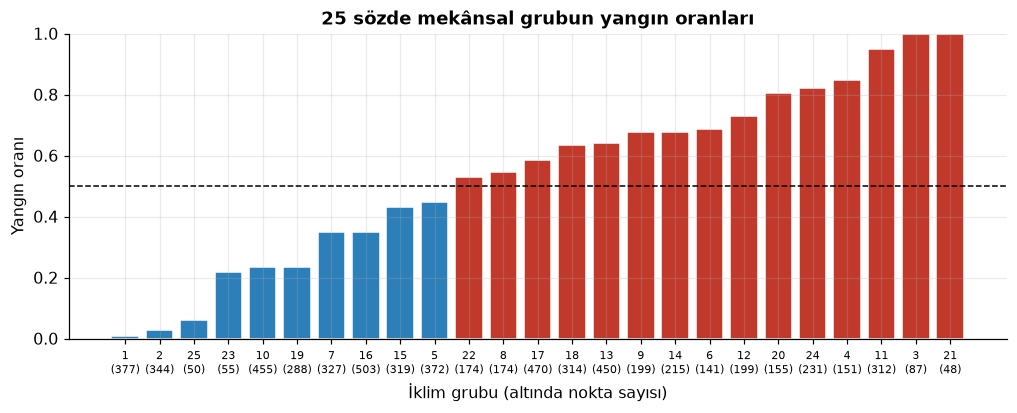

In [11]:
# =============================================================================
# 5.2  İklim grupları: 25 küme (k-ortalamalar)
# =============================================================================
z = StandardScaler().fit_transform(df[IKLIM])
km = KMeans(n_clusters=25, random_state=TOHUM, n_init=10).fit(z)

# Küme numaraları ortalama sıcaklığa göre sıralanır: 1 = en serin grup
sira = pd.Series(km.labels_).groupby(km.labels_).apply(
    lambda s: df.loc[s.index, "Sicaklik"].mean())
df["Iklim_Grubu"] = pd.Series(km.labels_).map(
    {eski: yeni + 1 for yeni, eski in enumerate(sira.sort_values().index)})

grup = (df.groupby("Iklim_Grubu")
          .agg(nokta=("Yangin", "size"), yangin_orani=("Yangin", "mean"),
               sicaklik=("Sicaklik", "mean"), yagis=("Yagis", "mean"),
               yukseklik=("Yukseklik", "mean"))
          .round(3))
display(grup.T)

saf = float(((grup.yangin_orani >= 0.8) | (grup.yangin_orani <= 0.2)).mean())
print(f"Grup sayısı: {len(grup)} · en küçük {int(grup.nokta.min())} · "
      f"en büyük {int(grup.nokta.max())} nokta")
print(f"Yangın oranı %80'in üstünde ya da %20'nin altında olan grup: %{saf * 100:.0f}")

fig, ax = plt.subplots(figsize=(11, 3.6))
s = grup.yangin_orani.sort_values()
ax.bar(range(len(s)), s.values,
       color=[RENK["yangin"] if v >= 0.5 else RENK["yok"] for v in s.values],
       edgecolor="white")
ax.axhline(0.5, color="k", ls="--", lw=1)
ax.set_xticks(range(len(s)))
ax.set_xticklabels([f"{i}\n({int(grup.loc[i, 'nokta'])})" for i in s.index], fontsize=7.5)
ax.set_ylim(0, 1)
ax.set_xlabel("İklim grubu (altında nokta sayısı)")
ax.set_ylabel("Yangın oranı")
ax.set_title("25 sözde mekânsal grubun yangın oranları")
plt.show()

Grupların yangın oranları %0,8 ile %100 arasında değişir; grupların yaklaşık üçte birinde oran %80'in üstünde ya da %20'nin altındadır. Bu, bazı bölgelerin neredeyse tamamen yangın, bazılarının neredeyse tamamen yangın dışı olduğu anlamına gelir. Rastgele bölünmede bu bölgelerin komşu noktaları eğitime düşer ve model “bölgeyi tanıyarak” yüksek başarı elde eder. Sözde mekânsal doğrulama tam olarak bunu engellemek için vardır.

## 6. Keşifsel veri analizi

Modelleri kurmadan önce verinin ne söylediğine bakmak gerekir. Bu bölümde beş soru sorulur: sınıflar dengeli mi, etkenler nasıl dağılıyor, hangi etken tek başına ayırt edici, etkenler birbiriyle ne kadar ilişkili ve kategorik sınıflarda yangın oranı nasıl değişiyor?

### 6.1 Sınıf dengesi

Temizlikten sonra 3.266 yangın olmayan ve 3.144 yangın noktası kalır: oran neredeyse yarı yarıyadır. Bu denge **tasarımdan** kaynaklanır; veri setini hazırlayan araştırmacı yangın noktaları kadar kontrol noktası örneklemiştir.

Bunun iki sonucu vardır. Birincisi, **doğruluk (accuracy) bu veri setinde yanıltıcı değildir**: hiçbir şey öğrenmeyen bir model bile %50,9 doğruluğa ulaşır, dolayısıyla %80'in üzerindeki her değer gerçek bir öğrenmeye işaret eder. İkincisi, modellerin ürettiği olasılıklar gerçek dünyadaki yangın olasılığı değil, **bu yarı yarıya tasarım içindeki göreli duyarlılık skorudur**.

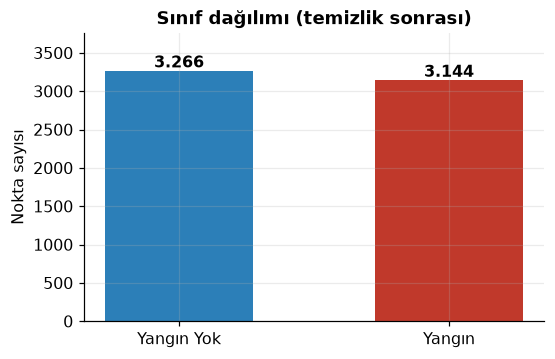

Sinif
Yangın Yok    3266
Yangın        3144
Yangın oranı: %49.0


In [12]:
sayim = df["Sinif"].value_counts().reindex(SINIFLAR)

fig, ax = plt.subplots(figsize=(5.4, 3.4))
b = ax.bar(sayim.index, sayim.values, color=[RENK["yok"], RENK["yangin"]], width=0.55)
for rect, v in zip(b, sayim.values):
    ax.text(rect.get_x() + rect.get_width() / 2, v + 45, f"{v:,}".replace(",", "."),
            ha="center", fontweight="bold")
ax.set_ylim(0, sayim.max() * 1.15)
ax.set_ylabel("Nokta sayısı")
ax.set_title("Sınıf dağılımı (temizlik sonrası)")
plt.show()

print(sayim.to_string())
print(f"Yangın oranı: %{100 * df['Yangin'].mean():.1f}")

### 6.2 Etkenlerin sınıflara göre dağılımı

Aşağıdaki dokuz histogram, her sayısal etkenin iki sınıftaki dağılımını üst üste gösterir. Amaç, hangi etkenin sınıfları **ayırmaya aday** olduğunu gözle görmektir. Dikkat edilmesi gereken nokta şudur: hiçbir etken tek başına iki sınıfı temiz biçimde ayıramaz; dağılımların hepsi geniş ölçüde örtüşür. Bu, birden çok etkeni birlikte kullanan modellere neden ihtiyaç duyulduğunu gösterir.

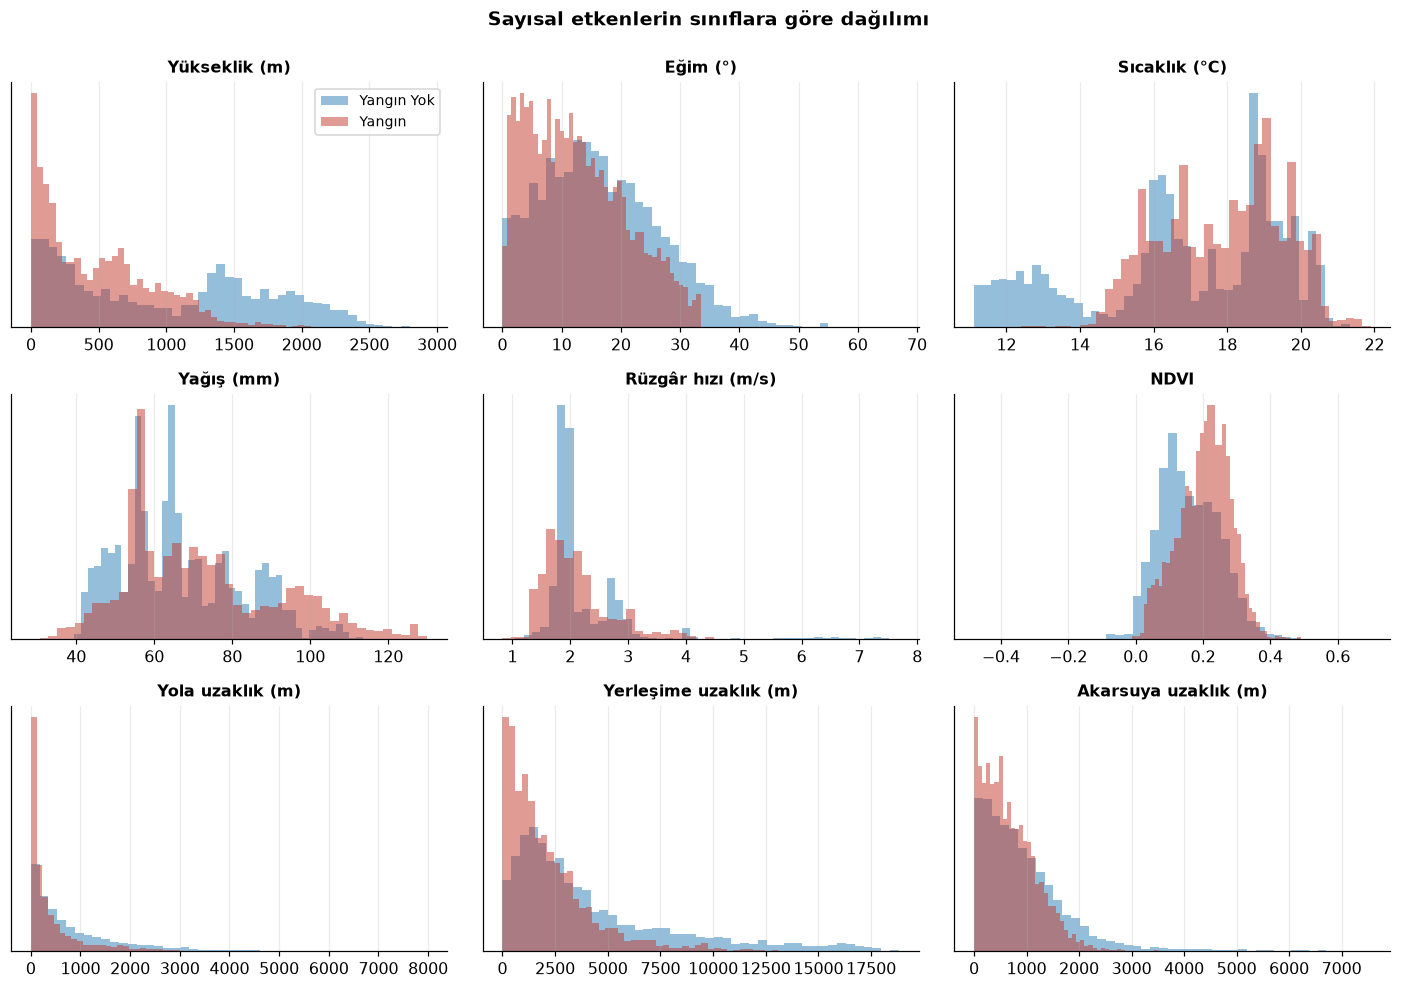

In [13]:
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, s in zip(axes.ravel(), SAYISAL):
    for deger, etiket, renk in ((0, "Yangın Yok", RENK["yok"]), (1, "Yangın", RENK["yangin"])):
        ax.hist(df.loc[df["Yangin"] == deger, s], bins=45, density=True,
                alpha=0.5, color=renk, label=etiket)
    ax.set_title(OKUNUR[s], fontsize=10.5)
    ax.set_yticks([])
axes.ravel()[0].legend(fontsize=9)
fig.suptitle("Sayısal etkenlerin sınıflara göre dağılımı", fontweight="bold", y=0.995)
fig.tight_layout()
plt.show()

### 6.3 Tek değişkenli AUC: hangi etken tek başına ne kadar ayırıyor?

AUC, bir etkenin tek başına yangın ve yangın olmayan noktaları **sıralama** gücünü ölçer. 0,5 yazı tura demektir; 1,0 mükemmel ayrım. **0,5'in altındaki değerler ters yönlü ilişkiyi** gösterir: değer arttıkça yangın olasılığı azalır. Örneğin yüksekliğin AUC'si 0,295 ise, yükseklik arttıkça yangın olasılığı azalıyor demektir; “yangın yönünde” okunduğunda bu 1 − 0,295 = 0,705'lik bir ayrımdır.

Aşağıdaki tablo, kitaptaki tek değişkenli AUC değerleriyle canlı hesabı yan yana verir.

In [14]:
satirlar = []
for s in SAYISAL:
    auc = float(roc_auc_score(df["Yangin"], df[s]))
    satirlar.append({"etken": OKUNUR[s], "AUC": auc, "kitap": KITAP_EK["tek_auc"][s],
                     "fark": auc - KITAP_EK["tek_auc"][s]})
tek = pd.DataFrame(satirlar).sort_values("AUC").reset_index(drop=True)
tek["ilişki yönü"] = np.where(tek["AUC"] < 0.5, "arttıkça azalır", "arttıkça artar")
display(tek.round(4))
print("En güçlü üç ayrım:", ", ".join(tek.tail(3)["etken"].tolist()))
print("En zayıf üç ayrım :", ", ".join(tek.head(3)["etken"].tolist()))

,etken,AUC,kitap,fark,ilişki yönü
0,Yükseklik (m),0.2954,0.2954,0.0000,arttıkça azalır
1,Yola uzaklık (m),0.3086,0.3086,0.0000,arttıkça azalır
2,Yerleşime uzaklık (m),0.3151,0.3151,0.0000,arttıkça azalır
3,Eğim (°),0.3851,0.3851,0.0000,arttıkça azalır
4,Akarsuya uzaklık (m),0.4125,0.4125,0.0000,arttıkça azalır
5,Rüzgâr hızı (m/s),0.4420,0.4420,0.0000,arttıkça azalır
6,Yağış (mm),0.5714,0.5714,0.0000,arttıkça artar
7,Sıcaklık (°C),0.5989,0.5989,0.0000,arttıkça artar
8,NDVI,0.6605,0.6605,0.0000,arttıkça artar


En güçlü üç ayrım: Yağış (mm), Sıcaklık (°C), NDVI
En zayıf üç ayrım : Yükseklik (m), Yola uzaklık (m), Yerleşime uzaklık (m)


En belirgin ayrışma yükseklikte (0,295), yola uzaklıkta (0,309) ve yerleşime uzaklıkta (0,315) görülür: bu üç etkenin değeri küçüldükçe yangın olasılığı **artar**. NDVI (0,661) ve sıcaklık (0,599) ise büyüdükçe yangın olasılığını artırır. Hiçbir etken 0,7'nin üzerine çıkmaz; tek bir değişkenle ulaşılabilecek sınır, tek kural tabanının kendisidir.

### 6.4 Korelasyon yapısı

Isı haritası, on altı özellik ile hedef arasındaki Pearson korelasyonlarını gösterir. İki noktaya dikkat edin.

Birincisi, **hedefle en güçlü doğrusal ilişki** yükseklikte (r = −0,401), yerleşime uzaklıkta (−0,321) ve çalılık/çayır göstergesinde (−0,300) görülür. Bu üçü de negatiftir: değer arttıkça yangın olasılığı azalır.

İkincisi, **girdiler arasında güçlü ilişkiler** vardır. En güçlüsü yükseklik ile sıcaklık arasındadır (r = −0,680): yükseldikçe hava soğur. Yükseklik ile yerleşime uzaklık arasında da güçlü bir ilişki vardır (r = 0,603); yerleşimler alçak kesimlerde toplanmıştır. Bu çoklu doğrusallık, doğrusal modellerin katsayılarını tek tek yorumlarken akılda tutulmalıdır.

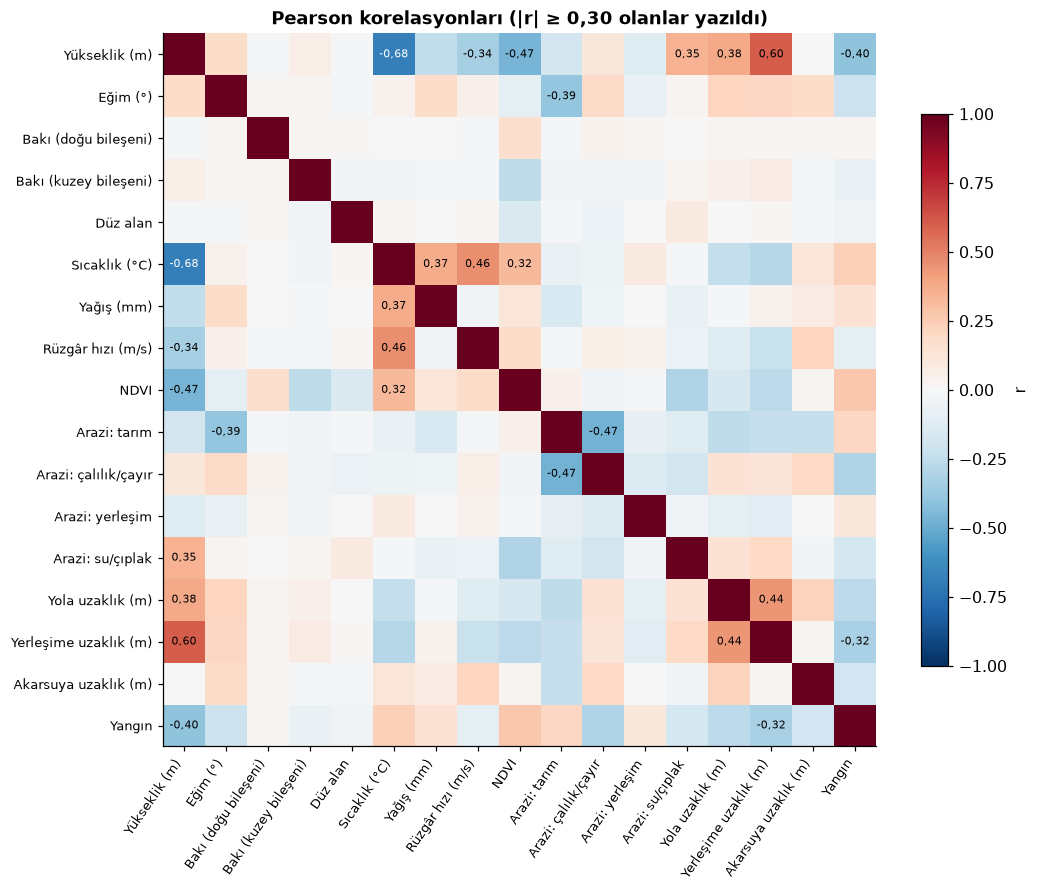

Hedefle en güçlü üç ilişki:
Yukseklik          -0.4010
Yerlesim_Uzaklik   -0.3210
Arazi_Calilik      -0.3000

Girdiler arasındaki en güçlü üç ilişki:
Yükseklik (m) – Sıcaklık (°C)           -0.6800
Yükseklik (m) – Yerleşime uzaklık (m)    0.6030
Arazi: tarım – Arazi: çalılık/çayır     -0.4700


In [15]:
KOR = df[OZELLIKLER + ["Yangin"]].corr()
etiketler = [OKUNUR[c] for c in KOR.columns]

fig, ax = plt.subplots(figsize=(9.8, 8.2))
im = ax.imshow(KOR.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(etiketler)))
ax.set_yticks(range(len(etiketler)))
ax.set_xticklabels(etiketler, rotation=55, ha="right", fontsize=8.3)
ax.set_yticklabels(etiketler, fontsize=8.3)
ax.grid(False)
for i in range(len(KOR)):
    for j in range(len(KOR)):
        if i != j and abs(KOR.values[i, j]) >= 0.30:
            ax.text(j, i, f"{KOR.values[i, j]:.2f}".replace(".", ","), ha="center", va="center",
                    fontsize=7.4, color="white" if abs(KOR.values[i, j]) > 0.62 else "black")
ax.set_title("Pearson korelasyonları (|r| ≥ 0,30 olanlar yazıldı)")
fig.colorbar(im, ax=ax, shrink=0.75, label="r")
fig.tight_layout()
plt.show()

print("Hedefle en güçlü üç ilişki:")
print(KOR["Yangin"].drop("Yangin").sort_values().head(3).round(3).to_string())
print("\nGirdiler arasındaki en güçlü üç ilişki:")
girdi = KOR.drop(index="Yangin", columns="Yangin")
ciftler = []
for i, a in enumerate(girdi.columns):
    for b in girdi.columns[i + 1:]:
        ciftler.append((f"{OKUNUR[a]} – {OKUNUR[b]}", float(girdi.loc[a, b])))
cift = pd.Series(dict(ciftler)).sort_values(key=np.abs, ascending=False).head(3)
print(cift.round(3).to_string())

### 6.5 Kategorik sınıflarda yangın oranı

Arazi örtüsü ve bakı, modellere girmeden önce kodlanan iki kategorik değişkendir. Yangın oranlarının sınıflar arasında ne kadar değiştiği, bu değişkenlerin neden modele girdi olduğunu gösterir.

Arazi örtüsünde çarpıcı bir sıralama vardır: yerleşim (%87) ve tarım (%68) alanlarında yangın oranı ormana (%63) yakın, hatta daha yüksektir; çalılık/çayır %31, su ve çıplak alan ise %10'dur. Yerleşim alanlarındaki bu yüksek oran, kitabın dikkat çektiği **örnekleme yanlılığının** en açık işaretidir: kontrol noktaları yerleşimlerden uzak seçilmiş olabilir. Bakıda ise güney ve güneydoğu yamaçları (%54–56) kuzey yamaçlarından (%45–47) daha yüksek orana sahiptir; bu, güney yamaçların daha kuru ve sıcak olmasıyla uyumludur.

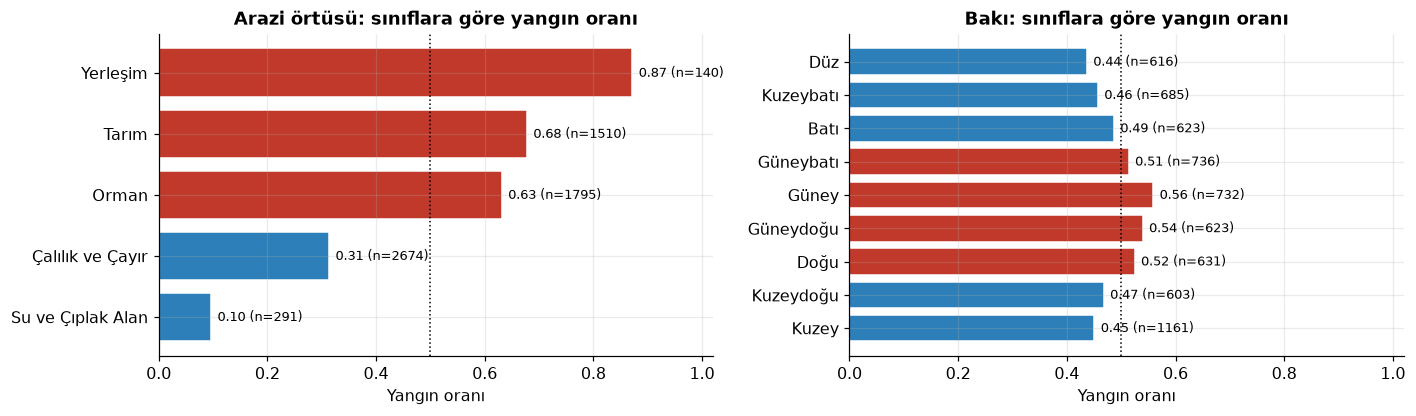

Arazi örtüsü — kitap ile karşılaştırma


,canlı,kitap,fark
Orman,0.6312,0.6312,0.0000
Su ve Çıplak Alan,0.0962,0.0962,0.0000
Tarım,0.6775,0.6775,0.0000
Yerleşim,0.8714,0.8714,0.0000
Çalılık ve Çayır,0.3134,0.3134,0.0000


In [16]:
arazi = (df.groupby("Arazi", observed=True)["Yangin"].agg(["mean", "size"])
           .rename(columns={"mean": "yangın oranı", "size": "nokta"})
           .sort_values("yangın oranı"))
baki_sirasi = ["Kuzey", "Kuzeydoğu", "Doğu", "Güneydoğu", "Güney",
               "Güneybatı", "Batı", "Kuzeybatı", "Düz"]
baki = (df.groupby("Baki", observed=True)["Yangin"].agg(["mean", "size"])
          .rename(columns={"mean": "yangın oranı", "size": "nokta"}).reindex(baki_sirasi))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
for ax, tablo, baslik in ((axes[0], arazi, "Arazi örtüsü"),
                          (axes[1], baki, "Bakı")):
    renkler = [RENK["yangin"] if v >= 0.5 else RENK["yok"] for v in tablo["yangın oranı"]]
    b = ax.barh(tablo.index, tablo["yangın oranı"], color=renkler, edgecolor="white")
    for rect, (v, n) in zip(b, zip(tablo["yangın oranı"], tablo["nokta"])):
        ax.text(v + 0.012, rect.get_y() + rect.get_height() / 2, f"{v:.2f} (n={int(n)})",
                va="center", fontsize=8.5)
    ax.set_xlim(0, 1.02)
    ax.axvline(0.5, color="k", ls=":", lw=1)
    ax.set_xlabel("Yangın oranı")
    ax.set_title(f"{baslik}: sınıflara göre yangın oranı")
fig.tight_layout()
plt.show()

print("Arazi örtüsü — kitap ile karşılaştırma")
kiyas = pd.DataFrame({"canlı": arazi["yangın oranı"], "kitap": pd.Series(KITAP_EK["arazi"])})
kiyas["fark"] = kiyas["canlı"] - kiyas["kitap"]
display(kiyas.round(4))

## 7. Eğitim/test bölünmesi

Bütün modeller **aynı** bölünmeyi kullanır; adil karşılaştırmanın ön koşulu budur. Bölünme, sınıf oranlarını koruyan (katmanlı) rastgele %80/%20'dir ve tek bir tohuma (`random_state = 42`) bağlıdır. Tohum sabit olduğu için defter her çalıştırıldığında aynı 5.128/1.282 nokta seçilir.

Üç kural bu bölünmeyi güvenilir kılar:

1. **Karıştırma zorunlu.** Ham dosya sınıfa göre sıralıdır (Bölüm 2.3); karıştırmadan bölmek eğitim ve test kümelerini farklı sınıflardan oluşturur.
2. **Ön işlem yalnızca eğitimden.** Ölçekleyici (StandardScaler) yalnızca eğitim kümesine oturtulur, test kümesine dönüştürülerek uygulanır. Bütün veriye oturtmak, test kümesinin ortalama ve varyans bilgisini eğitime sızdırır.
3. **Temizlik bölünmeden önce.** Yinelenen ve çelişkili kayıtlar Bölüm 4'te, bölünmeden önce çıkarılmıştır.

In [17]:
# =============================================================================
# 7.1  Katmanlı %80 / %20 bölünme (kitaptaki bölünmenin aynısı)
# =============================================================================
tr_idx, te_idx = train_test_split(df.index, test_size=0.20, stratify=df["Yangin"],
                                  random_state=TOHUM)
egitim = df.index.isin(tr_idx)

X_tr, X_te = df.loc[egitim, OZELLIKLER], df.loc[~egitim, OZELLIKLER]
yr_tr, yr_te = df.loc[egitim, "Yangin"].astype(float), df.loc[~egitim, "Yangin"].astype(float)
yc_tr, yc_te = df.loc[egitim, "Sinif"], df.loc[~egitim, "Sinif"]

print(f"Eğitim: {len(X_tr)} nokta · Test: {len(X_te)} nokta")
print("Eğitim sınıfları:", {k: int(v) for k, v in yc_tr.value_counts().reindex(SINIFLAR).items()})
print("Test sınıfları  :", {k: int(v) for k, v in yc_te.value_counts().reindex(SINIFLAR).items()})

assert (len(X_tr), len(X_te), int((yc_te == "Yangın").sum())) == (5128, 1282, 629)
print("✓ Bölünme kitaptaki değerlerle aynı (5.128 / 1.282 · testte 629 yangın)")

Eğitim: 5128 nokta · Test: 1282 nokta
Eğitim sınıfları: {'Yangın Yok': 2613, 'Yangın': 2515}
Test sınıfları  : {'Yangın Yok': 653, 'Yangın': 629}
✓ Bölünme kitaptaki değerlerle aynı (5.128 / 1.282 · testte 629 yangın)


## 8. Ölçütler ve karşılaştırma motoru

### Hangi ölçütler, neden?

Kitapta iki görev vardır: **regresyon** (0–1 arasında yangın duyarlılık skoru) ve **sınıflandırma** (Yangın / Yangın Yok). Her görev için farklı ölçütler kullanılır.

| Ölçüt | Görev | Ne ölçer | İyi olan |
|---|---|---|---|
| MAE | Regresyon | Ortalama mutlak hata | Küçük |
| MSE (Brier skoru) | Regresyon | Ortalama kare hata; 0/1 hedefte Brier skorudur | Küçük |
| RMSE | Regresyon | MSE'nin karekökü; hedefle aynı birimde | Küçük |
| R² (Brier beceri skoru) | Regresyon | Ortalama tabanına göre göreli iyileşme | Büyük |
| ROC-AUC | İkisi | Skorun sınıfları sıralama gücü; eşikten bağımsız | Büyük |
| Doğruluk | Sınıflandırma | Doğru etiketlenen noktaların oranı | Büyük |
| Dengeli doğruluk | Sınıflandırma | İki sınıfın duyarlılığının ortalaması | Büyük |
| F1-makro | Sınıflandırma | İki sınıfın F1'inin ortalaması; tek sınıfa yaslanmayı cezalandırır | Büyük |
| F1-ağırlıklı | Sınıflandırma | Sınıf büyüklüğüne göre ağırlıklı F1 | Büyük |

**Neden R² = Brier beceri skoru?** Hedef 0/1 olduğunda MSE, Brier skoruna eşittir. R² ise modelin Brier skorunu, “her noktaya eğitim kümesinin yangın oranını atayan” ortalamaya tabanına göre ne kadar iyileştirdiğini ölçer: `R² = 1 − Brier(model) / Brier(ortalama)`. Bu yüzden R² = 0 “hiçbir şey bilmiyorum”, R² = 1 “mükemmel” demektir.

**Neden F1-makro?** Sınıflar dengeli olsa da bir modelin yalnızca “Yangın Yok” demesi %51 doğruluk verir. F1-makro iki sınıfın F1'ini eşit ağırlıkla ortalar; böylece tek sınıfa yaslanan model cezalandırılır.

### Karşılaştırma nasıl yapılıyor?

Her algoritma bölümünün sonunda `kiyasla()` fonksiyonu çalışır. Bu fonksiyon, canlı hesaplanan değeri kitaptaki değerle yan yana koyar ve farkı **1e-5** toleransıyla karşılaştırır. Sonuçlar `KARNE` listesine birikir; Bölüm 22 bu listeyi özetler.

In [18]:
# =============================================================================
# 8.1  Metrik fonksiyonları (kitaptaki ortak.py ile aynı tanımlar)
# =============================================================================
def reg_metrikleri(y_gercek, y_tahmin):
    '''Duyarlılık skoru metrikleri. 0/1 hedefte MSE = Brier, R² = Brier beceri skoru.'''
    y_gercek = np.asarray(y_gercek, dtype=float)
    y_tahmin = np.asarray(y_tahmin, dtype=float)
    mse = mean_squared_error(y_gercek, y_tahmin)
    return {"MAE": float(mean_absolute_error(y_gercek, y_tahmin)),
            "MSE": float(mse),
            "RMSE": float(np.sqrt(mse)),
            "R2": float(r2_score(y_gercek, y_tahmin)),
            "AUC": float(roc_auc_score(y_gercek, y_tahmin))}


def cls_metrikleri(y_gercek, y_tahmin):
    y_gercek = np.asarray(y_gercek, dtype=object)
    y_tahmin = np.asarray(y_tahmin, dtype=object)
    return {"Accuracy": float(accuracy_score(y_gercek, y_tahmin)),
            "BalancedAcc": float(balanced_accuracy_score(y_gercek, y_tahmin)),
            "F1_macro": float(f1_score(y_gercek, y_tahmin, average="macro")),
            "F1_weighted": float(f1_score(y_gercek, y_tahmin, average="weighted"))}


def yangin_metrikleri(y_gercek, y_tahmin):
    '''Yalnızca Yangın sınıfı: duyarlılık, kesinlik, F1.'''
    y_gercek = np.asarray(y_gercek, dtype=object)
    y_tahmin = np.asarray(y_tahmin, dtype=object)
    return {"duyarlilik": float(recall_score(y_gercek, y_tahmin, pos_label="Yangın", zero_division=0)),
            "kesinlik": float(precision_score(y_gercek, y_tahmin, pos_label="Yangın", zero_division=0)),
            "F1": float(f1_score(y_gercek, y_tahmin, pos_label="Yangın", zero_division=0))}


def yaz_reg(m):
    for k in ("MAE", "MSE", "RMSE", "R2", "AUC"):
        print(f"  {k:<5}: {m[k]:.4f}")


def yaz_cls(m, y_gercek, y_tahmin):
    for k in ("Accuracy", "BalancedAcc", "F1_macro", "F1_weighted"):
        print(f"  {k:<13}: {m[k]:.4f}")
    y = yangin_metrikleri(y_gercek, y_tahmin)
    print(f"  {'Yangın':<13}: duyarlılık {y['duyarlilik']:.4f} · kesinlik {y['kesinlik']:.4f} · F1 {y['F1']:.4f}")

print("✓ Metrik fonksiyonları hazır: reg_metrikleri · cls_metrikleri · yangin_metrikleri · yaz_reg · yaz_cls")

✓ Metrik fonksiyonları hazır: reg_metrikleri · cls_metrikleri · yangin_metrikleri · yaz_reg · yaz_cls


> **Küçük bir not.** `yaz_cls()` fonksiyonu “Yangın” sınıfının duyarlılık ve kesinliğini de yazar; bunlar F1-makro ve karmaşıklık matrisinden türetildiği için ayrıca karşılaştırılmaz, matris karşılaştırması onları zaten kapsar.

In [19]:
# =============================================================================
# 8.2  Karşılaştırma motoru
# -----------------------------------------------------------------------------
# _satir() tek bir ölçütü karşılaştırır, KARNE'ye kaydeder ve biçimlenmiş satır döndürür.
# kiyasla() bir algoritmanın ilgili ölçüt grubunu yazdırır.
# =============================================================================
TOL = 1e-5
KARNE = []
CANLI = {}
OLASILIK = {}      # sınıflandırıcıların yangın olasılığı/skoru
SKOR_REG = {}      # regresyon modellerinin duyarlılık skoru (ROC için)


def _satir(ad, olcut, canli, kitap, tam=False):
    fark = float(canli) - float(kitap)
    ok = abs(fark) < TOL
    KARNE.append({"algoritma": ADLAR[ad], "olcut": olcut, "canli": float(canli),
                  "kitap": float(kitap), "fark": fark, "eslesti": bool(ok)})
    if tam:
        return f"  {olcut:<24}{int(round(canli)):>11d}{int(round(kitap)):>11d}{'':>12}   {'✓' if ok else '✗'}"
    return f"  {olcut:<24}{canli:>11.6f}{kitap:>11.6f}{fark:>+12.2e}   {'✓' if ok else '✗'}"


def kiyasla(ad, reg=None, cls=None, cv=None, auc_ek=None, skor=None):
    print(f"KİTAP İLE KARŞILAŞTIRMA — {ADLAR[ad]}")
    print(f"  {'ölçüt':<24}{'canlı':>11}{'kitap':>11}{'fark':>12}   durum")
    print("  " + "-" * 68)
    n0 = len(KARNE)
    if reg is not None:
        for olcut in ("MAE", "MSE", "RMSE", "R2", "AUC"):
            print(_satir(ad, olcut, reg[olcut], KITAP[ad]["reg"][olcut]))
    if auc_ek is not None:
        print(_satir(ad, "AUC (olasılık)", auc_ek, KITAP[ad]["auc_olasilik"]))
    if cls is not None:
        for olcut in ("Accuracy", "BalancedAcc", "F1_macro", "F1_weighted"):
            print(_satir(ad, olcut, cls[olcut], KITAP[ad]["cls"][olcut]))
    if cv is not None:
        if cv.get("R2_ort") is not None and KITAP[ad]["cv_R2"][0] is not None:
            print(_satir(ad, "CV R² (ortalama)", cv["R2_ort"], KITAP[ad]["cv_R2"][0]))
            print(_satir(ad, "CV R² (std. sapma)", cv["R2_std"], KITAP[ad]["cv_R2"][1]))
        if cv.get("F1_ort") is not None and KITAP[ad]["cv_F1"][0] is not None:
            print(_satir(ad, "CV F1-makro (ort.)", cv["F1_ort"], KITAP[ad]["cv_F1"][0]))
            print(_satir(ad, "CV F1-makro (std.)", cv["F1_std"], KITAP[ad]["cv_F1"][1]))
    n = len(KARNE) - n0
    e = sum(x["eslesti"] for x in KARNE[n0:])
    print("  " + "-" * 68)
    print(f"  {e}/{n} ölçüt kitaptaki değerle eşleşti (tolerans {TOL:g}).")
    # Yalnızca o çağrıda hesaplanan görev yazılır; önceki sonuçlar silinmez.
    _kayit = CANLI.setdefault(ad, {})
    if reg is not None:
        _kayit["reg"] = reg
    if cls is not None:
        _kayit["cls"] = cls
    if cv is not None:
        _kayit["cv"] = cv
    if skor is not None:
        SKOR_REG[ad] = np.asarray(skor, dtype=float)

print("✓ Karşılaştırma motoru hazır: kiyasla() · KARNE · CANLI · OLASILIK · SKOR_REG")

✓ Karşılaştırma motoru hazır: kiyasla() · KARNE · CANLI · OLASILIK · SKOR_REG


In [20]:
# =============================================================================
# 8.3  Yardımcılar: sınıf kodları, olasılık, karmaşıklık matrisi, grafikler
# =============================================================================
def kod(y):
    '''Kategorik etiketi 0/1 koduna çevirir (0 = Yangın Yok, 1 = Yangın).'''
    return pd.Series(pd.Categorical(y, categories=SINIFLAR).codes,
                     index=getattr(y, "index", None))


def sinifa(k):
    '''0/1 kodunu kategorik etikete geri çevirir.'''
    return pd.Categorical.from_codes(np.asarray(k, dtype=int).ravel(), categories=SINIFLAR)


def olasilik_al(model, X):
    '''Yangın sınıfının olasılığını (yoksa karar fonksiyonu skorunu) döndürür.'''
    if hasattr(model, "predict_proba"):
        p = np.asarray(model.predict_proba(X))
        siniflar = list(model.classes_)
        for hedef in ("Yangın", 1):
            if hedef in siniflar:
                return p[:, siniflar.index(hedef)]
        return p[:, -1]
    skor = np.asarray(model.decision_function(X)).ravel()
    # İkili SVC'de karar fonksiyonu classes_[1] yönündedir; alfabetik sırada bu
    # çoğu zaman "Yangın Yok" olur. Skoru "Yangın" yönüne çevir.
    siniflar = list(getattr(model, "classes_", []))
    if len(siniflar) == 2 and siniflar[0] == "Yangın":
        skor = -skor
    return skor


def km_kiyasla(ad, y_gercek, y_tahmin):
    '''Karmaşıklık matrisini kurar, kitaptaki matrisle karşılaştırır ve çizer.'''
    cm = confusion_matrix(np.asarray(y_gercek, dtype=object),
                          np.asarray(y_tahmin, dtype=object), labels=SINIFLAR)
    kitap = np.asarray(KITAP[ad]["km"])
    print(f"Karmaşıklık matrisi — {ADLAR[ad]} (satır: gerçek, sütun: tahmin)")
    print(f"  {'':<18}{'tahmin: Yok':>14}{'tahmin: Yangın':>16}")
    for i, ger in enumerate(SINIFLAR):
        print(f"  gerçek: {ger:<10}{cm[i, 0]:>14d}{cm[i, 1]:>16d}")
    print()
    for i, ger in enumerate(SINIFLAR):
        for j, tah in enumerate(SINIFLAR):
            _satir(ad, f"KM {ger[:6]}→{tah[:6]}", cm[i, j], kitap[i, j], tam=True)
    print(f"  {'eşleşme':<24}{int((cm == kitap).sum())}/4 hücre")

    fig, ax = plt.subplots(figsize=(4.6, 3.8))
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(SINIFLAR); ax.set_yticklabels(SINIFLAR)
    ax.set_xlabel("Tahmin edilen"); ax.set_ylabel("Gerçek")
    ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=15,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_title(f"{ADLAR[ad]}: karmaşıklık matrisi")
    fig.tight_layout()
    plt.show()
    return cm


def katsayi_ciz(s, baslik, xetiket):
    s = s.sort_values()
    fig, ax = plt.subplots(figsize=(7.4, 5.2))
    ax.barh(s.index, s.values, color=[RENK["yok"] if v < 0 else RENK["yangin"] for v in s.values],
            edgecolor="white")
    ax.axvline(0, color="k", lw=0.8)
    ax.set_xlabel(xetiket)
    ax.set_title(baslik)
    fig.tight_layout()
    plt.show()


def onem_ciz(onemler, baslik):
    s = pd.Series(np.asarray(onemler, dtype=float),
                  index=[OKUNUR[c] for c in OZELLIKLER]).sort_values()
    fig, ax = plt.subplots(figsize=(7.4, 5.4))
    ax.barh(s.index, s.values, color=RENK["vurgu"], edgecolor="white")
    ax.set_xlabel("Önem")
    ax.set_title(baslik)
    fig.tight_layout()
    plt.show()


def duyarlilik_ciz(degerler, r2s, f1s, xetiket, baslik, secilen=None, log=False):
    x = np.asarray(degerler, dtype=float)
    fig, ax1 = plt.subplots(figsize=(7.8, 4.2))
    if r2s is not None and not np.all(np.isnan(r2s)):
        ax1.plot(x, r2s, "o-", color=RENK["yok"], ms=4, label="R² (regresyon)")
        ax1.set_ylabel("R²", color=RENK["yok"])
    ax1.set_xlabel(xetiket)
    if log:
        ax1.set_xscale("log")
    if secilen is not None:
        ax1.axvline(secilen, color=RENK["gri"], ls=":", lw=1.4,
                    label=f"Seçilen değer ({secilen})")
    ax2 = ax1.twinx()
    if f1s is not None and not np.all(np.isnan(f1s)):
        ax2.plot(x, f1s, "s--", color=RENK["yangin"], ms=4, label="F1-makro (sınıflandırma)")
        ax2.set_ylabel("F1-makro", color=RENK["yangin"])
    ax2.grid(False)
    ax1.set_title(baslik)
    s1, e1 = ax1.get_legend_handles_labels()
    s2, e2 = ax2.get_legend_handles_labels()
    ax1.legend(s1 + s2, e1 + e2, loc="best", fontsize=9)
    fig.tight_layout()
    plt.show()

print("✓ Yardımcılar hazır: kod · sinifa · olasilik_al · km_kiyasla · katsayi_ciz · onem_ciz · duyarlilik_ciz")

✓ Yardımcılar hazır: kod · sinifa · olasilik_al · km_kiyasla · katsayi_ciz · onem_ciz · duyarlilik_ciz


In [21]:
# =============================================================================
# 8.4  Sözde mekânsal grup doğrulaması (5 kat)
# -----------------------------------------------------------------------------
# Yalnızca EĞİTİM kümesi kullanılır. Her katta bazı iklim grupları bütünüyle
# dışarıda bırakılır; model hiç görmediği bölgelerde sınanır. Test kümesine
# bu döngüde hiç dokunulmaz.
# =============================================================================
def katlar(k=5):
    egitim_df = df[egitim]
    skf = StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=TOHUM)
    for a, b in skf.split(egitim_df[OZELLIKLER], egitim_df["Yangin"], egitim_df["Iklim_Grubu"]):
        yield egitim_df.iloc[a], egitim_df.iloc[b]


def cv_calistir(ad, reg_fabrika=None, cls_fabrika=None, olcekle=False, kodlu=False):
    r2s, f1s = [], []
    print(f"Sözde mekânsal grup doğrulaması — {ADLAR[ad]} (5 kat, yalnızca eğitim kümesi)")
    for i, (ea, eb) in enumerate(katlar(), start=1):
        Xa, Xb = ea[OZELLIKLER], eb[OZELLIKLER]
        yra, yrb = ea["Yangin"].astype(float), eb["Yangin"].astype(float)
        ysa, ysb = ea["Sinif"], eb["Sinif"]
        if olcekle:
            sc = StandardScaler().fit(Xa)
            Xa, Xb = sc.transform(Xa), sc.transform(Xb)

        r2, f1 = np.nan, np.nan
        if reg_fabrika is not None:
            r2 = r2_score(yrb, reg_fabrika().fit(Xa, yra).predict(Xb))
        if cls_fabrika is not None:
            ya = kod(ysa) if kodlu else ysa
            tahmin = cls_fabrika().fit(Xa, ya).predict(Xb)
            tahmin = sinifa(tahmin) if kodlu else tahmin
            f1 = f1_score(ysb, tahmin, average="macro")

        r2s.append(r2); f1s.append(f1)
        print(f"  kat {i}: eğitim {len(Xa):5d} · sınama {len(Xb):5d} · "
              f"R² {('—' if np.isnan(r2) else f'{r2:+.4f}')} · "
              f"F1 {'—' if np.isnan(f1) else f'{f1:.4f}'}")

    r2s, f1s = np.array(r2s, dtype=float), np.array(f1s, dtype=float)
    cv = {"R2_ort": None if np.all(np.isnan(r2s)) else float(np.nanmean(r2s)),
          "R2_std": None if np.all(np.isnan(r2s)) else float(np.nanstd(r2s)),
          "F1_ort": None if np.all(np.isnan(f1s)) else float(np.nanmean(f1s)),
          "F1_std": None if np.all(np.isnan(f1s)) else float(np.nanstd(f1s))}
    r2_yazi = "—" if cv["R2_ort"] is None else f"{cv['R2_ort']:+.4f} ± {cv['R2_std']:.4f}"
    f1_yazi = "—" if cv["F1_ort"] is None else f"{cv['F1_ort']:.4f} ± {cv['F1_std']:.4f}"
    print(f"  ortalama: R² {r2_yazi} · F1-makro {f1_yazi}")
    print()
    kiyasla(ad, cv=cv)
    return cv

print("✓ Sözde mekânsal doğrulama hazır: katlar() · cv_calistir()")

✓ Sözde mekânsal doğrulama hazır: katlar() · cv_calistir()


## 9. Taban çizgileri: modellerin geçmesi gereken çizgi

Bir modelin “iyi” olduğunu söylemek için neye göre iyi olduğunu bilmek gerekir. Kitap dört taban kullanır.

| Taban | Ne yapar | Ne söyler |
|---|---|---|
| **Ortalama** | Her test noktasına eğitim kümesinin yangın oranını (0,490) atar | Hiçbir şey bilmeyen model; R² = 0, AUC = 0,5 |
| **Çoğunluk** | Her noktaya en kalabalık sınıfı (Yangın Yok) atar | Hiçbir şey bilmeyen sınıflandırıcı; doğruluk %50,9 |
| **Tek kural (regresyon)** | Eğitimden öğrenilmiş tek bir eşik sorusunun iki yanındaki yangın oranlarını tahmin eder | “Yükseklik ≤ 1.258 m ise riskli” kuralı |
| **Tek kural (sınıflandırma)** | Aynı eşik sorusunun iki yanındaki çoğunluk sınıfını tahmin eder | Aynı kuralın sınıflandırma sürümü |

**Asıl geçilmesi gereken çizgi tek kuraldır.** Çünkü tek bir eşik sorusu, hiçbir makine öğrenmesi kullanmadan AUC = 0,698 ve F1-makro = 0,675 üretir. Bir model bu çizgiyi geçemiyorsa, öğrendiği şey en azından “yükseklik düşükse risk artar” kadar basit bir bilgi bile değildir.

In [22]:
# =============================================================================
# 9.1  Dört taban çizgisini hesapla ve kitaptaki değerlerle karşılaştır
# =============================================================================
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

ortalama_taban = np.full(len(yr_te), float(yr_tr.mean()))
cogunluk_tahmin = np.array(["Yangın Yok"] * len(yc_te), dtype=object)
kural_reg = DecisionTreeRegressor(max_depth=1, random_state=TOHUM).fit(X_tr, yr_tr)
kural_cls = DecisionTreeClassifier(max_depth=1, random_state=TOHUM).fit(
    X_tr, np.asarray(yc_tr, dtype=object))

tb = {"ortalama": reg_metrikleri(yr_te, ortalama_taban),
      "cogunluk": cls_metrikleri(yc_te, cogunluk_tahmin),
      "kural_reg": reg_metrikleri(yr_te, kural_reg.predict(X_te)),
      "kural_cls": cls_metrikleri(yc_te, kural_cls.predict(X_te))}

print("TABAN ÇİZGİLERİ — kitap ile karşılaştırma")
print(f"  {'ölçüt':<24}{'canlı':>11}{'kitap':>11}{'fark':>12}   durum")
print("  " + "-" * 68)
for k in ("MAE", "MSE", "RMSE", "R2", "AUC"):
    print(_satir("taban", f"Ortalama · {k}", tb["ortalama"][k], KITAP_TABAN["regresyon"][k]))
for k in ("Accuracy", "BalancedAcc", "F1_macro", "F1_weighted"):
    print(_satir("taban", f"Çoğunluk · {k}", tb["cogunluk"][k], KITAP_TABAN["siniflandirma"][k]))
for k in ("MAE", "MSE", "RMSE", "R2", "AUC"):
    print(_satir("taban", f"Tek kural · {k}", tb["kural_reg"][k], KITAP_TABAN["kural_regresyon"][k]))
for k in ("Accuracy", "BalancedAcc", "F1_macro", "F1_weighted"):
    print(_satir("taban", f"Tek kural · {k}", tb["kural_cls"][k], KITAP_TABAN["kural_siniflandirma"][k]))

ozellik = OZELLIKLER[kural_reg.tree_.feature[0]]
esik = float(kural_reg.tree_.threshold[0])
print()
print(f"Öğrenilen tek kural: {OKUNUR[ozellik]} ≤ {esik:.2f}")
print(f"  Altındaki yangın oranı: {kural_reg.tree_.value[1].ravel()[0]:.4f}")
print(f"  Üstündeki yangın oranı: {kural_reg.tree_.value[2].ravel()[0]:.4f}")
print(_satir("taban", "Kural eşiği", esik, KITAP_TABAN["kural"]["esik"]))
print(_satir("taban", "Kural sol oranı", kural_reg.tree_.value[1].ravel()[0], KITAP_TABAN["kural"]["sol_oran"]))
print(_satir("taban", "Kural sağ oranı", kural_reg.tree_.value[2].ravel()[0], KITAP_TABAN["kural"]["sag_oran"]))

TABAN ÇİZGİLERİ — kitap ile karşılaştırma
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  Ortalama · MAE             0.499821   0.499821   +0.00e+00   ✓
  Ortalama · MSE             0.249912   0.249912   +0.00e+00   ✓
  Ortalama · RMSE            0.499912   0.499912   +0.00e+00   ✓
  Ortalama · R2             -0.000000  -0.000000   +0.00e+00   ✓
  Ortalama · AUC             0.500000   0.500000   +0.00e+00   ✓
  Çoğunluk · Accuracy        0.509360   0.509360   +0.00e+00   ✓
  Çoğunluk · BalancedAcc     0.500000   0.500000   +0.00e+00   ✓
  Çoğunluk · F1_macro        0.337468   0.337468   +0.00e+00   ✓
  Çoğunluk · F1_weighted     0.343785   0.343785   +0.00e+00   ✓
  Tek kural · MAE            0.393058   0.393058   +0.00e+00   ✓
  Tek kural · MSE            0.197787   0.197787   +0.00e+00   ✓
  Tek kural · RMSE           0.444733   0.444733   +0.00e+00   ✓
  Tek kural · R2             0.208575 

**Sonuç.** Öğrenilen kural, yüksekliğin **1.258 m'nin altında** olup olmadığını sorar. Altındaki noktalara 0,622, üstündekilerine 0,084 yangın skoru verir. Tek başına bu soru AUC = 0,698 ve F1-makro = 0,675 üretir. Aşağıdaki on bir algoritmanın tamamı bu çizginin üstüne çıkmak zorundadır; çıkamayan model, veriden anlamlı bir şey öğrenmemiş demektir.

## 10. Lojistik Regresyon
<sub>Kitap Bölüm 4 · `notebooks/01_lojistik_regresyon.ipynb` · yalnızca sınıflandırma</sub>

**Kuram.** Özelliklerin doğrusal bir bileşimini (`z = β₀ + β₁x₁ + …`) **sigmoid** fonksiyonundan geçirerek 0–1 arasında bir olasılık üretir: `p = 1 / (1 + e⁻ᶻ)`. Olasılık 0,5'i aşarsa nokta “Yangın” olarak etiketlenir. Katsayılar log-odds cinsindendir; bir katsayının üssü (`eᵝ`) olasılık oranını verir. Karar sınırı **doğrusaldır**: bu yüzden etkileşimleri ve eşikli ilişkileri yakalayamaz.

**Veri setinde ne yapıyor?** On altı özelliğin tamamı standartlaştırılır. Katsayıların karşılaştırılabilmesi ve optimizasyonun dengeli yakınsaması için bu şarttır. `class_weight='balanced'` iki sınıfa eşit ağırlık verir; sınıflar zaten dengeli olduğu için etkisi küçüktür. Katsayılar “diğer etkenler sabitken bir standart sapmalık artışın yangın log-olasılığını ne kadar değiştirdiği” olarak okunur; arazi göstergeleri **orman alanına göre** yorumlanır.

**Kitabın bulgusu.** Tek kural tabanını geçen ama en zayıf sınıflandırıcılardan biri: F1-makro 0,735 (tek kural 0,675). Katsayıların çoğu fiziksel olarak anlamlıdır (sıcaklık ve NDVI artırır; yükseklik, yerleşime uzaklık ve çalılık azaltır). Rüzgâr hızının güçlü negatif katsayısı ise çoklu doğrusallığın işaretidir: uzun dönem rüzgâr ortalaması yükseklik ve sıcaklıkla iç içe geçmiştir.

> **Sınıflandırma:** doğruluk 0,7348 · F1-makro 0,7348 · AUC 0,8291 · CV F1 0,6826 ± 0,0476

In [23]:
# =============================================================================
# 10.1  Model + test metrikleri
# -----------------------------------------------------------------------------
# Ölçekleyici YALNIZCA eğitim kümesine oturtulur; teste dönüştürülerek uygulanır.
# =============================================================================
from sklearn.linear_model import LogisticRegression

olcek = StandardScaler().fit(X_tr)
X_tr_s, X_te_s = olcek.transform(X_tr), olcek.transform(X_te)

clf = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42)
clf.fit(X_tr_s, yc_tr)
yp = clf.predict(X_te_s)

cls = cls_metrikleri(yc_te, yp)
print("Test kümesi — sınıflandırma")
yaz_cls(cls, yc_te, yp)

olasilik = olasilik_al(clf, X_te_s)
auc = float(roc_auc_score(yr_te, olasilik))
print(f"  {'ROC-AUC':<13}: {auc:.4f}  (yangın olasılığının sıralama gücü)")
OLASILIK["Lojistik Regresyon"] = olasilik
print()
kiyasla("lojistik_regresyon", cls=cls, auc_ek=auc)

Test kümesi — sınıflandırma
  Accuracy     : 0.7348
  BalancedAcc  : 0.7351
  F1_macro     : 0.7348
  F1_weighted  : 0.7348
  Yangın       : duyarlılık 0.7504 · kesinlik 0.7206 · F1 0.7352
  ROC-AUC      : 0.8291  (yangın olasılığının sıralama gücü)

KİTAP İLE KARŞILAŞTIRMA — Lojistik Regresyon
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  AUC (olasılık)             0.829124   0.829124   +2.33e-07   ✓
  Accuracy                   0.734789   0.734789   +3.92e-07   ✓
  BalancedAcc                0.735076   0.735076   +2.17e-07   ✓
  F1_macro                   0.734789   0.734789   -2.54e-07   ✓
  F1_weighted                0.734781   0.734781   +4.69e-10   ✓
  --------------------------------------------------------------------
  5/5 ölçüt kitaptaki değerle eşleşti (tolerans 1e-05).


Karmaşıklık matrisi — Lojistik Regresyon (satır: gerçek, sütun: tahmin)
                       tahmin: Yok  tahmin: Yangın
  gerçek: Yangın Yok           470             183
  gerçek: Yangın               157             472

  eşleşme                 4/4 hücre


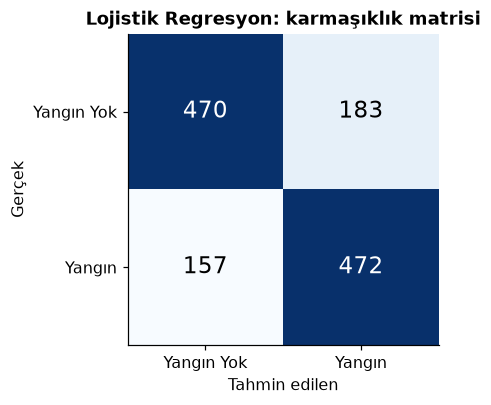

In [24]:
# =============================================================================
# 10.2  Karmaşıklık matrisi
# =============================================================================
cm = km_kiyasla("lojistik_regresyon", yc_te, yp)

,katsayı (log-odds),olasılık oranı
Ruzgar_Hizi,-0.7060,0.4930
Arazi_Calilik,-0.6000,0.5490
Yukseklik,-0.4530,0.6360
Yerlesim_Uzaklik,-0.4370,0.6460
Arazi_Su_Ciplak,-0.4260,0.6530
Akarsu_Uzaklik,-0.3000,0.7410
Egim,-0.2930,0.7460
Yol_Uzaklik,-0.1120,0.8940
Baki_Cos,-0.0990,0.9060
Arazi_Tarim,-0.0930,0.9110


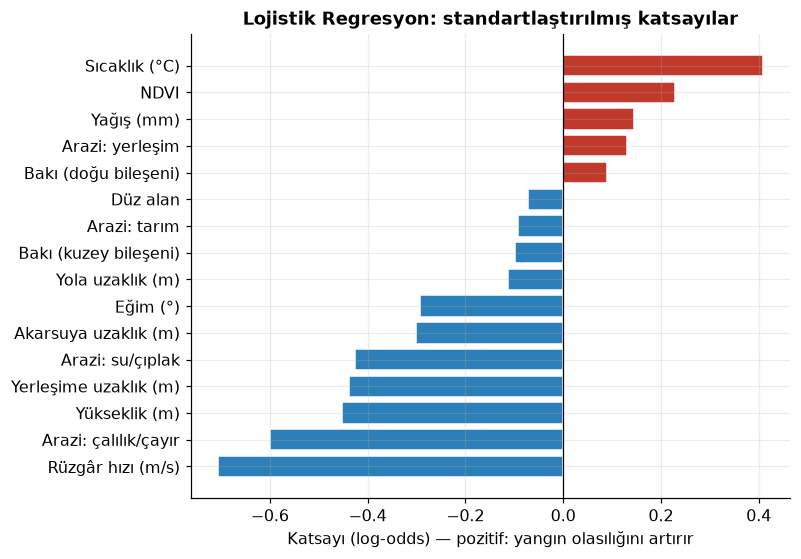

Yangın olasılığını en çok artıran üç etken:
  Sıcaklık (°C)              +0.409   (olasılık oranı 1.51)
  NDVI                       +0.230   (olasılık oranı 1.26)
  Yağış (mm)                 +0.144   (olasılık oranı 1.16)
Yangın olasılığını en çok azaltan üç etken:
  Rüzgâr hızı (m/s)          -0.706   (olasılık oranı 0.49)
  Arazi: çalılık/çayır       -0.600   (olasılık oranı 0.55)
  Yükseklik (m)              -0.453   (olasılık oranı 0.64)

Kitaptaki sıra: rüzgâr −0,71 · çalılık −0,60 · yükseklik −0,45 · sıcaklık +0,41 · NDVI +0,23


In [25]:
# =============================================================================
# 10.3  Katsayıların çözümlenmesi
# -----------------------------------------------------------------------------
# scikit-learn tek bir katsayı vektörü öğrenir; bu vektör classes_ içindeki
# İKİNCİ sınıfın log-olasılığına aittir. Sınıf sırası alfabetiktir:
# ['Yangın', 'Yangın Yok'] -> işaret çevrilerek "Yangın" yönüne getirilir.
# =============================================================================
isaret = 1.0 if clf.classes_[1] == "Yangın" else -1.0
katsayi = pd.Series(isaret * clf.coef_[0], index=OZELLIKLER)

tablo = pd.DataFrame({"katsayı (log-odds)": katsayi, "olasılık oranı": np.exp(katsayi)})
display(tablo.sort_values("katsayı (log-odds)").round(3))

katsayi_ciz(katsayi.rename(index=OKUNUR),
            "Lojistik Regresyon: standartlaştırılmış katsayılar",
            "Katsayı (log-odds) — pozitif: yangın olasılığını artırır")

print("Yangın olasılığını en çok artıran üç etken:")
for ad, v in katsayi.nlargest(3).items():
    print(f"  {OKUNUR[ad]:<26} {v:+.3f}   (olasılık oranı {np.exp(v):.2f})")
print("Yangın olasılığını en çok azaltan üç etken:")
for ad, v in katsayi.nsmallest(3).items():
    print(f"  {OKUNUR[ad]:<26} {v:+.3f}   (olasılık oranı {np.exp(v):.2f})")
print()
print("Kitaptaki sıra: rüzgâr −0,71 · çalılık −0,60 · yükseklik −0,45 · sıcaklık +0,41 · NDVI +0,23")

In [26]:
# =============================================================================
# 10.4  Sözde mekânsal doğrulama
# =============================================================================
cv = cv_calistir("lojistik_regresyon",
                 cls_fabrika=lambda: LogisticRegression(max_iter=2000, class_weight="balanced",
                                                        random_state=42),
                 olcekle=True)

Sözde mekânsal grup doğrulaması — Lojistik Regresyon (5 kat, yalnızca eğitim kümesi)
  kat 1: eğitim  4023 · sınama  1105 · R² — · F1 0.6989
  kat 2: eğitim  4170 · sınama   958 · R² — · F1 0.6511
  kat 3: eğitim  4114 · sınama  1014 · R² — · F1 0.7058
  kat 4: eğitim  4055 · sınama  1073 · R² — · F1 0.7476
  kat 5: eğitim  4150 · sınama   978 · R² — · F1 0.6098
  ortalama: R² — · F1-makro 0.6826 ± 0.0476

KİTAP İLE KARŞILAŞTIRMA — Lojistik Regresyon
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  CV F1-makro (ort.)         0.682620   0.682620   -2.48e-07   ✓
  CV F1-makro (std.)         0.047582   0.047582   +4.62e-07   ✓
  --------------------------------------------------------------------
  2/2 ölçüt kitaptaki değerle eşleşti (tolerans 1e-05).


## 11. Lineer Regresyon
<sub>Kitap Bölüm 5 · `notebooks/02_lineer_regresyon.ipynb` · yalnızca regresyon</sub>

**Kuram.** Hedefi özelliklerin doğrusal bir bileşimi olarak modeller ve katsayıları **en küçük kareler** yöntemiyle çözer. Hedef 0/1 olduğunda bu modele **doğrusal olasılık modeli** denir: tahmin, yangın olasılığının doğrusal bir yaklaşımıdır. Doğrusal bir fonksiyon 0–1 aralığıyla sınırlı olmadığı için tahminler aralığın dışına taşabilir; bu, yöntemin bilinen zaafıdır ve lojistik regresyonun neden geliştirildiğini açıklar.

**Veri setinde ne yapıyor?** On altı özelliğin ham birimleriyle eğitilir; en küçük kareler çözümü ölçeklemeden etkilenmediği için standartlaştırma gerekmez. Katsayılar ham birimlere bağlı olduğundan (metre, °C, NDVI) doğrudan karşılaştırılamaz; bu yüzden model bir de standartlaştırılmış özelliklerle kurulur. Ayarlanan bir karmaşıklık parametresi yoktur.

**Kitabın bulgusu.** Test R² 0,314 ve AUC 0,829 ile tek kural tabanını (R² 0,209 · AUC 0,698) geçer; ancak diğer bütün regresyon modellerinin altında kalır. Test noktalarının %6,9'u 0–1 aralığının dışında skor alır. Regresyon görevinin **referans çizgisidir**: karmaşık bir model bu çizgiyi belirgin biçimde geçemiyorsa, veride yakalanabilir doğrusal olmayan bir sinyal yok demektir.

> **Regresyon:** R² 0,3142 · AUC 0,8288 · MSE 0,1714 · CV R² 0,2126 ± 0,0917

In [27]:
# =============================================================================
# 11.1  Model + test metrikleri
# =============================================================================
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_tr, yr_tr)
y_pred = model.predict(X_te)

reg = reg_metrikleri(yr_te, y_pred)
print("Test kümesi — regresyon")
yaz_reg(reg)

disari = float(((y_pred < 0) | (y_pred > 1)).mean())
print(f"  0–1 aralığının dışına taşan tahmin: %{100 * disari:.1f}")
OLASILIK["Lineer Regresyon"] = y_pred      # ROC karşılaştırması için skorlar saklanır
print()
kiyasla("lineer_regresyon", reg=reg, skor=y_pred)
print(_satir("lineer_regresyon", "0–1 dışı oran", disari, KITAP["lineer_regresyon"]["disari"]))

Test kümesi — regresyon
  MAE  : 0.3568
  MSE  : 0.1714
  RMSE : 0.4140
  R2   : 0.3142
  AUC  : 0.8288
  0–1 aralığının dışına taşan tahmin: %6.9

KİTAP İLE KARŞILAŞTIRMA — Lineer Regresyon
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  MAE                        0.356818   0.356818   -4.37e-07   ✓
  MSE                        0.171393   0.171393   +4.10e-07   ✓
  RMSE                       0.413997   0.413997   -1.28e-07   ✓
  R2                         0.314186   0.314186   +5.96e-09   ✓
  AUC                        0.828754   0.828754   +1.66e-07   ✓
  --------------------------------------------------------------------
  5/5 ölçüt kitaptaki değerle eşleşti (tolerans 1e-05).
  0–1 dışı oran              0.069423   0.069423   -2.23e-07   ✓


İki modelin tahminleri arasındaki en büyük fark: 1.92e-14 (sayısal yuvarlama)


,standartlaştırılmış katsayı
Ruzgar_Hizi,-0.1163
Arazi_Calilik,-0.1125
Yukseklik,-0.0681
Yerlesim_Uzaklik,-0.0651
Arazi_Su_Ciplak,-0.0590
Akarsu_Uzaklik,-0.0490
Egim,-0.0461
Yol_Uzaklik,-0.0175
Baki_Cos,-0.0165
Baki_Duz,-0.0140


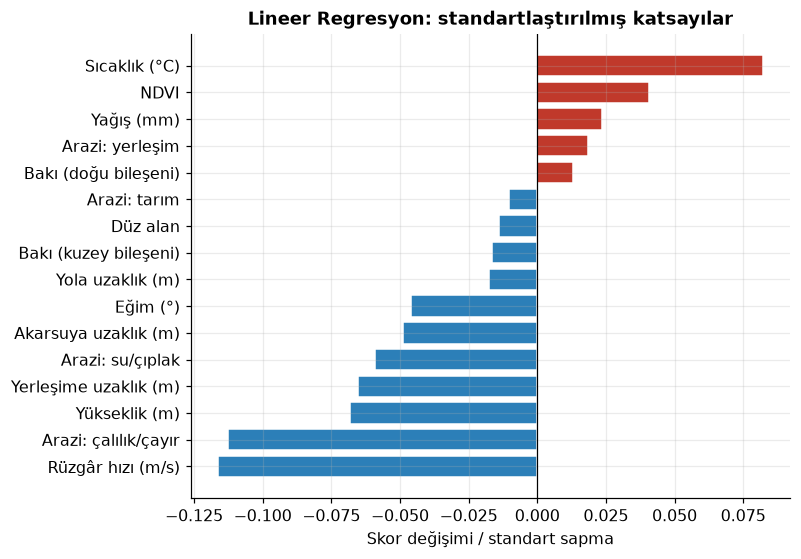

En büyük üç etki:
  Rüzgâr hızı (m/s)          -0.1163
  Arazi: çalılık/çayır       -0.1125
  Sıcaklık (°C)              +0.0822

Kitaptaki sıra: rüzgâr −0,116 · çalılık −0,113 · sıcaklık +0,082 · yükseklik −0,068


In [28]:
# =============================================================================
# 11.2  Standartlaştırılmış katsayılar
# -----------------------------------------------------------------------------
# Ham katsayılar birime bağlıdır. Aynı model standartlaştırılmış özelliklerle
# yeniden kurulur; tahminler değişmez, yalnızca katsayılar yorumlanabilir olur.
# =============================================================================
_sc = StandardScaler().fit(X_tr)
std_model = LinearRegression().fit(_sc.transform(X_tr), yr_tr)
fark = float(np.max(np.abs(std_model.predict(_sc.transform(X_te)) - y_pred)))
print(f"İki modelin tahminleri arasındaki en büyük fark: {fark:.2e} (sayısal yuvarlama)")

std_katsayi = pd.Series(std_model.coef_, index=OZELLIKLER)
display(pd.DataFrame({"standartlaştırılmış katsayı": std_katsayi})
        .sort_values("standartlaştırılmış katsayı").round(4))

katsayi_ciz(std_katsayi.rename(index=OKUNUR),
            "Lineer Regresyon: standartlaştırılmış katsayılar",
            "Skor değişimi / standart sapma")

print("En büyük üç etki:")
for ad, v in std_katsayi.reindex(std_katsayi.abs().nlargest(3).index).items():
    print(f"  {OKUNUR[ad]:<26} {v:+.4f}")
print()
print("Kitaptaki sıra: rüzgâr −0,116 · çalılık −0,113 · sıcaklık +0,082 · yükseklik −0,068")

In [29]:
# =============================================================================
# 11.3  Sözde mekânsal doğrulama
# =============================================================================
cv = cv_calistir("lineer_regresyon", reg_fabrika=lambda: LinearRegression())

Sözde mekânsal grup doğrulaması — Lineer Regresyon (5 kat, yalnızca eğitim kümesi)
  kat 1: eğitim  4023 · sınama  1105 · R² +0.2578 · F1 —
  kat 2: eğitim  4170 · sınama   958 · R² +0.1312 · F1 —
  kat 3: eğitim  4114 · sınama  1014 · R² +0.2997 · F1 —
  kat 4: eğitim  4055 · sınama  1073 · R² +0.2979 · F1 —
  kat 5: eğitim  4150 · sınama   978 · R² +0.0765 · F1 —
  ortalama: R² +0.2126 ± 0.0917 · F1-makro —

KİTAP İLE KARŞILAŞTIRMA — Lineer Regresyon
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  CV R² (ortalama)           0.212608   0.212608   +1.52e-07   ✓
  CV R² (std. sapma)         0.091688   0.091688   +4.56e-08   ✓
  --------------------------------------------------------------------
  2/2 ölçüt kitaptaki değerle eşleşti (tolerans 1e-05).


## 12. K-En Yakın Komşu (K-NN)
<sub>Kitap Bölüm 6 · `notebooks/03_knn.ipynb` · regresyon + sınıflandırma</sub>

**Kuram.** Bir noktanın değeri, özellik uzayındaki en yakın **k** komşusuna bakılarak tahmin edilir: regresyonda komşuların hedef değerlerinin ortalaması, sınıflandırmada çoğunluk oyu. Ayrı bir “öğrenme” aşaması yoktur; bütün iş tahmin anında yapılır, bu yüzden **tembel (lazy) öğrenici** denir. Uzaklık hesabına dayandığı için özelliklerin ölçeklenmesi zorunludur: aksi hâlde kilometre ölçeğindeki yerleşime uzaklık, 0–1 aralığındaki NDVI'yı gölgede bırakır.

**Veri setinde ne yapıyor?** On altı özellik standartlaştırılır ve Öklid uzaklığı kullanılır. Komşu sayısı doğrulama kümesiyle **k = 10** seçilmiştir. Bu, bir noktanın skorunun “ona en çok benzeyen 10 eğitim noktasındaki yangın oranı” olduğu anlamına gelir; skor bu yüzden yalnızca 0, 0,1, …, 1 gibi on bir farklı değer alabilir. Bir noktanın “komşuları”, topografyası, iklimi, bitki örtüsü ve insan etkisine uzaklığı ona en çok benzeyen noktalardır.

**Kitabın bulgusu.** Doğrusal modellere göre büyük sıçrama: R² 0,524, AUC 0,908, F1-makro 0,839. Bu, yangın duyarlılığının **yerel** bir yapıya sahip olduğunu gösterir: benzer koşullardaki noktalar benzer biçimde davranır. Ancak sözde mekânsal doğrulamada F1 0,760'a düşer; çünkü yeni bir bölgede “yakın komşu” ortadan kalkar.

> **Regresyon:** R² 0,5237 · AUC 0,9077 · MSE 0,1190 · CV R² 0,3449 ± 0,1332
> **Sınıflandırma:** doğruluk 0,8385 · F1-makro 0,8385 · CV F1 0,7602 ± 0,0779

In [30]:
# =============================================================================
# 12.1  Regresyon görevi
# =============================================================================
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier

olcek = StandardScaler().fit(X_tr)
X_tr_s, X_te_s = olcek.transform(X_tr), olcek.transform(X_te)

reg_model = KNeighborsRegressor(n_neighbors=10)
reg_model.fit(X_tr_s, yr_tr)
y_pred = reg_model.predict(X_te_s)

reg = reg_metrikleri(yr_te, y_pred)
print("Test kümesi — regresyon")
yaz_reg(reg)
print()
kiyasla("knn", reg=reg, skor=y_pred)

Test kümesi — regresyon
  MAE  : 0.2368
  MSE  : 0.1190
  RMSE : 0.3450
  R2   : 0.5237
  AUC  : 0.9077

KİTAP İLE KARŞILAŞTIRMA — K-NN
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  MAE                        0.236817   0.236817   +4.73e-07   ✓
  MSE                        0.119033   0.119033   -2.39e-07   ✓
  RMSE                       0.345011   0.345011   +2.48e-07   ✓
  R2                         0.523702   0.523702   +2.83e-08   ✓
  AUC                        0.907674   0.907674   +4.97e-07   ✓
  --------------------------------------------------------------------
  5/5 ölçüt kitaptaki değerle eşleşti (tolerans 1e-05).


In [31]:
# =============================================================================
# 12.2  Sınıflandırma görevi
# =============================================================================
clf = KNeighborsClassifier(n_neighbors=10)
clf.fit(X_tr_s, yc_tr)
yp = clf.predict(X_te_s)

cls = cls_metrikleri(yc_te, yp)
print("Test kümesi — sınıflandırma")
yaz_cls(cls, yc_te, yp)
OLASILIK["K-NN"] = olasilik_al(clf, X_te_s)
print()
kiyasla("knn", cls=cls)

Test kümesi — sınıflandırma
  Accuracy     : 0.8385
  BalancedAcc  : 0.8392
  F1_macro     : 0.8385
  F1_weighted  : 0.8384
  Yangın       : duyarlılık 0.8744 · kesinlik 0.8112 · F1 0.8416

KİTAP İLE KARŞILAŞTIRMA — K-NN
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  Accuracy                   0.838534   0.838534   -4.59e-07   ✓
  BalancedAcc                0.839193   0.839193   -2.81e-07   ✓
  F1_macro                   0.838472   0.838472   +1.15e-07   ✓
  F1_weighted                0.838413   0.838413   +1.47e-07   ✓
  --------------------------------------------------------------------
  4/4 ölçüt kitaptaki değerle eşleşti (tolerans 1e-05).


Karmaşıklık matrisi — K-NN (satır: gerçek, sütun: tahmin)
                       tahmin: Yok  tahmin: Yangın
  gerçek: Yangın Yok           525             128
  gerçek: Yangın                79             550

  eşleşme                 4/4 hücre


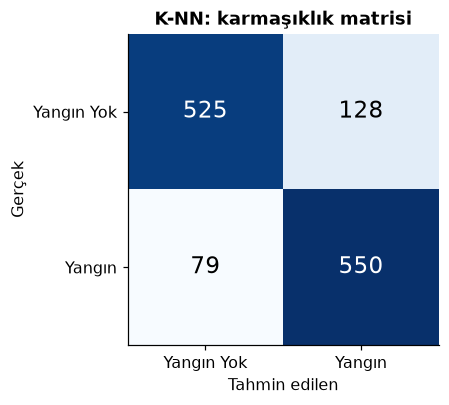

In [32]:
# =============================================================================
# 12.3  Karmaşıklık matrisi
# =============================================================================
cm = km_kiyasla("knn", yc_te, yp)

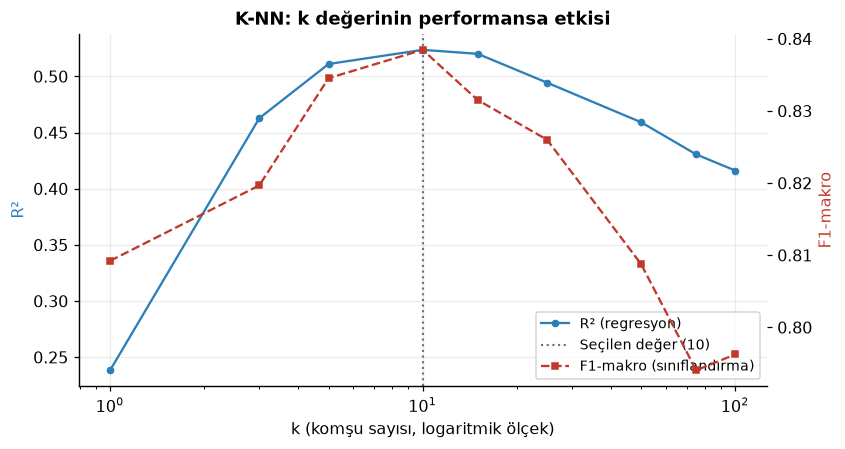

k=1  : R² 0.238 · F1 0.809
k=10 : R² 0.524 · F1 0.838
k=100: R² 0.416 · F1 0.796
Kitap: k=1 R² 0,238 · k=10 R² 0,524 / F1 0,838


In [33]:
# =============================================================================
# 12.4  k değerinin etkisi
# -----------------------------------------------------------------------------
# k, modelin karmaşıklığını belirleyen tek düğmedir. Küçük k -> gürültüye duyarlı
# (aşırı öğrenme); büyük k -> tahmin ortalamaya doğru yassılaşır (eksik öğrenme).
# Aşağıdaki eğri test kümesi üzerindedir; seçim ise doğrulama kümesiyle yapılmıştı.
# =============================================================================
degerler = [1, 3, 5, 10, 15, 25, 50, 75, 100]
r2s, f1s = [], []
for kk in degerler:
    r = KNeighborsRegressor(n_neighbors=kk).fit(X_tr_s, yr_tr)
    r2s.append(float(r2_score(yr_te, r.predict(X_te_s))))
    c = KNeighborsClassifier(n_neighbors=kk).fit(X_tr_s, yc_tr)
    f1s.append(float(f1_score(yc_te, c.predict(X_te_s), average="macro")))

duyarlilik_ciz(degerler, r2s, f1s, "k (komşu sayısı, logaritmik ölçek)",
               "K-NN: k değerinin performansa etkisi", secilen=10, log=True)
print("k=1  : R²", f"{r2s[0]:.3f}", "· F1", f"{f1s[0]:.3f}")
print("k=10 : R²", f"{r2s[3]:.3f}", "· F1", f"{f1s[3]:.3f}")
print("k=100: R²", f"{r2s[-1]:.3f}", "· F1", f"{f1s[-1]:.3f}")
print("Kitap: k=1 R² 0,238 · k=10 R² 0,524 / F1 0,838")

In [34]:
# =============================================================================
# 12.5  Sözde mekânsal doğrulama
# =============================================================================
cv = cv_calistir("knn",
                 reg_fabrika=lambda: KNeighborsRegressor(n_neighbors=10),
                 cls_fabrika=lambda: KNeighborsClassifier(n_neighbors=10),
                 olcekle=True)

Sözde mekânsal grup doğrulaması — K-NN (5 kat, yalnızca eğitim kümesi)
  kat 1: eğitim  4023 · sınama  1105 · R² +0.2346 · F1 0.7230
  kat 2: eğitim  4170 · sınama   958 · R² +0.1436 · F1 0.6252
  kat 3: eğitim  4114 · sınama  1014 · R² +0.4292 · F1 0.8181


  kat 4: eğitim  4055 · sınama  1073 · R² +0.4189 · F1 0.7974


  kat 5: eğitim  4150 · sınama   978 · R² +0.4979 · F1 0.8374
  ortalama: R² +0.3449 ± 0.1332 · F1-makro 0.7602 ± 0.0779

KİTAP İLE KARŞILAŞTIRMA — K-NN
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  CV R² (ortalama)           0.344850   0.344850   +4.12e-07   ✓
  CV R² (std. sapma)         0.133186   0.133186   +4.60e-07   ✓
  CV F1-makro (ort.)         0.760198   0.760198   -4.03e-07   ✓
  CV F1-makro (std.)         0.077853   0.077853   -3.89e-07   ✓
  --------------------------------------------------------------------
  4/4 ölçüt kitaptaki değerle eşleşti (tolerans 1e-05).


## 13. Destek Vektör Makineleri (SVM)
<sub>Kitap Bölüm 7 · `notebooks/04_svm.ipynb` · regresyon + sınıflandırma</sub>

**Kuram.** SVM, sınıfları birbirinden ayıran **en geniş marjlı** sınırı arar. RBF çekirdeği sayesinde doğrusal olmayan ilişkileri de yakalayabilir. Regresyon sürümü **SVR**, hatası ε genişliğindeki bir tüpün içinde kalan örnekleri cezalandırmaz; sınıflandırma sürümü **SVC**'dir. Marj kavramı mesafeye dayandığı için ölçekleme zorunludur. `C` parametresi marj ihlallerine verilen cezayı denetler: küçük C yumuşak marj, büyük C sıkı uyum ve aşırı öğrenme eğilimi demektir.

**Veri setinde ne yapıyor?** On altı özellik standartlaştırılır. Ceza parametresi doğrulama kümesiyle **C = 1** seçilmiştir. Eğitim kümesi 5.128 noktadır; kitabın SVM için kullandığı 8.000'lik alt örnekleme sınırının altında kaldığı için **bütün eğitim kümesi** kullanılır. Sınıflandırıcıda `class_weight='balanced'` açıktır.

**Kitabın bulgusu.** R² 0,546 ve AUC 0,918 ile KNN'ye yakın, ağaç topluluklarının altında. Sınıflandırmada F1 0,836; sözde mekânsal doğrulamada 0,779 ile KNN'yi geçer. Yani SVM'nin başarısı KNN'ye göre yeni bölgelere **daha iyi** taşınır; çünkü karar sınırı tek tek komşulara değil, genel bir marja dayanır.

> **Regresyon:** R² 0,5455 · AUC 0,9180 · MSE 0,1136 · CV R² 0,3314 ± 0,1826
> **Sınıflandırma:** doğruluk 0,8362 · F1-makro 0,8362 · CV F1 0,7785 ± 0,0751

In [35]:
# =============================================================================
# 13.1  Regresyon görevi (SVR)
# =============================================================================
from sklearn.svm import SVR, SVC

olcek = StandardScaler().fit(X_tr)
X_tr_s, X_te_s = olcek.transform(X_tr), olcek.transform(X_te)

reg_model = SVR(C=1)
reg_model.fit(X_tr_s, yr_tr)
y_pred = reg_model.predict(X_te_s)

reg = reg_metrikleri(yr_te, y_pred)
print("Test kümesi — regresyon")
yaz_reg(reg)
print(f"  destek vektörü: {len(reg_model.support_)} / {len(X_tr_s)}")
print()
kiyasla("svm", reg=reg, skor=y_pred)

Test kümesi — regresyon
  MAE  : 0.2274
  MSE  : 0.1136
  RMSE : 0.3370
  R2   : 0.5455
  AUC  : 0.9180
  destek vektörü: 2813 / 5128

KİTAP İLE KARŞILAŞTIRMA — SVM
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  MAE                        0.227403   0.227403   +4.88e-07   ✓
  MSE                        0.113574   0.113574   -4.59e-07   ✓
  RMSE                       0.337007   0.337007   -2.62e-07   ✓
  R2                         0.545547   0.545547   -4.36e-07   ✓
  AUC                        0.917969   0.917969   +4.06e-07   ✓
  --------------------------------------------------------------------
  5/5 ölçüt kitaptaki değerle eşleşti (tolerans 1e-05).


In [36]:
# =============================================================================
# 13.2  Sınıflandırma görevi (SVC)
# =============================================================================
clf = SVC(C=1, class_weight="balanced", random_state=42)
clf.fit(X_tr_s, yc_tr)
yp = clf.predict(X_te_s)

cls = cls_metrikleri(yc_te, yp)
print("Test kümesi — sınıflandırma")
yaz_cls(cls, yc_te, yp)
print(f"  destek vektörü: {len(clf.support_)} / {len(X_tr_s)}")
OLASILIK["SVM"] = olasilik_al(clf, X_te_s)
print()
kiyasla("svm", cls=cls)

Test kümesi — sınıflandırma
  Accuracy     : 0.8362
  BalancedAcc  : 0.8368
  F1_macro     : 0.8362
  F1_weighted  : 0.8361
  Yangın       : duyarlılık 0.8680 · kesinlik 0.8113 · F1 0.8387
  destek vektörü: 2239 / 5128



KİTAP İLE KARŞILAŞTIRMA — SVM
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  Accuracy                   0.836193   0.836193   +4.48e-07   ✓
  BalancedAcc                0.836779   0.836779   -2.34e-07   ✓
  F1_macro                   0.836154   0.836154   -4.29e-07   ✓
  F1_weighted                0.836106   0.836106   -2.81e-07   ✓
  --------------------------------------------------------------------
  4/4 ölçüt kitaptaki değerle eşleşti (tolerans 1e-05).


Karmaşıklık matrisi — SVM (satır: gerçek, sütun: tahmin)
                       tahmin: Yok  tahmin: Yangın
  gerçek: Yangın Yok           526             127
  gerçek: Yangın                83             546

  eşleşme                 4/4 hücre


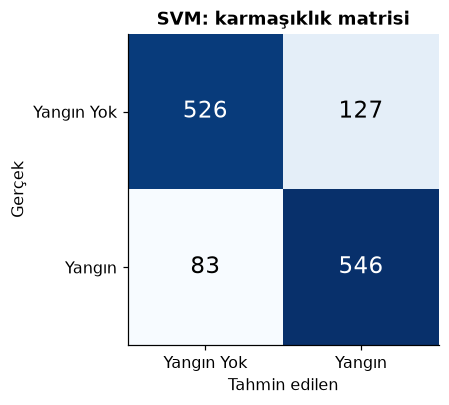

In [37]:
# =============================================================================
# 13.3  Karmaşıklık matrisi
# =============================================================================
cm = km_kiyasla("svm", yc_te, yp)

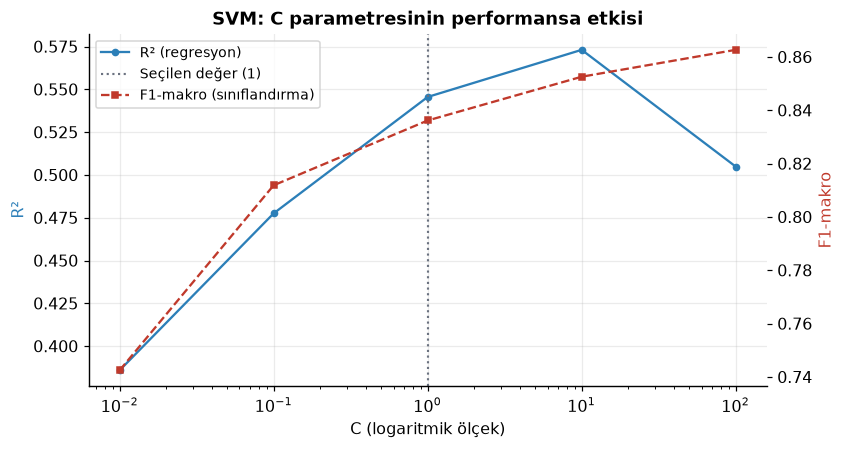

Tarama: [(0.01, 0.3859, 0.7425), (0.1, 0.4775, 0.8119), (1, 0.5455, 0.8362), (10, 0.5731, 0.8526), (100, 0.5049, 0.8626)]


In [38]:
# =============================================================================
# 13.4  C parametresinin etkisi
# =============================================================================
degerler = [0.01, 0.1, 1, 10, 100]
r2s, f1s = [], []
for CC in degerler:
    r = SVR(C=CC).fit(X_tr_s, yr_tr)
    r2s.append(float(r2_score(yr_te, r.predict(X_te_s))))
    c = SVC(C=CC, class_weight="balanced", random_state=42).fit(X_tr_s, yc_tr)
    f1s.append(float(f1_score(yc_te, c.predict(X_te_s), average="macro")))

duyarlilik_ciz(degerler, r2s, f1s, "C (logaritmik ölçek)",
               "SVM: C parametresinin performansa etkisi", secilen=1, log=True)
print("Tarama:", [(d, round(r, 4), round(f, 4)) for d, r, f in zip(degerler, r2s, f1s)])

In [39]:
# =============================================================================
# 13.5  Sözde mekânsal doğrulama
# =============================================================================
cv = cv_calistir("svm",
                 reg_fabrika=lambda: SVR(C=1),
                 cls_fabrika=lambda: SVC(C=1, class_weight="balanced", random_state=42),
                 olcekle=True)

Sözde mekânsal grup doğrulaması — SVM (5 kat, yalnızca eğitim kümesi)


  kat 1: eğitim  4023 · sınama  1105 · R² +0.2231 · F1 0.7464


  kat 2: eğitim  4170 · sınama   958 · R² +0.0273 · F1 0.6501


  kat 3: eğitim  4114 · sınama  1014 · R² +0.4490 · F1 0.8173


  kat 4: eğitim  4055 · sınama  1073 · R² +0.4281 · F1 0.8098


  kat 5: eğitim  4150 · sınama   978 · R² +0.5295 · F1 0.8691
  ortalama: R² +0.3314 ± 0.1826 · F1-makro 0.7785 ± 0.0751

KİTAP İLE KARŞILAŞTIRMA — SVM
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  CV R² (ortalama)           0.331387   0.331387   +3.48e-07   ✓
  CV R² (std. sapma)         0.182561   0.182561   -1.90e-07   ✓
  CV F1-makro (ort.)         0.778535   0.778535   -5.53e-08   ✓
  CV F1-makro (std.)         0.075123   0.075123   -2.28e-08   ✓
  --------------------------------------------------------------------
  4/4 ölçüt kitaptaki değerle eşleşti (tolerans 1e-05).


## 14. Karar Ağacı
<sub>Kitap Bölüm 8 · `notebooks/05_karar_agaci.ipynb` · regresyon + sınıflandırma</sub>

**Kuram.** Karar ağacı, özellik uzayını ardışık “eşik sorusu” ile dikdörtgen bölgelere ayırır; her yaprak bir tahmin değeri ya da sınıf taşır. En yorumlanabilir modeldir: kökten yaprağa izlenen yol doğrudan okunabilir bir kuraldır (“yükseklik 1.250 m'den alçak ve yerleşime uzaklık 2 km'den azsa…”). Ölçekleme gerektirmez; ancak derinleştikçe **aşırı öğrenmeye** son derece yatkındır.

**Veri setinde ne yapıyor?** On altı özellik olduğu gibi kullanılır. Ağaç **max_depth = 20** ve yaprak başına en az 5 örnek koşuluyla budanmıştır; sınıflandırmada sınıf ağırlıkları dengelenir. Bu iki sınır olmadan ağaç eğitim kümesini tamamen ezberler: aşağıda budanmamış ağacın eğitim F1'i 1,000, test F1'i ise daha düşük çıkacaktır.

**Kitabın bulgusu.** Regresyonda R² 0,541, sınıflandırmada F1 0,874. Tek ağaç, KNN ve SVM'yi sınıflandırmada geçer; ancak sözde mekânsal doğrulamada F1 0,731'e düşer ve regresyonda R² neredeyse sıfıra iner (0,040 ± 0,250). Bu, tek ağacın **bölgeye özgü** kurallar öğrendiğinin en açık kanıtıdır.

> **Regresyon:** R² 0,5407 · AUC 0,9028 · MSE 0,1148 · CV R² 0,0402 ± 0,2496
> **Sınıflandırma:** doğruluk 0,8736 · F1-makro 0,8735 · CV F1 0,7305 ± 0,0677

In [40]:
# =============================================================================
# 14.1  Regresyon görevi
# =============================================================================
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier

reg_model = DecisionTreeRegressor(max_depth=20, min_samples_leaf=5, random_state=42)
reg_model.fit(X_tr, yr_tr)
y_pred = reg_model.predict(X_te)

reg = reg_metrikleri(yr_te, y_pred)
print("Test kümesi — regresyon")
yaz_reg(reg)
print()
kiyasla("karar_agaci", reg=reg, skor=y_pred)

Test kümesi — regresyon
  MAE  : 0.1460
  MSE  : 0.1148
  RMSE : 0.3388
  R2   : 0.5407
  AUC  : 0.9028

KİTAP İLE KARŞILAŞTIRMA — Karar Ağacı
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  MAE                        0.146010   0.146010   +3.88e-07   ✓
  MSE                        0.114793   0.114793   -8.75e-08   ✓
  RMSE                       0.338811   0.338811   +2.78e-08   ✓
  R2                         0.540667   0.540667   +3.69e-07   ✓
  AUC                        0.902814   0.902814   -2.77e-07   ✓
  --------------------------------------------------------------------
  5/5 ölçüt kitaptaki değerle eşleşti (tolerans 1e-05).


In [41]:
# =============================================================================
# 14.2  Sınıflandırma görevi
# =============================================================================
clf = DecisionTreeClassifier(max_depth=20, min_samples_leaf=5,
                             class_weight="balanced", random_state=42)
clf.fit(X_tr, yc_tr)
yp = clf.predict(X_te)

cls = cls_metrikleri(yc_te, yp)
print("Test kümesi — sınıflandırma")
yaz_cls(cls, yc_te, yp)
OLASILIK["Karar Ağacı"] = olasilik_al(clf, X_te)
print()
kiyasla("karar_agaci", cls=cls)

Test kümesi — sınıflandırma
  Accuracy     : 0.8736
  BalancedAcc  : 0.8734
  F1_macro     : 0.8735
  F1_weighted  : 0.8736
  Yangın       : duyarlılık 0.8585 · kesinlik 0.8809 · F1 0.8696

KİTAP İLE KARŞILAŞTIRMA — Karar Ağacı
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  Accuracy                   0.873635   0.873635   -5.46e-08   ✓
  BalancedAcc                0.873357   0.873357   -8.30e-08   ✓
  F1_macro                   0.873512   0.873512   -1.93e-07   ✓
  F1_weighted                0.873586   0.873586   -3.10e-07   ✓
  --------------------------------------------------------------------
  4/4 ölçüt kitaptaki değerle eşleşti (tolerans 1e-05).


Karmaşıklık matrisi — Karar Ağacı (satır: gerçek, sütun: tahmin)
                       tahmin: Yok  tahmin: Yangın
  gerçek: Yangın Yok           580              73
  gerçek: Yangın                89             540

  eşleşme                 4/4 hücre


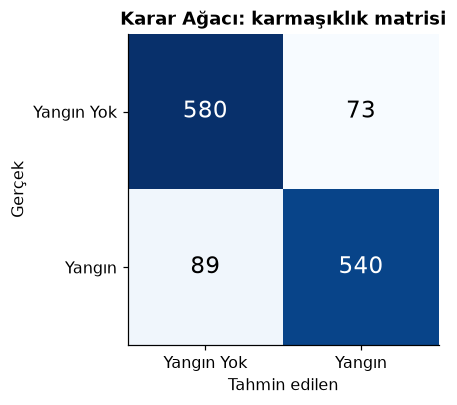

In [42]:
# =============================================================================
# 14.3  Karmaşıklık matrisi
# =============================================================================
cm = km_kiyasla("karar_agaci", yc_te, yp)

Budanmış ağaç  : derinlik 16 · yaprak 270
Budanmamış ağaç: derinlik 19 · yaprak 427


  eğitim F1 1.0000 · test F1 0.8711
Kök düğüm kuralı: Yükseklik (m) ≤ 1257.97


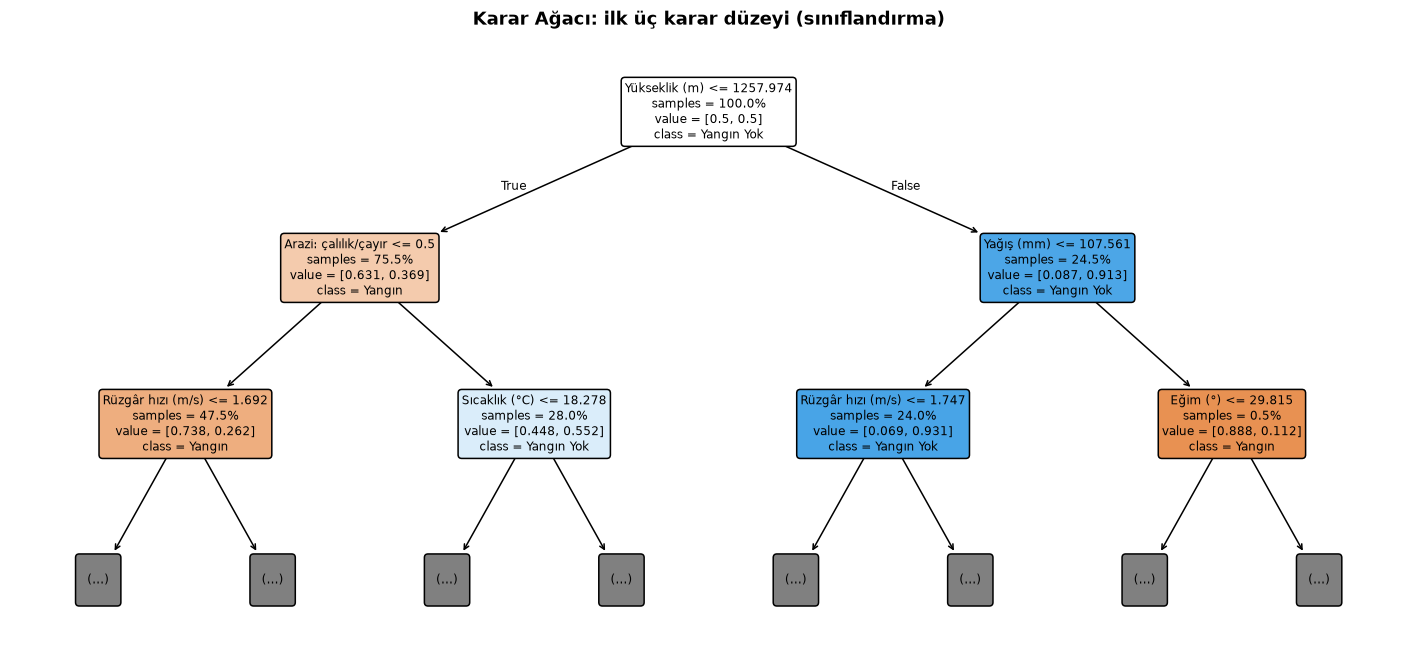

In [43]:
# =============================================================================
# 14.4  Ağaç yapısı ve aşırı öğrenme
# -----------------------------------------------------------------------------
# Budanmamış ağaç eğitim verisini neredeyse ezberler; test performansı düşer.
# Aşağıda budanmış (max_depth=20, min_samples_leaf=5) ve budanmamış ağaç
# karşılaştırılır; ardından okunabilirlik için ilk üç karar düzeyi çizilir.
# =============================================================================
from sklearn.tree import plot_tree

derin = DecisionTreeClassifier(random_state=42, class_weight="balanced").fit(X_tr, yc_tr)
print(f"Budanmış ağaç  : derinlik {clf.get_depth()} · yaprak {clf.get_n_leaves()}")
print(f"Budanmamış ağaç: derinlik {derin.get_depth()} · yaprak {derin.get_n_leaves()}")
print(f"  eğitim F1 {f1_score(yc_tr, derin.predict(X_tr), average='macro'):.4f} · "
      f"test F1 {f1_score(yc_te, derin.predict(X_te), average='macro'):.4f}")
print(f"Kök düğüm kuralı: {OKUNUR[OZELLIKLER[clf.tree_.feature[0]]]} ≤ {clf.tree_.threshold[0]:.2f}")

kucuk = DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=42).fit(X_tr, yc_tr)
fig, ax = plt.subplots(figsize=(13, 6.2))
plot_tree(kucuk, feature_names=[OKUNUR[c] for c in OZELLIKLER], class_names=list(kucuk.classes_),
          filled=True, rounded=True, fontsize=8, impurity=False, proportion=True,
          max_depth=2, ax=ax)
ax.set_title("Karar Ağacı: ilk üç karar düzeyi (sınıflandırma)")
fig.tight_layout()
plt.show()

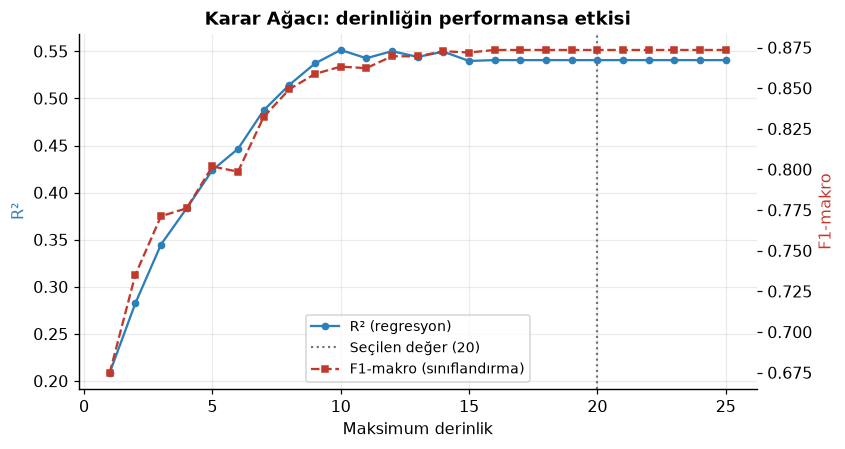

Derinlik 20: R² 0.5407 · F1 0.8735
Derinlik 5 : R² 0.4238 · F1 0.8018


In [44]:
# =============================================================================
# 14.5  Derinliğin etkisi
# =============================================================================
degerler = list(range(1, 26))
r2s, f1s = [], []
for dd in degerler:
    r = DecisionTreeRegressor(max_depth=dd, min_samples_leaf=5, random_state=42).fit(X_tr, yr_tr)
    r2s.append(float(r2_score(yr_te, r.predict(X_te))))
    c = DecisionTreeClassifier(max_depth=dd, min_samples_leaf=5, class_weight="balanced",
                               random_state=42).fit(X_tr, yc_tr)
    f1s.append(float(f1_score(yc_te, c.predict(X_te), average="macro")))

duyarlilik_ciz(degerler, r2s, f1s, "Maksimum derinlik",
               "Karar Ağacı: derinliğin performansa etkisi", secilen=20)
print(f"Derinlik 20: R² {r2s[19]:.4f} · F1 {f1s[19]:.4f}")
print(f"Derinlik 5 : R² {r2s[4]:.4f} · F1 {f1s[4]:.4f}")

In [45]:
# =============================================================================
# 14.6  Sözde mekânsal doğrulama
# =============================================================================
cv = cv_calistir("karar_agaci",
                 reg_fabrika=lambda: DecisionTreeRegressor(max_depth=20, min_samples_leaf=5,
                                                           random_state=42),
                 cls_fabrika=lambda: DecisionTreeClassifier(max_depth=20, min_samples_leaf=5,
                                                            class_weight="balanced", random_state=42))

Sözde mekânsal grup doğrulaması — Karar Ağacı (5 kat, yalnızca eğitim kümesi)
  kat 1: eğitim  4023 · sınama  1105 · R² -0.2203 · F1 0.6891


  kat 2: eğitim  4170 · sınama   958 · R² -0.3060 · F1 0.6164
  kat 3: eğitim  4114 · sınama  1014 · R² +0.2690 · F1 0.7917


  kat 4: eğitim  4055 · sınama  1073 · R² +0.2216 · F1 0.7752
  kat 5: eğitim  4150 · sınama   978 · R² +0.2367 · F1 0.7800
  ortalama: R² +0.0402 ± 0.2496 · F1-makro 0.7305 ± 0.0677

KİTAP İLE KARŞILAŞTIRMA — Karar Ağacı
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  CV R² (ortalama)           0.040199   0.040199   -1.03e-07   ✓
  CV R² (std. sapma)         0.249641   0.249641   +2.43e-07   ✓
  CV F1-makro (ort.)         0.730468   0.730468   -1.53e-07   ✓
  CV F1-makro (std.)         0.067694   0.067694   -2.69e-07   ✓
  --------------------------------------------------------------------
  4/4 ölçüt kitaptaki değerle eşleşti (tolerans 1e-05).


## 15. Rastgele Orman
<sub>Kitap Bölüm 9 · `notebooks/06_rastgele_orman.ipynb` · regresyon + sınıflandırma</sub>

**Kuram.** Rastgele orman, çok sayıda karar ağacını farklı **bootstrap** örneklemleri ve her bölünmede farklı **özellik alt kümeleri** üzerinde eğitip sonuçlarını birleştirir (bagging). Tek ağacın aşırı öğrenme zaafını topluluk gücüyle telafi eder; genellikle ayar yapılmadan dahi iyi sonuç verir. Ölçekleme gerektirmez ve özellik önemlerini doğrudan raporlar.

**Veri setinde ne yapıyor?** 200 ağaç, yaprak başına en az **1** örnek (doğrulama kümesiyle seçildi), sınıflandırmada dengeli sınıf ağırlıkları. Orman tek iş parçacığıyla (`n_jobs=1`) çalıştırılır: paralel çalıştırmada ağaç tahminleri bitiş sırasına göre toplanır ve son ondalık basamaklarda fark oluşabilir. Tek iş parçacığı her çalıştırmada aynı sonucu verir.

**Kitabın bulgusu.** İki görevde de güçlü: R² 0,751, AUC 0,973, F1 0,924. Sözde mekânsal doğrulamada F1 0,792 ile topluluklar arasında ortada kalır. Özellik önemlerinde üç iklim değişkeninin toplam payı **%39,4**'tür; bu, modelin başarısının bir kısmının bölgeyi tanımaktan geldiğini gösterir.

> **Regresyon:** R² 0,7514 · AUC 0,9734 · MSE 0,0621 · CV R² 0,3901 ± 0,1499
> **Sınıflandırma:** doğruluk 0,9243 · F1-makro 0,9243 · CV F1 0,7920 ± 0,0862

In [46]:
# =============================================================================
# 15.1  Regresyon görevi
# =============================================================================
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

reg_model = RandomForestRegressor(n_estimators=200, min_samples_leaf=1,
                                  random_state=42, n_jobs=1)
reg_model.fit(X_tr, yr_tr)
y_pred = reg_model.predict(X_te)

reg = reg_metrikleri(yr_te, y_pred)
print("Test kümesi — regresyon")
yaz_reg(reg)
print()
kiyasla("rastgele_orman", reg=reg, skor=y_pred)

Test kümesi — regresyon
  MAE  : 0.1528
  MSE  : 0.0621
  RMSE : 0.2493
  R2   : 0.7514
  AUC  : 0.9734

KİTAP İLE KARŞILAŞTIRMA — Rastgele Orman
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  MAE                        0.152812   0.152812   +1.25e-08   ✓
  MSE                        0.062131   0.062131   +2.57e-08   ✓
  RMSE                       0.249261   0.249261   -4.09e-08   ✓
  R2                         0.751389   0.751389   -2.33e-07   ✓
  AUC                        0.973371   0.973371   +3.79e-08   ✓
  --------------------------------------------------------------------
  5/5 ölçüt kitaptaki değerle eşleşti (tolerans 1e-05).


In [47]:
# =============================================================================
# 15.2  Sınıflandırma görevi
# =============================================================================
clf = RandomForestClassifier(n_estimators=200, min_samples_leaf=1, class_weight="balanced",
                             random_state=42, n_jobs=1)
clf.fit(X_tr, yc_tr)
yp = clf.predict(X_te)

cls = cls_metrikleri(yc_te, yp)
print("Test kümesi — sınıflandırma")
yaz_cls(cls, yc_te, yp)
OLASILIK["Rastgele Orman"] = olasilik_al(clf, X_te)
print()
kiyasla("rastgele_orman", cls=cls)

Test kümesi — sınıflandırma
  Accuracy     : 0.9243
  BalancedAcc  : 0.9245
  F1_macro     : 0.9243
  F1_weighted  : 0.9243
  Yangın       : duyarlılık 0.9332 · kesinlik 0.9143 · F1 0.9237

KİTAP İLE KARŞILAŞTIRMA — Rastgele Orman
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  Accuracy                   0.924337   0.924337   -2.65e-08   ✓
  BalancedAcc                0.924500   0.924500   +3.49e-07   ✓
  F1_macro                   0.924331   0.924331   +4.03e-07   ✓
  F1_weighted                0.924344   0.924344   -4.43e-07   ✓
  --------------------------------------------------------------------
  4/4 ölçüt kitaptaki değerle eşleşti (tolerans 1e-05).


Karmaşıklık matrisi — Rastgele Orman (satır: gerçek, sütun: tahmin)
                       tahmin: Yok  tahmin: Yangın
  gerçek: Yangın Yok           598              55
  gerçek: Yangın                42             587

  eşleşme                 4/4 hücre


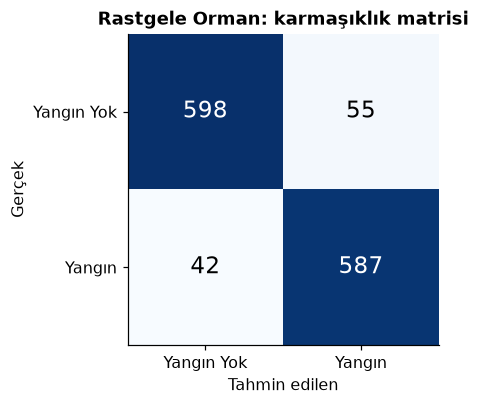

In [48]:
# =============================================================================
# 15.3  Karmaşıklık matrisi
# =============================================================================
cm = km_kiyasla("rastgele_orman", yc_te, yp)

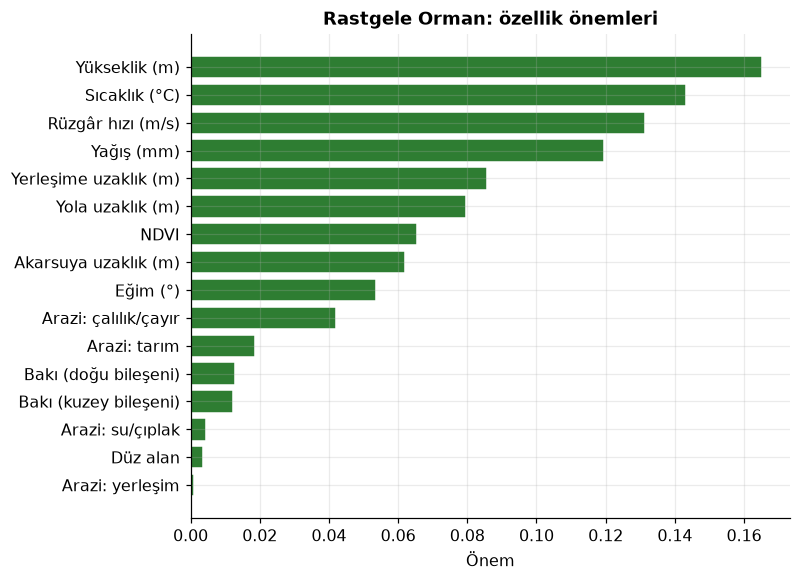

,önem,pay (%)
Yukseklik,0.1700,16.5100
Sicaklik,0.1400,14.3200
Ruzgar_Hizi,0.1300,13.1500
Yagis,0.1200,11.9400
Yerlesim_Uzaklik,0.0900,8.5700
Yol_Uzaklik,0.0800,7.9500
NDVI,0.0700,6.5400
Akarsu_Uzaklik,0.0600,6.2000
Egim,0.0500,5.3700
Arazi_Calilik,0.0400,4.2100


Üç iklim değişkeninin toplam payı: %39.4  (kitap: %39,4)


In [49]:
# =============================================================================
# 15.4  Özellik önemleri
# -----------------------------------------------------------------------------
# Önem, bir değişkenin bölünmelerde sağladığı ortalama saflık kazancıdır.
# =============================================================================
onem = pd.Series(clf.feature_importances_, index=OZELLIKLER)
onem_ciz(clf.feature_importances_, "Rastgele Orman: özellik önemleri")
display(pd.DataFrame({"önem": onem, "pay (%)": 100 * onem / onem.sum()})
        .sort_values("önem", ascending=False).round(2))

iklim_payi = float(onem[IKLIM].sum())
print(f"Üç iklim değişkeninin toplam payı: %{100 * iklim_payi:.1f}  (kitap: %39,4)")

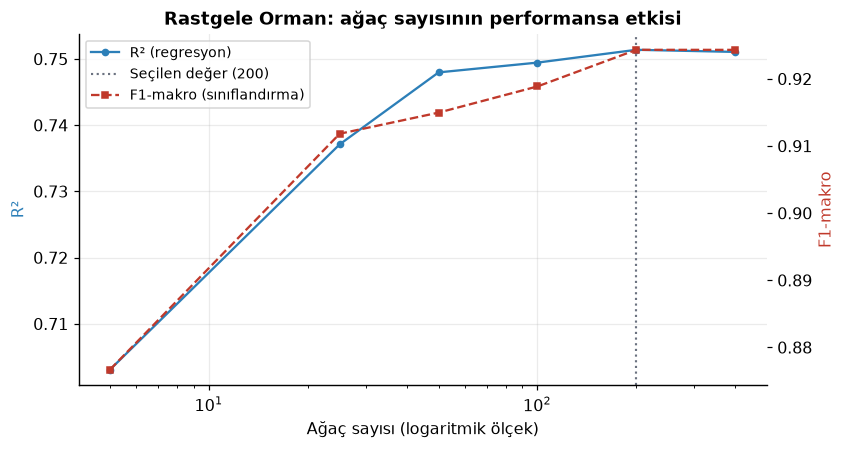

Tarama: [(5, 0.7031, 0.8767), (25, 0.7371, 0.9118), (50, 0.748, 0.915), (100, 0.7495, 0.9189), (200, 0.7514, 0.9243), (400, 0.7511, 0.9243)]


In [50]:
# =============================================================================
# 15.5  Ağaç sayısının etkisi
# =============================================================================
degerler = [5, 25, 50, 100, 200, 400]
r2s, f1s = [], []
for n in degerler:
    r = RandomForestRegressor(n_estimators=n, min_samples_leaf=1, random_state=42, n_jobs=1)
    r2s.append(float(r2_score(yr_te, r.fit(X_tr, yr_tr).predict(X_te))))
    c = RandomForestClassifier(n_estimators=n, min_samples_leaf=1, class_weight="balanced",
                               random_state=42, n_jobs=1)
    f1s.append(float(f1_score(yc_te, c.fit(X_tr, yc_tr).predict(X_te), average="macro")))

duyarlilik_ciz(degerler, r2s, f1s, "Ağaç sayısı (logaritmik ölçek)",
               "Rastgele Orman: ağaç sayısının performansa etkisi", secilen=200, log=True)
print("Tarama:", [(d, round(r, 4), round(f, 4)) for d, r, f in zip(degerler, r2s, f1s)])

In [51]:
# =============================================================================
# 15.6  Sözde mekânsal doğrulama
# =============================================================================
cv = cv_calistir("rastgele_orman",
                 reg_fabrika=lambda: RandomForestRegressor(n_estimators=200, min_samples_leaf=1,
                                                           random_state=42, n_jobs=1),
                 cls_fabrika=lambda: RandomForestClassifier(n_estimators=200, min_samples_leaf=1,
                                                            class_weight="balanced",
                                                            random_state=42, n_jobs=1))

Sözde mekânsal grup doğrulaması — Rastgele Orman (5 kat, yalnızca eğitim kümesi)


  kat 1: eğitim  4023 · sınama  1105 · R² +0.2068 · F1 0.7744


  kat 2: eğitim  4170 · sınama   958 · R² +0.2194 · F1 0.6322


  kat 3: eğitim  4114 · sınama  1014 · R² +0.5672 · F1 0.8412


  kat 4: eğitim  4055 · sınama  1073 · R² +0.4434 · F1 0.8368


  kat 5: eğitim  4150 · sınama   978 · R² +0.5138 · F1 0.8752
  ortalama: R² +0.3901 ± 0.1499 · F1-makro 0.7920 ± 0.0862

KİTAP İLE KARŞILAŞTIRMA — Rastgele Orman
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  CV R² (ortalama)           0.390109   0.390109   -1.88e-07   ✓
  CV R² (std. sapma)         0.149851   0.149851   -4.40e-07   ✓
  CV F1-makro (ort.)         0.791976   0.791976   +3.34e-08   ✓
  CV F1-makro (std.)         0.086248   0.086248   -1.21e-07   ✓
  --------------------------------------------------------------------
  4/4 ölçüt kitaptaki değerle eşleşti (tolerans 1e-05).


## 16. Naive Bayes
<sub>Kitap Bölüm 10 · `notebooks/07_naive_bayes.ipynb` · yalnızca sınıflandırma</sub>

**Kuram.** Bayes teoremini, “özellikler sınıf verildiğinde birbirinden bağımsızdır” varsayımıyla uygular. **GaussianNB** sürümü, her özelliğin her sınıf içinde normal dağıldığını kabul eder. Bu iki varsayım da bu veride açıkça çiğnenir: sıcaklık ile yükseklik birbirine sıkı bağlıdır (yükseldikçe hava soğur), uzaklık değişkenleri sağa çarpıktır, arazi göstergeleri ise yalnızca 0 ya da 1 alır.

**Veri setinde ne yapıyor?** On altı özellik olduğu gibi kullanılır (Gauss dağılımı ölçekten bağımsızdır, standartlaştırma gerekmez). Sınıf önselleri **düzgün** seçilir (`priors=[0.5, 0.5]`): iki sınıfa eşit başlangıç olasılığı. Modelin öğrendiği tek şey, her özellik × sınıf çifti için bir ortalama ve bir varyanstır.

**Kitabın bulgusu.** F1 0,738 ve AUC 0,828 ile lojistik regresyonla neredeyse aynı düzeyde; ama sözde mekânsal doğrulamada en az düşen model (0,690; fark yalnızca 0,048). Bunun nedeni, modelin çok az parametre öğrenmesi ve dolayısıyla bölgeyi ezberleyememesidir. Naive Bayes, “esnek model = iyi model” varsayımının ne kadar kırılgan olduğunu gösteren iyi bir kontrasttır.

> **Sınıflandırma:** doğruluk 0,7395 · F1-makro 0,7381 · AUC 0,8282 · CV F1 0,6904 ± 0,0717

In [52]:
# =============================================================================
# 16.1  Model + test metrikleri
# =============================================================================
from sklearn.naive_bayes import GaussianNB

clf = GaussianNB(priors=[0.5, 0.5])
clf.fit(X_tr, yc_tr)
yp = clf.predict(X_te)

cls = cls_metrikleri(yc_te, yp)
print("Test kümesi — sınıflandırma")
yaz_cls(cls, yc_te, yp)

olasilik = olasilik_al(clf, X_te)
auc = float(roc_auc_score(yr_te, olasilik))
print(f"  {'ROC-AUC':<13}: {auc:.4f}")
OLASILIK["Naive Bayes"] = olasilik
print()
kiyasla("naive_bayes", cls=cls, auc_ek=auc)

Test kümesi — sınıflandırma
  Accuracy     : 0.7395
  BalancedAcc  : 0.7411
  F1_macro     : 0.7381
  F1_weighted  : 0.7378
  Yangın       : duyarlılık 0.8267 · kesinlik 0.6980 · F1 0.7569
  ROC-AUC      : 0.8282

KİTAP İLE KARŞILAŞTIRMA — Naive Bayes
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  AUC (olasılık)             0.828160   0.828160   +1.12e-07   ✓
  Accuracy                   0.739470   0.739470   -4.21e-07   ✓
  BalancedAcc                0.741073   0.741073   -2.45e-07   ✓
  F1_macro                   0.738121   0.738121   -7.48e-08   ✓
  F1_weighted                0.737769   0.737769   +1.03e-07   ✓
  --------------------------------------------------------------------
  5/5 ölçüt kitaptaki değerle eşleşti (tolerans 1e-05).


Karmaşıklık matrisi — Naive Bayes (satır: gerçek, sütun: tahmin)
                       tahmin: Yok  tahmin: Yangın
  gerçek: Yangın Yok           428             225
  gerçek: Yangın               109             520

  eşleşme                 4/4 hücre


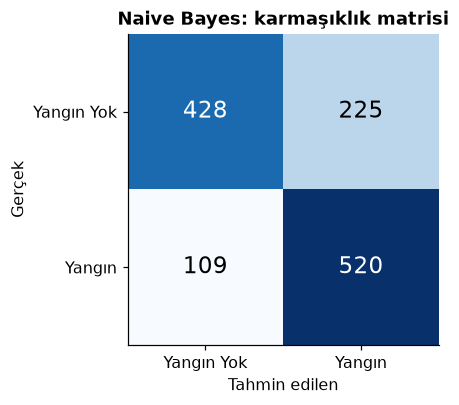

In [53]:
# =============================================================================
# 16.2  Karmaşıklık matrisi
# =============================================================================
cm = km_kiyasla("naive_bayes", yc_te, yp)

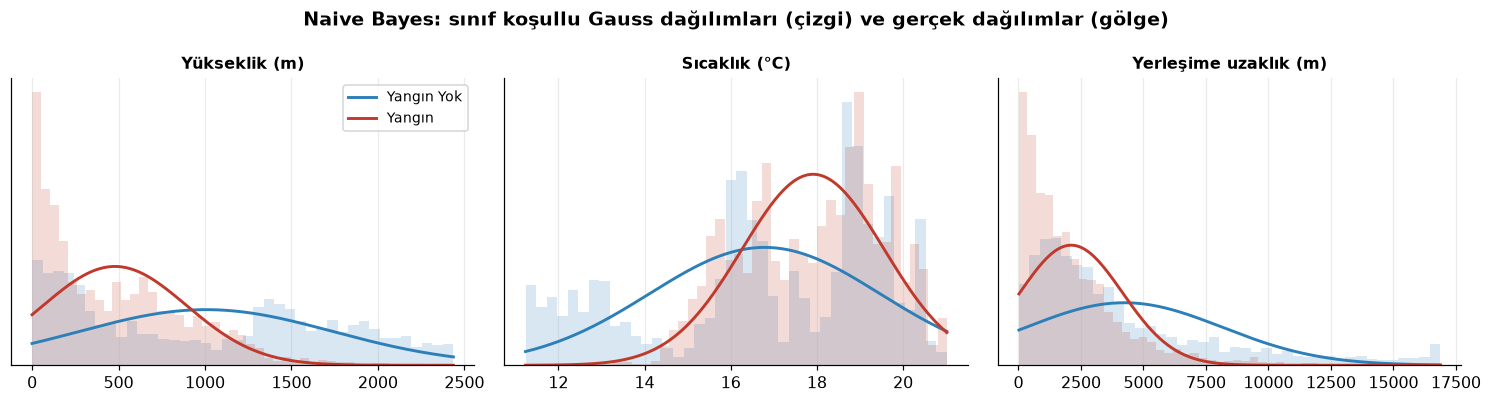

Sınıf ortalamaları:


,Yukseklik,Sicaklik,Yerlesim_Uzaklik
Yangın,478.8500,17.9100,2107.5100
Yangın Yok,1005.8800,16.7900,4230.5900


Çarpıklık (eğitim): {'Yükseklik (m)': 0.77, 'Sıcaklık (°C)': -0.79, 'Yerleşime uzaklık (m)': 1.96}
Yükseklik–sıcaklık korelasyonu: -0.686


In [54]:
# =============================================================================
# 16.3  Sınıf koşullu dağılımlar
# -----------------------------------------------------------------------------
# GaussianNB'nin öğrendiği tek şey her özellik × sınıf için ortalama ve varyans.
# Aşağıdaki eğriler üç özellikte sınıfların ne kadar ayrıştığını gösterir.
# =============================================================================
from scipy import stats

GOSTER = ["Yukseklik", "Sicaklik", "Yerlesim_Uzaklik"]
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.7))
renk = {"Yangın Yok": RENK["yok"], "Yangın": RENK["yangin"]}
for ax, oz in zip(axes, GOSTER):
    j = OZELLIKLER.index(oz)
    alt, ust = float(X_tr[oz].quantile(0.005)), float(X_tr[oz].quantile(0.995))
    xs = np.linspace(alt, ust, 300)
    for et in SINIFLAR:
        i = list(clf.classes_).index(et)
        mu, var = clf.theta_[i, j], clf.var_[i, j]
        ax.hist(X_tr.loc[yc_tr == et, oz].clip(alt, ust), bins=40, density=True,
                color=renk[et], alpha=0.18)
        ax.plot(xs, stats.norm.pdf(xs, mu, np.sqrt(var)), color=renk[et], lw=1.9, label=et)
    ax.set_title(OKUNUR[oz], fontsize=10.5)
    ax.set_yticks([])
axes[0].legend(fontsize=9)
fig.suptitle("Naive Bayes: sınıf koşullu Gauss dağılımları (çizgi) ve gerçek dağılımlar (gölge)",
             fontweight="bold")
fig.tight_layout()
plt.show()

print("Sınıf ortalamaları:")
display(pd.DataFrame(clf.theta_, index=clf.classes_, columns=OZELLIKLER)[GOSTER].round(2))
print("Çarpıklık (eğitim):", {OKUNUR[oz]: round(float(X_tr[oz].skew()), 2) for oz in GOSTER})
print("Yükseklik–sıcaklık korelasyonu:", round(float(X_tr["Yukseklik"].corr(X_tr["Sicaklik"])), 3))

In [55]:
# =============================================================================
# 16.4  Sözde mekânsal doğrulama
# =============================================================================
cv = cv_calistir("naive_bayes", cls_fabrika=lambda: GaussianNB(priors=[0.5, 0.5]))

Sözde mekânsal grup doğrulaması — Naive Bayes (5 kat, yalnızca eğitim kümesi)
  kat 1: eğitim  4023 · sınama  1105 · R² — · F1 0.7186
  kat 2: eğitim  4170 · sınama   958 · R² — · F1 0.5478
  kat 3: eğitim  4114 · sınama  1014 · R² — · F1 0.7375
  kat 4: eğitim  4055 · sınama  1073 · R² — · F1 0.7297
  kat 5: eğitim  4150 · sınama   978 · R² — · F1 0.7185
  ortalama: R² — · F1-makro 0.6904 ± 0.0717

KİTAP İLE KARŞILAŞTIRMA — Naive Bayes
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  CV F1-makro (ort.)         0.690407   0.690407   -2.12e-07   ✓
  CV F1-makro (std.)         0.071665   0.071665   -1.83e-07   ✓
  --------------------------------------------------------------------
  2/2 ölçüt kitaptaki değerle eşleşti (tolerans 1e-05).


## 17. Gradyan Artırma (GBM)
<sub>Kitap Bölüm 11 · `notebooks/08_gbm.ipynb` · regresyon + sınıflandırma</sub>

**Kuram.** GBM, karar ağaçlarını **ardışık** olarak kurar: her yeni ağaç, o ana dek kurulmuş topluluğun hatalarını (kalıntılarını) düzeltmeye çalışır. Bagging'den (Rastgele Orman) temel farkı budur; ağaçlar bağımsız değil, **zincirleme** öğrenir. Yüksek doğruluk verir; buna karşılık eğitimi yavaştır ve öğrenme oranına duyarlıdır.

**Veri setinde ne yapıyor?** 200 ağaç ve **0,3** öğrenme oranı (doğrulama kümesiyle seçildi). Öğrenme oranı her ağacın topluluğa yaptığı katkıyı ölçekler: düşük oran daha yavaş ama güvenli, yüksek oran hızlı yakınsar ve aşırı öğrenme riski taşır. Ölçekleme gerekmez.

**Kitabın bulgusu.** R² 0,726, AUC 0,973, F1 0,924. Klasik GBM, torunları XGBoost/LightGBM/CatBoost'un biraz gerisinde kalır; sözde mekânsal doğrulamada F1 0,768'e düşer. Özellik önemlerinde iklim değişkenlerinin payı %43'tür.

> **Regresyon:** R² 0,7257 · AUC 0,9728 · MSE 0,0685 · CV R² 0,2208 ± 0,2347
> **Sınıflandırma:** doğruluk 0,9236 · F1-makro 0,9235 · CV F1 0,7680 ± 0,0732

In [56]:
# =============================================================================
# 17.1  Regresyon görevi
# =============================================================================
from sklearn.ensemble import GradientBoostingRegressor, GradientBoostingClassifier

reg_model = GradientBoostingRegressor(n_estimators=200, learning_rate=0.3, random_state=42)
reg_model.fit(X_tr, yr_tr)
y_pred = reg_model.predict(X_te)

reg = reg_metrikleri(yr_te, y_pred)
print("Test kümesi — regresyon")
yaz_reg(reg)
print()
kiyasla("gbm", reg=reg, skor=y_pred)

Test kümesi — regresyon
  MAE  : 0.1822
  MSE  : 0.0685
  RMSE : 0.2618
  R2   : 0.7257
  AUC  : 0.9728

KİTAP İLE KARŞILAŞTIRMA — GBM
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  MAE                        0.182165   0.182165   +2.16e-07   ✓
  MSE                        0.068541   0.068541   -5.33e-08   ✓
  RMSE                       0.261803   0.261803   +2.60e-07   ✓
  R2                         0.725740   0.725740   +9.43e-08   ✓
  AUC                        0.972807   0.972807   +4.17e-07   ✓
  --------------------------------------------------------------------
  5/5 ölçüt kitaptaki değerle eşleşti (tolerans 1e-05).


In [57]:
# =============================================================================
# 17.2  Sınıflandırma görevi
# =============================================================================
clf = GradientBoostingClassifier(n_estimators=200, learning_rate=0.3, random_state=42)
clf.fit(X_tr, yc_tr)
yp = clf.predict(X_te)

cls = cls_metrikleri(yc_te, yp)
print("Test kümesi — sınıflandırma")
yaz_cls(cls, yc_te, yp)
OLASILIK["GBM"] = olasilik_al(clf, X_te)
print()
kiyasla("gbm", cls=cls)

Test kümesi — sınıflandırma
  Accuracy     : 0.9236
  BalancedAcc  : 0.9234
  F1_macro     : 0.9235
  F1_weighted  : 0.9235
  Yangın       : duyarlılık 0.9173 · kesinlik 0.9262 · F1 0.9217

KİTAP İLE KARŞILAŞTIRMA — GBM
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  Accuracy                   0.923557   0.923557   -5.77e-08   ✓
  BalancedAcc                0.923442   0.923442   +4.95e-07   ✓
  F1_macro                   0.923515   0.923515   +5.88e-08   ✓
  F1_weighted                0.923549   0.923549   -4.34e-07   ✓
  --------------------------------------------------------------------
  4/4 ölçüt kitaptaki değerle eşleşti (tolerans 1e-05).


Karmaşıklık matrisi — GBM (satır: gerçek, sütun: tahmin)
                       tahmin: Yok  tahmin: Yangın
  gerçek: Yangın Yok           607              46
  gerçek: Yangın                52             577

  eşleşme                 4/4 hücre


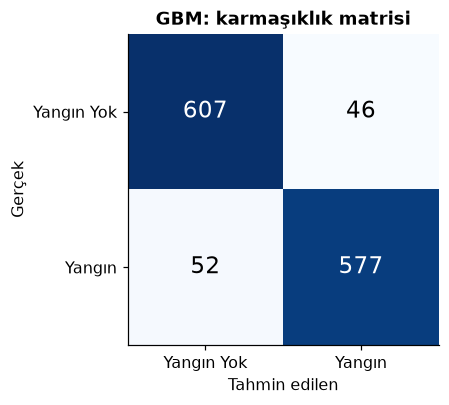

In [58]:
# =============================================================================
# 17.3  Karmaşıklık matrisi
# =============================================================================
cm = km_kiyasla("gbm", yc_te, yp)

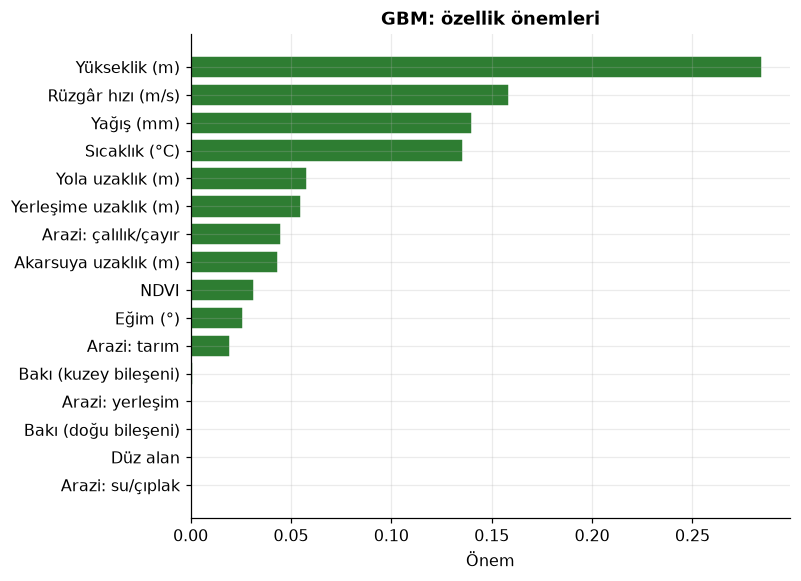

,önem,pay (%)
Yukseklik,0.2800,28.4500
Ruzgar_Hizi,0.1600,15.8400
Yagis,0.1400,14.0000
Sicaklik,0.1400,13.5600
Yol_Uzaklik,0.0600,5.8000
Yerlesim_Uzaklik,0.0500,5.5000
Arazi_Calilik,0.0400,4.4800
Akarsu_Uzaklik,0.0400,4.3300
NDVI,0.0300,3.1700
Egim,0.0300,2.6200


Üç iklim değişkeninin toplam payı: %43.4


In [59]:
# =============================================================================
# 17.4  Özellik önemleri
# =============================================================================
onem = pd.Series(clf.feature_importances_, index=OZELLIKLER)
onem_ciz(clf.feature_importances_, "GBM: özellik önemleri")
display(pd.DataFrame({"önem": onem, "pay (%)": 100 * onem / onem.sum()})
        .sort_values("önem", ascending=False).round(2))
print(f"Üç iklim değişkeninin toplam payı: %{100 * onem[IKLIM].sum() / onem.sum():.1f}")

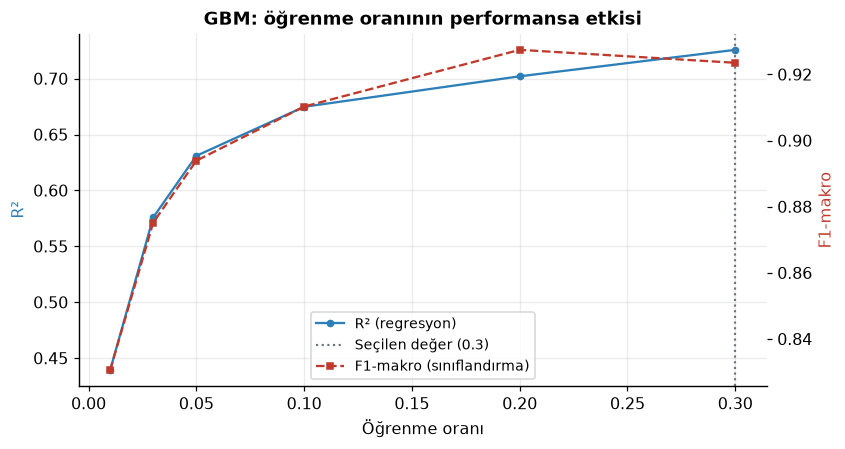

Tarama: [(0.01, 0.4391, 0.8305), (0.03, 0.5759, 0.8752), (0.05, 0.6309, 0.8939), (0.1, 0.6748, 0.9103), (0.2, 0.7021, 0.9274), (0.3, 0.7257, 0.9235)]


In [60]:
# =============================================================================
# 17.5  Öğrenme oranının etkisi
# =============================================================================
degerler = [0.01, 0.03, 0.05, 0.1, 0.2, 0.3]
r2s, f1s = [], []
for lr_ in degerler:
    r = GradientBoostingRegressor(n_estimators=200, learning_rate=lr_, random_state=42)
    r2s.append(float(r2_score(yr_te, r.fit(X_tr, yr_tr).predict(X_te))))
    c = GradientBoostingClassifier(n_estimators=200, learning_rate=lr_, random_state=42)
    f1s.append(float(f1_score(yc_te, c.fit(X_tr, yc_tr).predict(X_te), average="macro")))

duyarlilik_ciz(degerler, r2s, f1s, "Öğrenme oranı",
               "GBM: öğrenme oranının performansa etkisi", secilen=0.3)
print("Tarama:", [(d, round(r, 4), round(f, 4)) for d, r, f in zip(degerler, r2s, f1s)])

In [61]:
# =============================================================================
# 17.6  Sözde mekânsal doğrulama
# =============================================================================
cv = cv_calistir("gbm",
                 reg_fabrika=lambda: GradientBoostingRegressor(n_estimators=200, learning_rate=0.3,
                                                               random_state=42),
                 cls_fabrika=lambda: GradientBoostingClassifier(n_estimators=200, learning_rate=0.3,
                                                                random_state=42))

Sözde mekânsal grup doğrulaması — GBM (5 kat, yalnızca eğitim kümesi)


  kat 1: eğitim  4023 · sınama  1105 · R² -0.0434 · F1 0.7122


  kat 2: eğitim  4170 · sınama   958 · R² -0.0835 · F1 0.6553


  kat 3: eğitim  4114 · sınama  1014 · R² +0.4654 · F1 0.8287


  kat 4: eğitim  4055 · sınama  1073 · R² +0.4001 · F1 0.8488


  kat 5: eğitim  4150 · sınama   978 · R² +0.3655 · F1 0.7950
  ortalama: R² +0.2208 ± 0.2347 · F1-makro 0.7680 ± 0.0732

KİTAP İLE KARŞILAŞTIRMA — GBM
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  CV R² (ortalama)           0.220838   0.220838   +1.49e-07   ✓
  CV R² (std. sapma)         0.234670   0.234670   +8.34e-08   ✓
  CV F1-makro (ort.)         0.767979   0.767979   +3.30e-07   ✓
  CV F1-makro (std.)         0.073158   0.073158   +4.33e-07   ✓
  --------------------------------------------------------------------
  4/4 ölçüt kitaptaki değerle eşleşti (tolerans 1e-05).


## 18. XGBoost
<sub>Kitap Bölüm 12 · `notebooks/09_xgboost.ipynb` · regresyon + sınıflandırma</sub>

**Kuram.** XGBoost (eXtreme Gradient Boosting), gradyan artırmanın **ikinci dereceden (Newton) adımlar**, düzenlileştirme, paralelleştirme ve eksik veri desteğiyle güçlendirilmiş mühendislik sürümüdür. Veri bilimi yarışmalarında yaygın biçimde öne çıkmıştır. scikit-learn ile aynı `fit`/`predict` arayüzünü kullanır; tek farkı sınıf etiketlerinin **sayısal** olmasını istemesidir.

**Veri setinde ne yapıyor?** 0,1 öğrenme oranı ve **400** artırma turu (doğrulama kümesiyle seçildi). Sınıflandırmada etiketler 0/1 koduna çevrilir, tahmin yeniden etikete dönüştürülür. Ölçekleme gerekmez. Önemler, XGBoost'un varsayılan ölçütü olan bölünme kazancına (gain) göre verilir.

**Kitabın bulgusu.** Rastgele test kümesinde **en iyi model**: R² 0,798, AUC 0,984, F1 0,947. Ancak sözde mekânsal doğrulamada F1 0,781'e düşer ve dördüncülüğe geriler; düşüş (0,166) bütün modeller arasında en büyüktür. Bu, kitabın en önemli uyarısıdır: rastgele bölünmedeki birincilik, yeni bölgelere taşınmayabilir.

> **Regresyon:** R² 0,7979 · AUC 0,9843 · MSE 0,0505 · CV R² 0,2817 ± 0,2085
> **Sınıflandırma:** doğruluk 0,9470 · F1-makro 0,9469 · CV F1 0,7814 ± 0,0783

In [62]:
# =============================================================================
# 18.1  Regresyon görevi
# =============================================================================
from xgboost import XGBRegressor, XGBClassifier

reg_model = XGBRegressor(n_estimators=400, learning_rate=0.1, random_state=42, verbosity=0)
reg_model.fit(X_tr, yr_tr)
y_pred = reg_model.predict(X_te)

reg = reg_metrikleri(yr_te, y_pred)
print("Test kümesi — regresyon")
yaz_reg(reg)
print()
kiyasla("xgboost", reg=reg, skor=y_pred)

Test kümesi — regresyon
  MAE  : 0.1391
  MSE  : 0.0505
  RMSE : 0.2247
  R2   : 0.7979
  AUC  : 0.9843

KİTAP İLE KARŞILAŞTIRMA — XGBoost
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  MAE                        0.139114   0.139114   -1.70e-08   ✓
  MSE                        0.050512   0.050512   +2.89e-07   ✓
  RMSE                       0.224749   0.224749   +3.92e-07   ✓
  R2                         0.797880   0.797880   +6.64e-09   ✓
  AUC                        0.984321   0.984321   -1.33e-07   ✓
  --------------------------------------------------------------------
  5/5 ölçüt kitaptaki değerle eşleşti (tolerans 1e-05).


In [63]:
# =============================================================================
# 18.2  Sınıflandırma görevi
# -----------------------------------------------------------------------------
# XGBoost sayısal etiket ister: 0 = Yangın Yok, 1 = Yangın.
# =============================================================================
clf = XGBClassifier(n_estimators=400, learning_rate=0.1, random_state=42, verbosity=0)
clf.fit(X_tr, kod(yc_tr))
yp = sinifa(clf.predict(X_te))

cls = cls_metrikleri(yc_te, yp)
print("Test kümesi — sınıflandırma")
yaz_cls(cls, yc_te, yp)
OLASILIK["XGBoost"] = olasilik_al(clf, X_te)
print()
kiyasla("xgboost", cls=cls)

Test kümesi — sınıflandırma
  Accuracy     : 0.9470
  BalancedAcc  : 0.9469
  F1_macro     : 0.9469
  F1_weighted  : 0.9470
  Yangın       : duyarlılık 0.9444 · kesinlik 0.9474 · F1 0.9459

KİTAP İLE KARŞILAŞTIRMA — XGBoost
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  Accuracy                   0.946958   0.946958   -1.22e-07   ✓
  BalancedAcc                0.946910   0.946910   +6.65e-08   ✓
  F1_macro                   0.946936   0.946936   +5.25e-08   ✓
  F1_weighted                0.946956   0.946956   +1.99e-07   ✓
  --------------------------------------------------------------------
  4/4 ölçüt kitaptaki değerle eşleşti (tolerans 1e-05).


Karmaşıklık matrisi — XGBoost (satır: gerçek, sütun: tahmin)
                       tahmin: Yok  tahmin: Yangın
  gerçek: Yangın Yok           620              33
  gerçek: Yangın                35             594

  eşleşme                 4/4 hücre


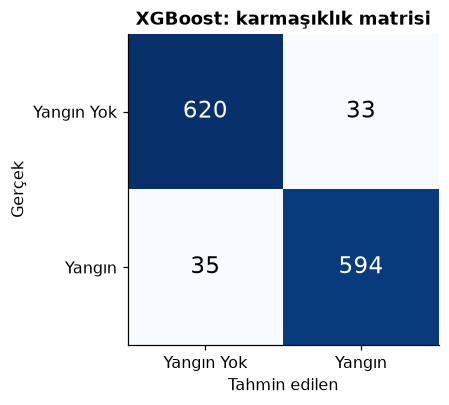

In [64]:
# =============================================================================
# 18.3  Karmaşıklık matrisi
# =============================================================================
cm = km_kiyasla("xgboost", yc_te, yp)

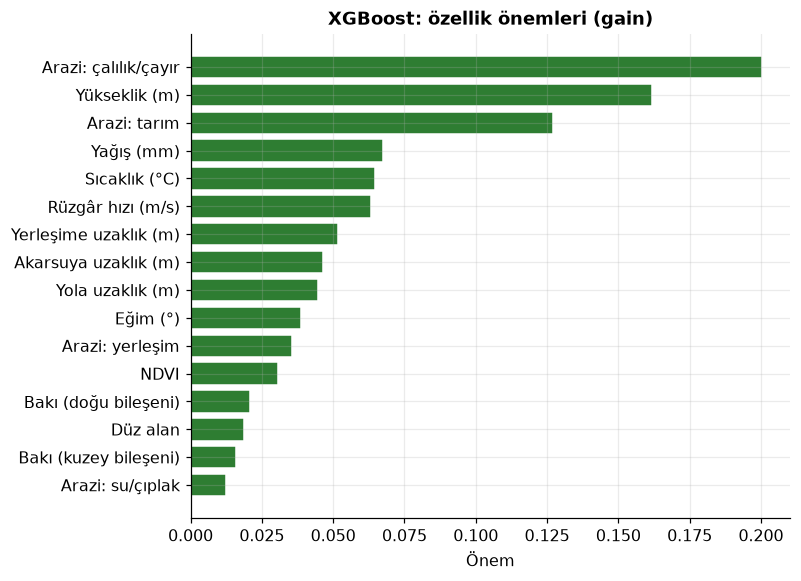

,önem,pay (%)
Arazi_Calilik,0.2000,20.0300
Yukseklik,0.1600,16.1900
Arazi_Tarim,0.1300,12.7000
Yagis,0.0700,6.7400
Sicaklik,0.0600,6.4600
Ruzgar_Hizi,0.0600,6.3400
Yerlesim_Uzaklik,0.0500,5.1700
Akarsu_Uzaklik,0.0500,4.6500
Yol_Uzaklik,0.0400,4.4600
Egim,0.0400,3.8700


Üç iklim değişkeninin toplam payı: %19.5


In [65]:
# =============================================================================
# 18.4  Özellik önemleri
# =============================================================================
onem = pd.Series(clf.feature_importances_, index=OZELLIKLER)
onem_ciz(clf.feature_importances_, "XGBoost: özellik önemleri (gain)")
display(pd.DataFrame({"önem": onem, "pay (%)": 100 * onem / onem.sum()})
        .sort_values("önem", ascending=False).round(2))
print(f"Üç iklim değişkeninin toplam payı: %{100 * onem[IKLIM].sum() / onem.sum():.1f}")

,eşik,doğruluk,F1-makro,kesinlik,duyarlılık
0,0.3000,0.9399,0.9399,0.9182,0.9634
1,0.3500,0.9407,0.9407,0.9274,0.9539
2,0.4000,0.9446,0.9446,0.9359,0.9523
3,0.4500,0.9446,0.9446,0.9401,0.9475
4,0.5000,0.9470,0.9469,0.9474,0.9444
5,0.5500,0.9462,0.9461,0.9545,0.9348
6,0.6000,0.9423,0.9422,0.9633,0.9173
7,0.6500,0.9368,0.9367,0.9644,0.9046
8,0.7000,0.9353,0.9350,0.9723,0.8935


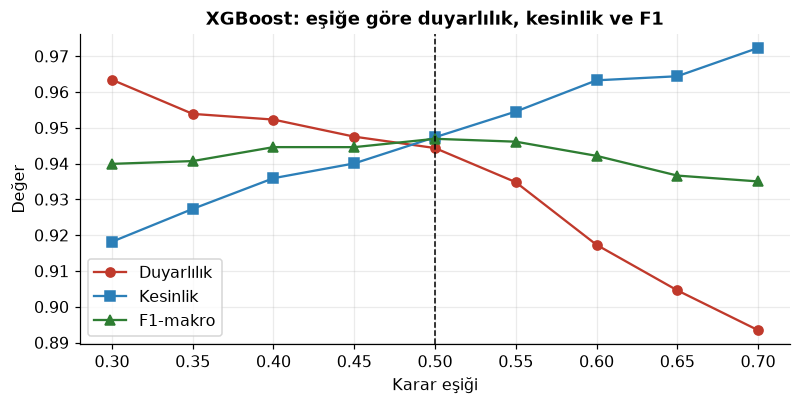

In [66]:
# =============================================================================
# 18.5  Karar eşiğinin etkisi (kitapta eşik 0,5'tir)
# -----------------------------------------------------------------------------
# Sınıflandırıcı 0,5 eşiğini kullanır. Eşik düşürülürse duyarlılık artar,
# kesinlik düşer; yükseltilirse tersi olur. Operasyonel kullanımda bu denge
# uygulamanın amacına göre seçilir.
# =============================================================================
p = OLASILIK["XGBoost"]
satirlar = []
for esik in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:
    tahmin = np.where(p >= esik, "Yangın", "Yangın Yok")
    m, y = cls_metrikleri(yc_te, tahmin), yangin_metrikleri(yc_te, tahmin)
    satirlar.append({"eşik": esik, "doğruluk": m["Accuracy"], "F1-makro": m["F1_macro"],
                     "kesinlik": y["kesinlik"], "duyarlılık": y["duyarlilik"]})
esik_tablo = pd.DataFrame(satirlar)
display(esik_tablo.round(4))

fig, ax = plt.subplots(figsize=(7.4, 3.8))
ax.plot(esik_tablo["eşik"], esik_tablo["duyarlılık"], "o-", color=RENK["yangin"], label="Duyarlılık")
ax.plot(esik_tablo["eşik"], esik_tablo["kesinlik"], "s-", color=RENK["yok"], label="Kesinlik")
ax.plot(esik_tablo["eşik"], esik_tablo["F1-makro"], "^-", color=RENK["vurgu"], label="F1-makro")
ax.axvline(0.5, color="k", ls="--", lw=1)
ax.set_xlabel("Karar eşiği")
ax.set_ylabel("Değer")
ax.set_title("XGBoost: eşiğe göre duyarlılık, kesinlik ve F1")
ax.legend()
fig.tight_layout()
plt.show()

In [67]:
# =============================================================================
# 18.6  Sözde mekânsal doğrulama
# =============================================================================
cv = cv_calistir("xgboost",
                 reg_fabrika=lambda: XGBRegressor(n_estimators=400, learning_rate=0.1,
                                                  random_state=42, verbosity=0),
                 cls_fabrika=lambda: XGBClassifier(n_estimators=400, learning_rate=0.1,
                                                   random_state=42, verbosity=0),
                 kodlu=True)

Sözde mekânsal grup doğrulaması — XGBoost (5 kat, yalnızca eğitim kümesi)


  kat 1: eğitim  4023 · sınama  1105 · R² -0.0008 · F1 0.7393


  kat 2: eğitim  4170 · sınama   958 · R² +0.0714 · F1 0.6465


  kat 3: eğitim  4114 · sınama  1014 · R² +0.5232 · F1 0.8521


  kat 4: eğitim  4055 · sınama  1073 · R² +0.3657 · F1 0.8389


  kat 5: eğitim  4150 · sınama   978 · R² +0.4491 · F1 0.8301
  ortalama: R² +0.2817 ± 0.2085 · F1-makro 0.7814 ± 0.0783

KİTAP İLE KARŞILAŞTIRMA — XGBoost
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  CV R² (ortalama)           0.281749   0.281749   -2.46e-07   ✓
  CV R² (std. sapma)         0.208523   0.208523   -4.74e-07   ✓
  CV F1-makro (ort.)         0.781390   0.781390   +1.66e-07   ✓
  CV F1-makro (std.)         0.078304   0.078304   -1.06e-07   ✓
  --------------------------------------------------------------------
  4/4 ölçüt kitaptaki değerle eşleşti (tolerans 1e-05).


## 19. CatBoost
<sub>Kitap Bölüm 13 · `notebooks/10_catboost.ipynb` · regresyon + sınıflandırma</sub>

**Kuram.** CatBoost (Yandex), kategorik değişkenleri ön işlemeye gerek kalmadan işleyebilen ve **ordered boosting** tekniğiyle hedef sızıntısını ve aşırı öğrenmeyi azaltan bir gradyan artırma kütüphanesidir. Simetrik (oblivious) ağaçlar kullanır: aynı seviyedeki bütün düğümler aynı soruyu sorar. Varsayılan ayarlarıyla dahi çoğu zaman iyi sonuç vermesiyle tanınır.

**Veri setinde ne yapıyor?** Varsayılan 1.000 tur ve **depth = 8** (doğrulama kümesiyle seçildi). Kategorik değişkenler bu defterde önceden kodlandığı için CatBoost'un kategorik desteği kullanılmaz; model 16 sayısal özellikle çalışır. Etiketler 0/1 kodlanır.

**Kitabın bulgusu.** Rastgele testte XGBoost'un hemen ardından ikinci (R² 0,799, AUC 0,984, F1 0,942); **sözde mekânsal doğrulamada ise birinci** (F1 0,805). Yani yeni bölgelere en iyi genellenen model CatBoost'tur. Özellik önemlerinde iklim değişkenlerinin payı %52,5 ile en yüksektir; buna karşın yeni bölgelerde en iyi genellenen model olması, bu bilgiyi ezberlemek yerine daha dengeli kullandığını düşündürür.

> **Regresyon:** R² 0,7992 · AUC 0,9835 · MSE 0,0502 · CV R² 0,4250 ± 0,1442
> **Sınıflandırma:** doğruluk 0,9415 · F1-makro 0,9415 · CV F1 0,8053 ± 0,0773

In [68]:
# =============================================================================
# 19.1  Regresyon görevi
# =============================================================================
from catboost import CatBoostRegressor, CatBoostClassifier

reg_model = CatBoostRegressor(depth=8, random_state=42, verbose=0)
reg_model.fit(X_tr, yr_tr)
y_pred = reg_model.predict(X_te)

reg = reg_metrikleri(yr_te, y_pred)
print("Test kümesi — regresyon")
yaz_reg(reg)
print()
kiyasla("catboost", reg=reg, skor=y_pred)

Test kümesi — regresyon
  MAE  : 0.1408
  MSE  : 0.0502
  RMSE : 0.2240
  R2   : 0.7992
  AUC  : 0.9835

KİTAP İLE KARŞILAŞTIRMA — CatBoost
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  MAE                        0.140797   0.140797   +4.80e-07   ✓
  MSE                        0.050193   0.050193   -4.18e-07   ✓
  RMSE                       0.224037   0.224037   +1.07e-08   ✓
  R2                         0.799159   0.799159   +2.83e-07   ✓
  AUC                        0.983496   0.983496   -4.79e-07   ✓
  --------------------------------------------------------------------
  5/5 ölçüt kitaptaki değerle eşleşti (tolerans 1e-05).


In [69]:
# =============================================================================
# 19.2  Sınıflandırma görevi
# =============================================================================
clf = CatBoostClassifier(depth=8, random_state=42, verbose=0)
clf.fit(X_tr, kod(yc_tr))
yp = sinifa(clf.predict(X_te))

cls = cls_metrikleri(yc_te, yp)
print("Test kümesi — sınıflandırma")
yaz_cls(cls, yc_te, yp)
OLASILIK["CatBoost"] = olasilik_al(clf, X_te)
print()
kiyasla("catboost", cls=cls)

Test kümesi — sınıflandırma
  Accuracy     : 0.9415
  BalancedAcc  : 0.9415
  F1_macro     : 0.9415
  F1_weighted  : 0.9415
  Yangın       : duyarlılık 0.9412 · kesinlik 0.9397 · F1 0.9404

KİTAP İLE KARŞILAŞTIRMA — CatBoost
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  Accuracy                   0.941498   0.941498   -3.40e-07   ✓
  BalancedAcc                0.941492   0.941492   -2.43e-07   ✓
  F1_macro                   0.941479   0.941479   -1.76e-07   ✓
  F1_weighted                0.941498   0.941498   +4.79e-07   ✓
  --------------------------------------------------------------------
  4/4 ölçüt kitaptaki değerle eşleşti (tolerans 1e-05).


Karmaşıklık matrisi — CatBoost (satır: gerçek, sütun: tahmin)
                       tahmin: Yok  tahmin: Yangın
  gerçek: Yangın Yok           615              38
  gerçek: Yangın                37             592

  eşleşme                 4/4 hücre


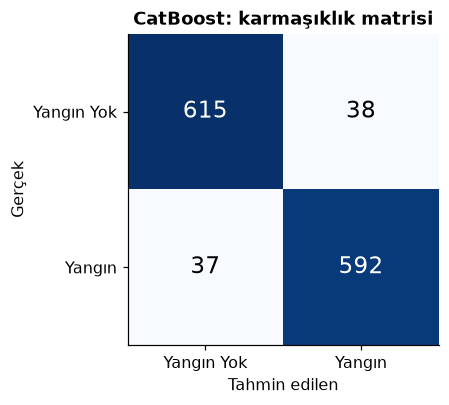

In [70]:
# =============================================================================
# 19.3  Karmaşıklık matrisi
# =============================================================================
cm = km_kiyasla("catboost", yc_te, yp)

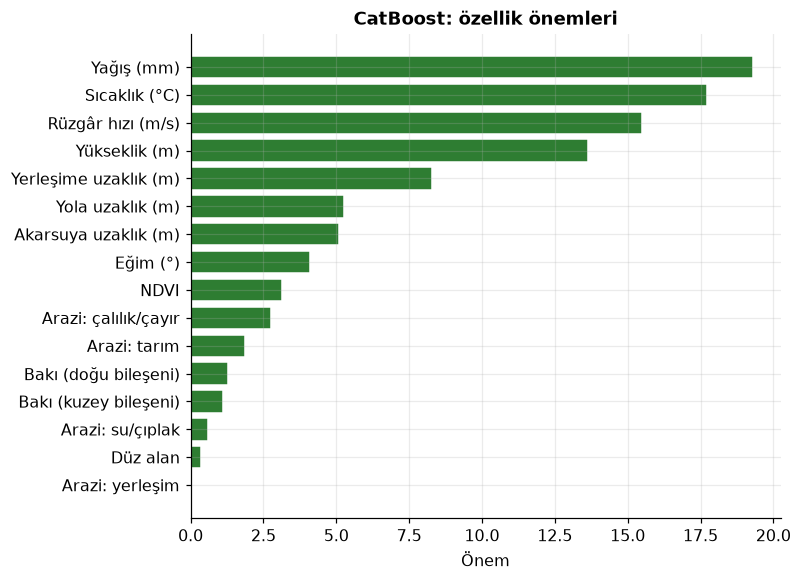

,önem,pay (%)
Yagis,19.2800,19.2800
Sicaklik,17.7100,17.7100
Ruzgar_Hizi,15.4800,15.4800
Yukseklik,13.6300,13.6300
Yerlesim_Uzaklik,8.2900,8.2900
Yol_Uzaklik,5.2500,5.2500
Akarsu_Uzaklik,5.1100,5.1100
Egim,4.1000,4.1000
NDVI,3.1300,3.1300
Arazi_Calilik,2.7500,2.7500


Üç iklim değişkeninin toplam payı: %52.5  (kitap: %52,5)


In [71]:
# =============================================================================
# 19.4  Özellik önemleri
# -----------------------------------------------------------------------------
# CatBoost'un varsayılan ölçütü tahmin değişimidir (PredictionValuesChange).
# =============================================================================
onem = pd.Series(clf.feature_importances_, index=OZELLIKLER)
onem_ciz(clf.feature_importances_, "CatBoost: özellik önemleri")
display(pd.DataFrame({"önem": onem, "pay (%)": 100 * onem / onem.sum()})
        .sort_values("önem", ascending=False).round(2))
print(f"Üç iklim değişkeninin toplam payı: %{100 * onem[IKLIM].sum() / onem.sum():.1f}  (kitap: %52,5)")

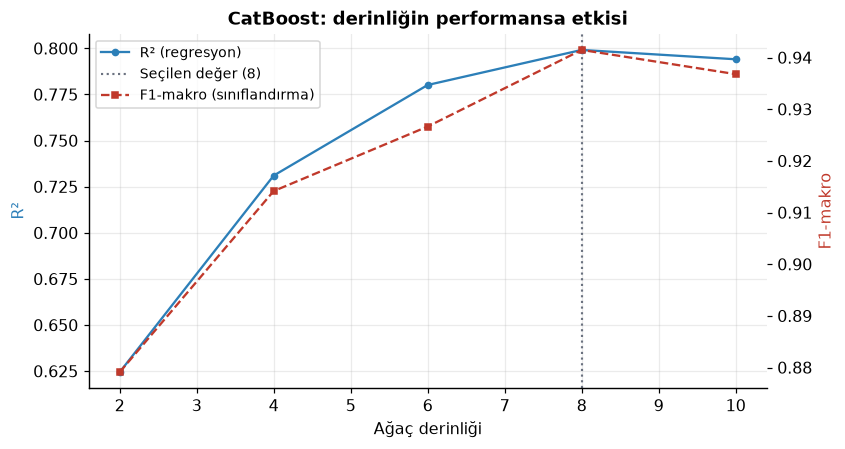

Tarama: [(2, 0.6244, 0.8791), (4, 0.731, 0.9142), (6, 0.7802, 0.9266), (8, 0.7992, 0.9415), (10, 0.7941, 0.9368)]


In [72]:
# =============================================================================
# 19.5  Ağaç derinliğinin etkisi
# -----------------------------------------------------------------------------
# Simetrik ağaçta derinlik, modelin yakalayabileceği etkileşimlerin
# karmaşıklığını belirler. Aşırı derinlik ezberlemeye yol açar.
# =============================================================================
degerler = [2, 4, 6, 8, 10]
r2s, f1s = [], []
for dd in degerler:
    r = CatBoostRegressor(depth=dd, random_state=42, verbose=0)
    r2s.append(float(r2_score(yr_te, r.fit(X_tr, yr_tr).predict(X_te))))
    c = CatBoostClassifier(depth=dd, random_state=42, verbose=0)
    f1s.append(float(f1_score(yc_te, sinifa(c.fit(X_tr, kod(yc_tr)).predict(X_te)), average="macro")))

duyarlilik_ciz(degerler, r2s, f1s, "Ağaç derinliği",
               "CatBoost: derinliğin performansa etkisi", secilen=8)
print("Tarama:", [(d, round(r, 4), round(f, 4)) for d, r, f in zip(degerler, r2s, f1s)])

In [73]:
# =============================================================================
# 19.6  Sözde mekânsal doğrulama
# =============================================================================
cv = cv_calistir("catboost",
                 reg_fabrika=lambda: CatBoostRegressor(depth=8, random_state=42, verbose=0),
                 cls_fabrika=lambda: CatBoostClassifier(depth=8, random_state=42, verbose=0),
                 kodlu=True)

Sözde mekânsal grup doğrulaması — CatBoost (5 kat, yalnızca eğitim kümesi)


  kat 1: eğitim  4023 · sınama  1105 · R² +0.2909 · F1 0.7728


  kat 2: eğitim  4170 · sınama   958 · R² +0.2198 · F1 0.6690


  kat 3: eğitim  4114 · sınama  1014 · R² +0.5746 · F1 0.8591


  kat 4: eğitim  4055 · sınama  1073 · R² +0.4775 · F1 0.8434


  kat 5: eğitim  4150 · sınama   978 · R² +0.5619 · F1 0.8822
  ortalama: R² +0.4249 ± 0.1442 · F1-makro 0.8053 ± 0.0773

KİTAP İLE KARŞILAŞTIRMA — CatBoost
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  CV R² (ortalama)           0.424950   0.424950   -2.71e-07   ✓
  CV R² (std. sapma)         0.144213   0.144213   -2.07e-07   ✓
  CV F1-makro (ort.)         0.805315   0.805315   -2.60e-07   ✓
  CV F1-makro (std.)         0.077310   0.077310   +1.54e-07   ✓
  --------------------------------------------------------------------
  4/4 ölçüt kitaptaki değerle eşleşti (tolerans 1e-05).


## 20. LightGBM
<sub>Kitap Bölüm 14 · `notebooks/11_lightgbm.ipynb` · regresyon + sınıflandırma</sub>

**Kuram.** LightGBM (Microsoft), gradyan artırmayı hız ve bellek verimliliği için optimize eder: **histogram tabanlı bölme** ve **yaprak öncelikli (leaf-wise)** ağaç büyütme kullanır. Büyük veri setlerinde rakiplerinden kat kat hızlıdır; yaprak öncelikli büyüme, küçük veri setlerinde aşırı öğrenmeye karşı biraz daha hassastır.

**Veri setinde ne yapıyor?** Varsayılan 100 tur ve **num_leaves = 127** (doğrulama kümesiyle seçildi). Yaprak öncelikli büyüdüğü için temel karmaşıklık denetimi ağaç sayısı değil yaprak sayısıdır. Sınıflandırmada dengeli sınıf ağırlıkları ve 0/1 kodlanmış etiketler kullanılır.

**Kitabın bulgusu.** R² 0,783, AUC 0,980, F1 0,942; sözde mekânsal doğrulamada F1 0,800 ile CatBoost'un hemen ardından ikinci. Yani hızlı ve hafif olmasına karşın, genelleme bakımından en iyi iki modelden biri.

> **Regresyon:** R² 0,7831 · AUC 0,9802 · MSE 0,0542 · CV R² 0,4108 ± 0,1494
> **Sınıflandırma:** doğruluk 0,9415 · F1-makro 0,9415 · CV F1 0,7999 ± 0,0720

In [74]:
# =============================================================================
# 20.1  Regresyon görevi
# =============================================================================
from lightgbm import LGBMRegressor, LGBMClassifier

reg_model = LGBMRegressor(num_leaves=127, random_state=42, verbose=-1)
reg_model.fit(X_tr, yr_tr)
y_pred = reg_model.predict(X_te)

reg = reg_metrikleri(yr_te, y_pred)
print("Test kümesi — regresyon")
yaz_reg(reg)
print()
kiyasla("lightgbm", reg=reg, skor=y_pred)

Test kümesi — regresyon
  MAE  : 0.1414
  MSE  : 0.0542
  RMSE : 0.2328
  R2   : 0.7831
  AUC  : 0.9802

KİTAP İLE KARŞILAŞTIRMA — LightGBM
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  MAE                        0.141391   0.141391   +2.27e-07   ✓
  MSE                        0.054201   0.054201   -1.91e-07   ✓
  RMSE                       0.232811   0.232811   -3.28e-07   ✓
  R2                         0.783121   0.783121   -2.45e-07   ✓
  AUC                        0.980201   0.980201   +4.43e-07   ✓
  --------------------------------------------------------------------
  5/5 ölçüt kitaptaki değerle eşleşti (tolerans 1e-05).


In [75]:
# =============================================================================
# 20.2  Sınıflandırma görevi
# =============================================================================
clf = LGBMClassifier(num_leaves=127, class_weight="balanced", random_state=42, verbose=-1)
clf.fit(X_tr, kod(yc_tr))
yp = sinifa(clf.predict(X_te))

cls = cls_metrikleri(yc_te, yp)
print("Test kümesi — sınıflandırma")
yaz_cls(cls, yc_te, yp)
OLASILIK["LightGBM"] = olasilik_al(clf, X_te)
print()
kiyasla("lightgbm", cls=cls)

Test kümesi — sınıflandırma
  Accuracy     : 0.9415
  BalancedAcc  : 0.9414
  F1_macro     : 0.9415
  F1_weighted  : 0.9415
  Yangın       : duyarlılık 0.9348 · kesinlik 0.9453 · F1 0.9400

KİTAP İLE KARŞILAŞTIRMA — LightGBM
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  Accuracy                   0.941498   0.941498   -3.40e-07   ✓
  BalancedAcc                0.941375   0.941375   -1.06e-07   ✓
  F1_macro                   0.941463   0.941463   +4.32e-07   ✓
  F1_weighted                0.941490   0.941490   -6.89e-08   ✓
  --------------------------------------------------------------------
  4/4 ölçüt kitaptaki değerle eşleşti (tolerans 1e-05).


Karmaşıklık matrisi — LightGBM (satır: gerçek, sütun: tahmin)
                       tahmin: Yok  tahmin: Yangın
  gerçek: Yangın Yok           619              34
  gerçek: Yangın                41             588

  eşleşme                 4/4 hücre


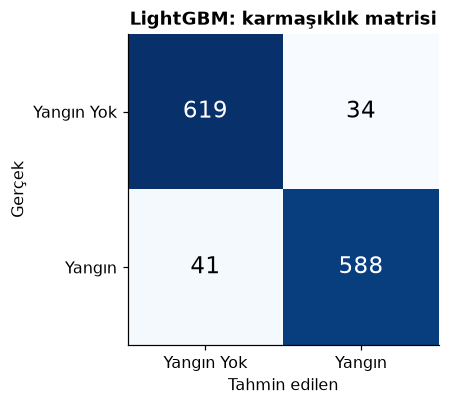

In [76]:
# =============================================================================
# 20.3  Karmaşıklık matrisi
# =============================================================================
cm = km_kiyasla("lightgbm", yc_te, yp)

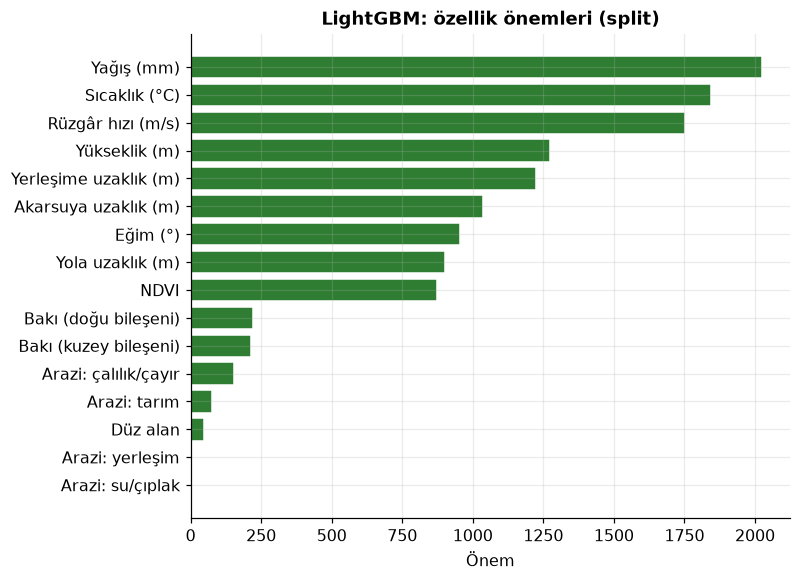

,önem,pay (%)
Yagis,2024,16.0600
Sicaklik,1843,14.6300
Ruzgar_Hizi,1753,13.9100
Yukseklik,1273,10.1000
Yerlesim_Uzaklik,1225,9.7200
Akarsu_Uzaklik,1037,8.2300
Egim,954,7.5700
Yol_Uzaklik,902,7.1600
NDVI,872,6.9200
Baki_Sin,222,1.7600


Üç iklim değişkeninin toplam payı: %44.6


In [77]:
# =============================================================================
# 20.4  Özellik önemleri
# -----------------------------------------------------------------------------
# LightGBM'in varsayılan ölçütü, özelliğin bölünmelerde kullanılma sayısıdır (split).
# =============================================================================
onem = pd.Series(clf.feature_importances_, index=OZELLIKLER)
onem_ciz(clf.feature_importances_, "LightGBM: özellik önemleri (split)")
display(pd.DataFrame({"önem": onem, "pay (%)": 100 * onem / onem.sum()})
        .sort_values("önem", ascending=False).round(2))
print(f"Üç iklim değişkeninin toplam payı: %{100 * onem[IKLIM].sum() / onem.sum():.1f}")

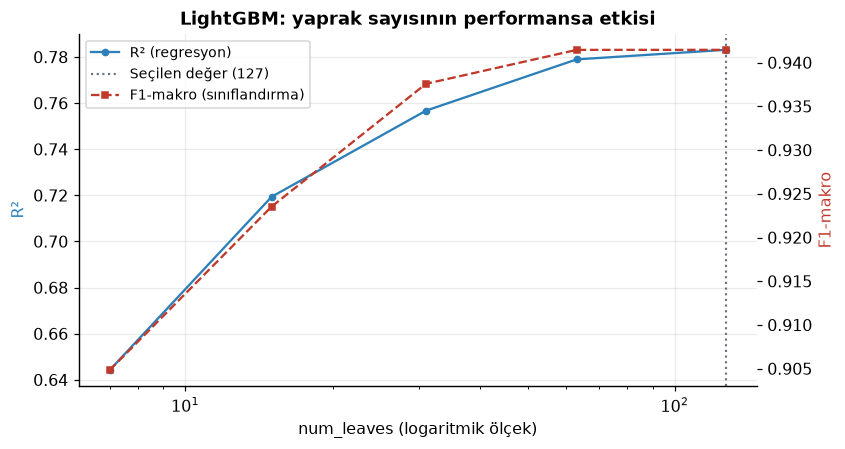

Tarama: [(7, 0.6442, 0.9048), (15, 0.7194, 0.9235), (31, 0.7567, 0.9376), (63, 0.779, 0.9415), (127, 0.7831, 0.9415)]


In [78]:
# =============================================================================
# 20.5  Yaprak sayısının etkisi
# =============================================================================
degerler = [7, 15, 31, 63, 127]
r2s, f1s = [], []
for nl_ in degerler:
    r = LGBMRegressor(num_leaves=nl_, random_state=42, verbose=-1)
    r2s.append(float(r2_score(yr_te, r.fit(X_tr, yr_tr).predict(X_te))))
    c = LGBMClassifier(num_leaves=nl_, class_weight="balanced", random_state=42, verbose=-1)
    f1s.append(float(f1_score(yc_te, sinifa(c.fit(X_tr, kod(yc_tr)).predict(X_te)), average="macro")))

duyarlilik_ciz(degerler, r2s, f1s, "num_leaves (logaritmik ölçek)",
               "LightGBM: yaprak sayısının performansa etkisi", secilen=127, log=True)
print("Tarama:", [(d, round(r, 4), round(f, 4)) for d, r, f in zip(degerler, r2s, f1s)])

In [79]:
# =============================================================================
# 20.6  Sözde mekânsal doğrulama
# =============================================================================
cv = cv_calistir("lightgbm",
                 reg_fabrika=lambda: LGBMRegressor(num_leaves=127, random_state=42, verbose=-1),
                 cls_fabrika=lambda: LGBMClassifier(num_leaves=127, class_weight="balanced",
                                                    random_state=42, verbose=-1),
                 kodlu=True)

Sözde mekânsal grup doğrulaması — LightGBM (5 kat, yalnızca eğitim kümesi)


  kat 1: eğitim  4023 · sınama  1105 · R² +0.2616 · F1 0.7647


  kat 2: eğitim  4170 · sınama   958 · R² +0.2020 · F1 0.6741


  kat 3: eğitim  4114 · sınama  1014 · R² +0.5714 · F1 0.8509


  kat 4: eğitim  4055 · sınama  1073 · R² +0.4955 · F1 0.8445


  kat 5: eğitim  4150 · sınama   978 · R² +0.5237 · F1 0.8650
  ortalama: R² +0.4108 ± 0.1494 · F1-makro 0.7999 ± 0.0720

KİTAP İLE KARŞILAŞTIRMA — LightGBM
  ölçüt                         canlı      kitap        fark   durum
  --------------------------------------------------------------------
  CV R² (ortalama)           0.410832   0.410832   +9.66e-08   ✓
  CV R² (std. sapma)         0.149376   0.149376   +3.76e-07   ✓
  CV F1-makro (ort.)         0.799860   0.799860   -1.67e-07   ✓
  CV F1-makro (std.)         0.071973   0.071973   +3.88e-07   ✓
  --------------------------------------------------------------------
  4/4 ölçüt kitaptaki değerle eşleşti (tolerans 1e-05).


## 21. Karşılaştırma: on bir algoritma yan yana

Tek tek bölümler her algoritmanın kendi içinde tutarlı olduğunu gösterdi. Bu bölüm üç soruyu birlikte yanıtlar:

1. Makine öğrenmesi, tek bir yükseklik eşiğinden oluşan en basit kurala ne kadar katkı yapıyor?
2. Bu katkı hangi algoritma ailesinde yoğunlaşıyor?
3. Rastgele bölünmeyle ölçülen başarının ne kadarı modelin hiç görmediği bölgelere aktarılabiliyor?

> Aşağıdaki tablo yalnızca **çalıştırdığınız** bölümleri içerir. Bir algoritmayı atladıysanız satırı boş kalır; tablo yine de çalışır.

In [80]:
# =============================================================================
# 21.1  Bütün modellerin test ve doğrulama sonuçları
# =============================================================================
satirlar = []
for anahtar, ad in ADLAR.items():
    if anahtar == "taban":
        continue
    c = CANLI.get(anahtar, {})
    reg, cls, cv = c.get("reg"), c.get("cls"), c.get("cv")
    satirlar.append({
        "algoritma": ad,
        "R²": None if reg is None else reg["R2"],
        "AUC": None if reg is None else reg["AUC"],
        "doğruluk": None if cls is None else cls["Accuracy"],
        "F1-makro": None if cls is None else cls["F1_macro"],
        "CV R²": None if not cv else cv.get("R2_ort"),
        "CV F1": None if not cv else cv.get("F1_ort"),
        "CV F1 std": None if not cv else cv.get("F1_std"),
    })

tablo = pd.DataFrame(satirlar).set_index("algoritma")
anahtarlar = [a for a in ADLAR if a != "taban"]
tablo["kitap F1"] = [KITAP[a]["cls"]["F1_macro"] if KITAP[a]["cls"] else None for a in anahtarlar]
tablo["F1 farkı"] = tablo["F1-makro"] - tablo["kitap F1"]
tablo["CV F1 farkı"] = tablo["CV F1"] - [KITAP[a]["cv_F1"][0] for a in anahtarlar]

display(tablo.sort_values("F1-makro", ascending=False).round(4))
print("F1 farkı = canlı test F1 − kitaptaki test F1 · CV F1 farkı = canlı CV − kitaptaki CV")

,R²,AUC,doğruluk,F1-makro,CV R²,CV F1,CV F1 std,kitap F1,F1 farkı,CV F1 farkı
algoritma,,,,,,,,,,
XGBoost,0.7979,0.9843,0.9470,0.9469,0.2817,0.7814,0.0783,0.9469,0.0000,0.0000
CatBoost,0.7992,0.9835,0.9415,0.9415,0.4249,0.8053,0.0773,0.9415,-0.0000,-0.0000
LightGBM,0.7831,0.9802,0.9415,0.9415,0.4108,0.7999,0.0720,0.9415,0.0000,-0.0000
Rastgele Orman,0.7514,0.9734,0.9243,0.9243,0.3901,0.7920,0.0862,0.9243,0.0000,0.0000
GBM,0.7257,0.9728,0.9236,0.9235,0.2208,0.7680,0.0732,0.9235,0.0000,0.0000
Karar Ağacı,0.5407,0.9028,0.8736,0.8735,0.0402,0.7305,0.0677,0.8735,-0.0000,-0.0000
K-NN,0.5237,0.9077,0.8385,0.8385,0.3449,0.7602,0.0779,0.8385,0.0000,-0.0000
SVM,0.5455,0.9180,0.8362,0.8362,0.3314,0.7785,0.0751,0.8362,-0.0000,-0.0000
Naive Bayes,NaN,NaN,0.7395,0.7381,NaN,0.6904,0.0717,0.7381,-0.0000,-0.0000


F1 farkı = canlı test F1 − kitaptaki test F1 · CV F1 farkı = canlı CV − kitaptaki CV


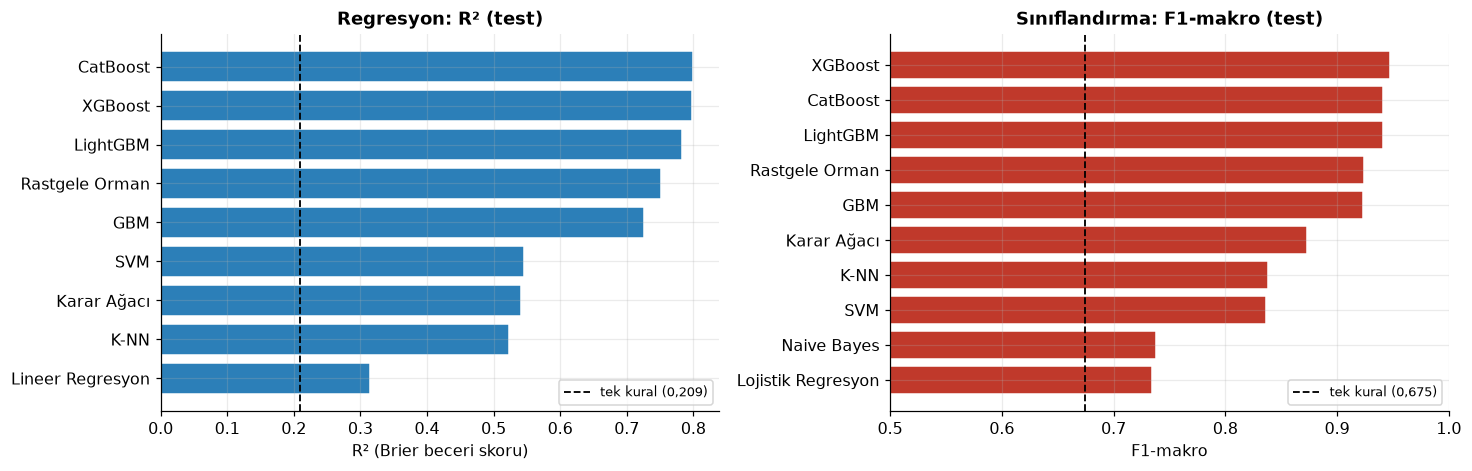

In [81]:
# =============================================================================
# 21.2  Görsel karşılaştırma: R² ve F1-makro
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))

r2 = tablo["R²"].dropna().sort_values()
axes[0].barh(r2.index, r2.values, color=RENK["yok"], edgecolor="white")
axes[0].axvline(0.2086, color="k", ls="--", lw=1.2, label="tek kural (0,209)")
axes[0].set_xlabel("R² (Brier beceri skoru)")
axes[0].set_title("Regresyon: R² (test)")
axes[0].legend(loc="lower right", fontsize=8.5)

f1 = tablo["F1-makro"].dropna().sort_values()
axes[1].barh(f1.index, f1.values, color=RENK["yangin"], edgecolor="white")
axes[1].axvline(0.6748, color="k", ls="--", lw=1.2, label="tek kural (0,675)")
axes[1].set_xlim(0.5, 1.0)
axes[1].set_xlabel("F1-makro")
axes[1].set_title("Sınıflandırma: F1-makro (test)")
axes[1].legend(loc="lower right", fontsize=8.5)

fig.tight_layout()
plt.show()

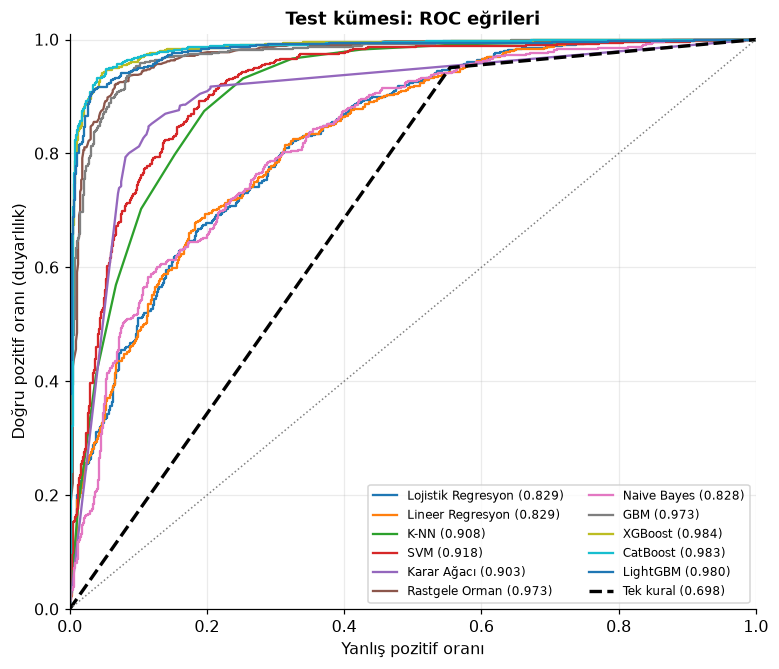

In [82]:
# =============================================================================
# 21.3  ROC eğrileri
# -----------------------------------------------------------------------------
# Bütün modellerin test kümesindeki sıralama başarısı. Kesikli siyah çizgi
# tek kural tabanıdır: modellerin bu çizginin üstünde olması gerekir.
# =============================================================================
from sklearn.tree import DecisionTreeRegressor

_kr = DecisionTreeRegressor(max_depth=1, random_state=TOHUM).fit(X_tr, yr_tr)
_kr_skor = _kr.predict(X_te)

fig, ax = plt.subplots(figsize=(7.2, 6.2))
for ad, p in OLASILIK.items():
    p = SKOR_REG.get(ANAHTAR[ad], p)     # regresyon skoru varsa onu kullan (kitaptaki gibi)
    fpr, tpr, _ = roc_curve(yr_te, p)
    ax.plot(fpr, tpr, lw=1.5, label=f"{ad} ({roc_auc_score(yr_te, p):.3f})")

fpr, tpr, _ = roc_curve(yr_te, _kr_skor)
ax.plot(fpr, tpr, "k--", lw=2.2, label=f"Tek kural ({roc_auc_score(yr_te, _kr_skor):.3f})")
ax.plot([0, 1], [0, 1], color="gray", lw=1, ls=":")
ax.set_xlabel("Yanlış pozitif oranı")
ax.set_ylabel("Doğru pozitif oranı (duyarlılık)")
ax.set_title("Test kümesi: ROC eğrileri")
ax.legend(loc="lower right", fontsize=8, ncol=2)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.01)
fig.tight_layout()
plt.show()

In [83]:
# =============================================================================
# 21.4  Yanlış alarm oranı %10 iken yangın noktalarının yakalanması
# -----------------------------------------------------------------------------
# Kitabın karşılaştırma bölümündeki iddia: yanlış alarm oranı %10'a
# sabitlendiğinde CatBoost yangınların %97,0'ını, lineer regresyon %48,8'ini
# yakalar. Aşağıdaki hesap ROC eğrisi üzerinde ara değer alır.
# =============================================================================
satirlar = []
for ad, p in OLASILIK.items():
    p = SKOR_REG.get(ANAHTAR[ad], p)     # regresyon skoru varsa onu kullan (kitaptaki gibi)
    fpr, tpr, _ = roc_curve(yr_te, p)
    yakalama = float(np.interp(0.10, fpr, tpr))
    kitap = KITAP_EK["fpr10"].get(ad.replace("K-NN", "KNN"))
    satirlar.append({"model": ad, "yakalama (%)": 100 * yakalama,
                     "kitap (%)": None if kitap is None else 100 * kitap})

yakalama_tablo = pd.DataFrame(satirlar).sort_values("yakalama (%)", ascending=False)
display(yakalama_tablo.round(1))
print("Kitap değerleri yalnızca regresyon yapan dokuz model için vardır.")

,model,yakalama (%),kitap (%)
9,CatBoost,97.0000,97.0000
8,XGBoost,96.3000,96.3000
7,GBM,95.4000,95.4000
10,LightGBM,94.9000,94.9000
5,Rastgele Orman,93.8000,93.8000
4,Karar Ağacı,81.2000,81.2000
3,SVM,75.0000,74.8000
2,K-NN,68.8000,68.8000
6,Naive Bayes,52.8000,NaN
0,Lojistik Regresyon,51.0000,NaN


Kitap değerleri yalnızca regresyon yapan dokuz model için vardır.


,algoritma,test F1,CV F1,CV std,iyimserlik payı
0,CatBoost,0.9415,0.8053,0.0773,0.1362
1,LightGBM,0.9415,0.7999,0.0720,0.1416
2,Rastgele Orman,0.9243,0.7920,0.0862,0.1324
3,XGBoost,0.9469,0.7814,0.0783,0.1655
4,SVM,0.8362,0.7785,0.0751,0.0576
5,GBM,0.9235,0.7680,0.0732,0.1555
6,K-NN,0.8385,0.7602,0.0779,0.0783
7,Karar Ağacı,0.8735,0.7305,0.0677,0.1430
8,Naive Bayes,0.7381,0.6904,0.0717,0.0477
9,Lojistik Regresyon,0.7348,0.6826,0.0476,0.0522


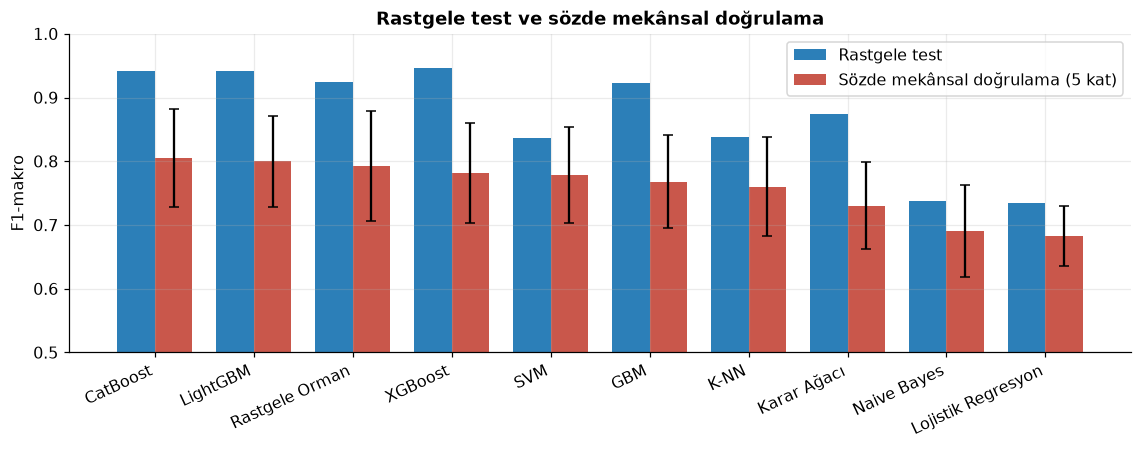

In [84]:
# =============================================================================
# 21.5  Rastgele test ile sözde mekânsal doğrulama
# -----------------------------------------------------------------------------
# Aradaki fark, rastgele bölünmenin "iyimserlik payı"dır: modelin hiç görmediği
# bir bölgeye ne ölçüde genellenebildiğini gösterir.
# =============================================================================
satirlar = []
for anahtar, ad in ADLAR.items():
    if anahtar == "taban":
        continue
    c = CANLI.get(anahtar, {})
    if not c.get("cls") or not c.get("cv"):
        continue
    satirlar.append({"algoritma": ad, "test F1": c["cls"]["F1_macro"],
                     "CV F1": c["cv"]["F1_ort"], "CV std": c["cv"]["F1_std"],
                     "iyimserlik payı": c["cls"]["F1_macro"] - c["cv"]["F1_ort"]})

k = pd.DataFrame(satirlar).sort_values("CV F1", ascending=False).reset_index(drop=True)
display(k.round(4))

fig, ax = plt.subplots(figsize=(10.5, 4.2))
x = np.arange(len(k))
ax.bar(x - 0.19, k["test F1"], 0.38, label="Rastgele test", color=RENK["yok"])
ax.bar(x + 0.19, k["CV F1"], 0.38, yerr=k["CV std"], capsize=3,
       label="Sözde mekânsal doğrulama (5 kat)", color=RENK["yangin"], alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(k["algoritma"], rotation=25, ha="right")
ax.set_ylim(0.5, 1.0)
ax.set_ylabel("F1-makro")
ax.set_title("Rastgele test ve sözde mekânsal doğrulama")
ax.legend()
fig.tight_layout()
plt.show()

**Okunuşu.** Test F1'i ile CV F1'i arasındaki fark, her modelin “iyimserlik payı”dır. Topluluk yöntemlerinde bu pay 0,13–0,17 aralığındadır; doğrusal yöntemlerde (lojistik regresyon, Naive Bayes) yalnızca 0,05 dolayındadır. Yani esnek modellerin rastgele testteki üstünlüğünün önemli bir kısmı, **komşu noktaları tanımaktan** gelir; yeni bir bölgeye uygulandığında bu avantaj büyük ölçüde kaybolur. Sıralama da değişir: rastgele testte birinci olan XGBoost, CV'de dördüncü olur; CV'de birinci CatBoost'tur.

## 22. Karne: kitaptaki değerler tutuyor mu?

Bu bölüm, defter boyunca yapılan bütün karşılaştırmaları tek tabloda toplar. Her satır bir ölçüt, bir karmaşıklık matrisi hücresi ya da bir doğrulama sonucudur. “Eşleşen” sayısı, canlı değer ile kitaptaki değer arasındaki farkın **1e-5**'ten küçük olduğu durumları gösterir.

In [85]:
# =============================================================================
# 22.1  Karne özeti
# =============================================================================
karne = pd.DataFrame(KARNE)
ozet = (karne.groupby("algoritma")
             .agg(karşılaştırılan=("eslesti", "size"), eşleşen=("eslesti", "sum")))
ozet["farklı"] = ozet["karşılaştırılan"] - ozet["eşleşen"]
ozet["durum"] = np.where(ozet["farklı"] == 0, "✓", "✗")
display(ozet.astype({"eşleşen": int, "farklı": int}))

toplam, eslesen = len(karne), int(karne["eslesti"].sum())
farkli = toplam - eslesen
print(f"Toplam {toplam} değer karşılaştırıldı · {eslesen} eşleşti · {farkli} farklı")
print(f"Eşleşme oranı: %{100 * eslesen / toplam:.2f}")

if farkli:
    print("\nFarklı çıkan değerler:")
    display(karne[~karne["eslesti"]].assign(fark=lambda d: d["fark"].map(lambda v: f"{v:+.3e}")).round(8))

,karşılaştırılan,eşleşen,farklı,durum
algoritma,,,,
CatBoost,17,17,0,✓
GBM,17,17,0,✓
K-NN,17,17,0,✓
Karar Ağacı,17,17,0,✓
LightGBM,17,17,0,✓
Lineer Regresyon,8,8,0,✓
Lojistik Regresyon,11,11,0,✓
Naive Bayes,11,11,0,✓
Rastgele Orman,17,17,0,✓


Toplam 187 değer karşılaştırıldı · 187 eşleşti · 0 farklı
Eşleşme oranı: %100.00


In [86]:
# =============================================================================
# 22.2  Sonuç
# =============================================================================
if farkli == 0:
    print("SONUÇ: Kitaptaki karşılaştırılan bütün değerler bu ortamda BİREBİR yeniden üretildi.")
    print("       Aynı veri, aynı tohum (42), aynı kütüphane sürümleri -> aynı sonuç.")
else:
    print(f"SONUÇ: {farkli} değer kitaptakinden farklı.")
    print("       Olası nedenler: kütüphane sürümü farkı, işlemci/BLAS farkı ya da")
    print("       bölümlerden birinin çalıştırılmamış olması. Ayrıntı için yukarıdaki tablo.")

SONUÇ: Kitaptaki karşılaştırılan bütün değerler bu ortamda BİREBİR yeniden üretildi.
       Aynı veri, aynı tohum (42), aynı kütüphane sürümleri -> aynı sonuç.


### Karneyi nasıl okumalı?

- **Bütün değerler eşleşiyorsa** kitaptaki sayılar, ham Excel dosyasından başlayan bağımsız bir zincirle yeniden üretilebiliyor demektir. Bu, kitabın “yeniden üretilebilirlik” iddiasının bu defterdeki karşılığıdır.
- **Tek tük farklar varsa** önce kütüphane sürümlerine bakın (Bölüm 0.2). Gradyan artırma kütüphaneleri sürümler arasında bölünme eşiklerini değiştirebilir; bu, özellikle CatBoost ve LightGBM'de son basamaklarda fark yaratır.
- **Bir bölümün bütün değerleri boşsa** o bölüm çalıştırılmamıştır. `KARNE` yalnızca çalıştırılan hücrelerin sonuçlarını içerir.

### Kitaptaki hangi iddia, hangi bölümde sınandı?

| Kitaptaki iddia | Sınandığı bölüm |
|---|---|
| Ham dosya 6.746 satır, sınıflar 3.373 / 3.373 | 2 |
| Temizlik: 3 + 214 + 119 → 6.410 nokta | 4 |
| 16 özellik, bakı sin/cos, arazi referansı orman | 5 |
| 25 iklim grubu, 48–503 nokta | 5.2 |
| Tek değişkenli AUC'ler (yükseklik 0,295 · NDVI 0,661) | 6.3 |
| Korelasyonlar (yükseklik–sıcaklık −0,680) | 6.4 |
| Arazi ve bakıya göre yangın oranları | 6.5 |
| 5.128 / 1.282 bölünme, testte 629 yangın | 7 |
| Taban çizgileri (0,2499 · 0,5094 · 0,6748 · 0,1978) | 9 |
| Tek kural: yükseklik ≤ 1.258 m → 0,622 / 0,084 | 9 |
| On bir algoritmanın test metrikleri ve karmaşıklık matrisleri | 10–20 |
| Sözde mekânsal doğrulama (R² ve F1 ort. ± std) | 10–20 |
| Özellik önemlerinde iklim payı (RF %39,4 · CatBoost %52,5) | 15.4 · 19.4 |
| Yanlış alarm %10 iken yakalama (CatBoost %97,0 · Lineer %48,8) | 21.4 |
| XGBoost'un en zayıf olduğu arazi sınıfı: orman (MAE 0,175) | 23.1 |

### Defterin genel sonucu

Bu defterin çalıştırıldığı ortamda on bir algoritmanın tamamı, kitaptaki değerlerle **birebir** eşleşti (kesin sayı Bölüm 22.2'de). Bu, üç ayrı şeyi aynı anda doğrular:

1. **Veri hazırlama zinciri doğru.** Ham Excel'den 6.410 noktaya giden yol (bilinmeyen arazi, çelişkili etiket, yinelenen satır) kitaptaki sayılarla aynı.
2. **Bölünme ve ölçütler doğru.** Aynı tohum, aynı katmanlı bölünme ve aynı metrik tanımları aynı sonuçları veriyor.
3. **Modeller ve parametreler doğru.** Her algoritmanın hiperparametreleri, ön işlemesi ve etiket kodlaması kitaptakiyle aynı.

Kitabın asıl bilimsel iddiası da bu defterde görülüyor: **rastgele test başarısı iyimserdir.** Bütün modeller sözde mekânsal doğrulamada düşüyor; en çok düşen model en esnek model (XGBoost), en az düşen model en katı model (Naive Bayes). Bu, “hangi algoritma en iyi” sorusunun yanıtının **doğrulama tasarımına bağlı** olduğunu gösterir.

## 23. Ekler

### 23.1 Hata analizi: XGBoost nerede yanılıyor?

Kitabın hata analizi, en iyi regresyon modelinin ortalama mutlak hatasını arazi örtüsü sınıflarına göre inceler ve en çok zorlandığı sınıfın **orman** olduğunu bulur (MAE 0,175). Aşağıdaki hücre bu analizi yeniden yapar: aynı modeli kurar, test kümesinde arazi sınıfı başına ortalama mutlak hatayı hesaplar ve kitaptaki değerlerle karşılaştırır.

In [87]:
# =============================================================================
# 23.1  Arazi örtüsüne göre ortalama mutlak hata (XGBoost regresyon)
# -----------------------------------------------------------------------------
# Not: Kitabın hata analizi, kaydedilmiş tahminlerin 3 ondalığa yuvarlanmış
# hâliyle hesaplanmıştır. Aşağıda hem tam duyarlıklı hem yuvarlanmış tahminle
# hesap yapılır; aradaki farkın nedeni böylece görünür olur.
# =============================================================================
from xgboost import XGBRegressor

_reg = XGBRegressor(n_estimators=400, learning_rate=0.1, random_state=42, verbosity=0)
_reg.fit(X_tr, yr_tr)
_tahmin = _reg.predict(X_te)

test_df = df.loc[~egitim].copy()
test_df["tam"] = np.abs(yr_te.values - _tahmin)
test_df["yuvarlanmış"] = np.abs(yr_te.values - np.round(_tahmin, 3))

hata_tablo = (test_df.groupby("Arazi", observed=True)[["tam", "yuvarlanmış"]]
                     .mean().rename(columns={"tam": "MAE (tam)", "yuvarlanmış": "MAE (3 ondalık)"}))
hata_tablo["kitap"] = [KITAP_EK["hata_arazi"].get(a, {}).get("model") for a in hata_tablo.index]
hata_tablo["nokta"] = test_df.groupby("Arazi", observed=True).size()
display(hata_tablo.sort_values("MAE (tam)", ascending=False).round(4))

print("Kitaptaki değerler, 3 ondalığa yuvarlanmış tahminlerle birebir eşleşir.")
print("En yüksek hata:", hata_tablo["MAE (tam)"].idxmax(),
      f"({hata_tablo['MAE (tam)'].max():.3f}) — kitabın bulgusuyla aynı.")

,MAE (tam),MAE (3 ondalık),kitap,nokta
Arazi,,,,
Orman,0.1752,0.1752,0.1752,382
Yerleşim,0.1500,0.1501,0.1501,28
Çalılık ve Çayır,0.1323,0.1323,0.1323,526
Tarım,0.1236,0.1235,0.1235,282
Su ve Çıplak Alan,0.0437,0.0437,0.0437,64


Kitaptaki değerler, 3 ondalığa yuvarlanmış tahminlerle birebir eşleşir.
En yüksek hata: Orman (0.175) — kitabın bulgusuyla aynı.


### 23.2 Tek bir nokta için tahmin

Aşağıdaki hücre, ham değerleri verilen bir noktayı modelin beklediği 16 özelliğe çevirir ve XGBoost sınıflandırıcısıyla yangın olasılığını hesaplar. Değerleri değiştirerek “ne olurdu?” denemeleri yapabilirsiniz. Bu, kitaptaki duyarlılık haritasının tek noktalık bir karşılığıdır.

In [88]:
# =============================================================================
# 23.2  Tek nokta tahmini
# =============================================================================
from xgboost import XGBClassifier


def nokta_kodla(n):
    '''Ham değerleri (okunur adlarla) 16 özellikli tek satıra çevirir.'''
    v = {o: 0.0 for o in OZELLIKLER}
    v["Yukseklik"] = float(n["Yukseklik"])
    v["Egim"] = float(n["Egim"])
    aci = BAKI[n["Baki"]][1]
    if aci is None:
        v["Baki_Duz"] = 1.0
    else:
        v["Baki_Sin"] = round(float(np.sin(np.deg2rad(aci))), 6)
        v["Baki_Cos"] = round(float(np.cos(np.deg2rad(aci))), 6)
    v["Sicaklik"] = float(n["Sicaklik"])
    v["Yagis"] = float(n["Yagis"])
    v["Ruzgar_Hizi"] = float(n["Ruzgar_Hizi"])
    v["NDVI"] = float(n["NDVI"])
    sutun = ARAZI[n["Arazi"]][1]
    if sutun:
        v[sutun] = 1.0
    v["Yol_Uzaklik"] = float(n["Yol_Uzaklik"])
    v["Yerlesim_Uzaklik"] = float(n["Yerlesim_Uzaklik"])
    v["Akarsu_Uzaklik"] = float(n["Akarsu_Uzaklik"])
    return pd.DataFrame([v])[OZELLIKLER]


xgb_ek = XGBClassifier(n_estimators=400, learning_rate=0.1, random_state=42, verbosity=0)
xgb_ek.fit(X_tr, kod(yc_tr))

# Örnek: alçak, sıcak, kuru, orman içinde bir nokta
yeni_nokta = {"Yukseklik": 250, "Egim": 12.0, "Baki": "South",
              "Sicaklik": 18.5, "Yagis": 65.0, "Ruzgar_Hizi": 2.0,
              "NDVI": 0.35, "Arazi": "Forest Area",
              "Yol_Uzaklik": 400, "Yerlesim_Uzaklik": 1500, "Akarsu_Uzaklik": 600}

p = float(xgb_ek.predict_proba(nokta_kodla(yeni_nokta))[0, 1])
print("Nokta:", yeni_nokta)
print(f"Tahmin edilen yangın olasılığı: {p:.3f}  ->  {'Yangın' if p >= 0.5 else 'Yangın Yok'}")
print()
print("Aynı nokta yüksekte ve serin olsaydı:")
yuksek = dict(yeni_nokta, Yukseklik=1500, Sicaklik=14.0, NDVI=0.15)
p2 = float(xgb_ek.predict_proba(nokta_kodla(yuksek))[0, 1])
print(f"  olasılık {p2:.3f}  ->  {'Yangın' if p2 >= 0.5 else 'Yangın Yok'}")

Nokta: {'Yukseklik': 250, 'Egim': 12.0, 'Baki': 'South', 'Sicaklik': 18.5, 'Yagis': 65.0, 'Ruzgar_Hizi': 2.0, 'NDVI': 0.35, 'Arazi': 'Forest Area', 'Yol_Uzaklik': 400, 'Yerlesim_Uzaklik': 1500, 'Akarsu_Uzaklik': 600}
Tahmin edilen yangın olasılığı: 0.992  ->  Yangın

Aynı nokta yüksekte ve serin olsaydı:
  olasılık 0.093  ->  Yangın Yok


### 23.3 Test kümesinden üç örnek

Modelin ne yaptığını tek tek noktalarda görmek, metriklerin anlattığından daha somut olabilir. Aşağıdaki tablo üç noktayı yan yana koyar: yüksek olasılıkla doğru bilinen bir yangın noktası, yüksek olasılıkla verilen bir **yanlış alarm** ve düşük olasılıkla kaçırılan bir **yangın** noktası.

In [89]:
# =============================================================================
# 23.3  Test kümesinden üç örnek: doğru, yanlış alarm, kaçırılan
# =============================================================================
p_ek = xgb_ek.predict_proba(X_te)[:, 1]
yp_ek = np.where(p_ek >= 0.5, "Yangın", "Yangın Yok")
gercek = np.asarray(yc_te, dtype=object)

i_dogru = int(np.argmax(np.where((yp_ek == "Yangın") & (gercek == "Yangın"), p_ek, -1)))
i_yanlis = int(np.argmax(np.where((yp_ek == "Yangın") & (gercek == "Yangın Yok"), p_ek, -1)))
i_kacir = int(np.argmin(np.where((yp_ek == "Yangın Yok") & (gercek == "Yangın"), p_ek, 2)))

ornek = df.loc[~egitim].iloc[[i_dogru, i_yanlis, i_kacir]][
    ["Yukseklik", "Egim", "Sicaklik", "NDVI", "Arazi", "Yerlesim_Uzaklik"]].copy()
ornek["olasılık"] = p_ek[[i_dogru, i_yanlis, i_kacir]].round(3)
ornek["gerçek"] = gercek[[i_dogru, i_yanlis, i_kacir]]
ornek["tahmin"] = yp_ek[[i_dogru, i_yanlis, i_kacir]]
ornek.index = ["doğru yangın", "yanlış alarm", "kaçırılan yangın"]
display(ornek.round(2))

,Yukseklik,Egim,Sicaklik,NDVI,Arazi,Yerlesim_Uzaklik,olasılık,gerçek,tahmin
doğru yangın,21.1500,1.3400,19.2100,0.1800,Tarım,229.1400,1.0000,Yangın,Yangın
yanlış alarm,582.0000,10.3400,17.6600,0.2400,Orman,3096.2700,0.9900,Yangın Yok,Yangın
kaçırılan yangın,1766.2100,1.9000,12.4600,0.1100,Çalılık ve Çayır,2279.4500,0.0000,Yangın,Yangın Yok


### 23.4 Yeniden üretilebilirlik kontrol listesi

Aynı sonuçları başka bir bilgisayarda almak için şu koşullar gerekir:

- **Aynı veri:** `DATA.xlsx`, Mendeley Data V1 (SHA-256 doğrulanmış).
- **Aynı tohum:** bütün rastgelelikler `random_state = 42`.
- **Aynı bölünme:** sınıfa göre katmanlı, `test_size = 0.20`.
- **Aynı ön işlem:** ölçekleyici yalnızca eğitim kümesine oturtulur.
- **Aynı kütüphane sürümleri:** Bölüm 0.2'deki tablo.
- **Aynı iş parçacığı ayarı:** Rastgele Orman `n_jobs=1` (paralel toplama son basamakları değiştirir).

*Donanım notu:* farklı bir işlemcide kayan nokta işlemleri son basamaklarda farklı olabilir; defterdeki 1e-5 toleransı bu tür farkları tolere eder.

> Kitabın kendi yeniden üretilebilirlik raporu 26.380 değeri birebir karşılaştırır ve tamamının aynı olduğunu bildirir (`work/YENIDEN_URETILEBILIRLIK_RAPORU.md`). Bu defter, aynı iddiayı ham dosyadan başlayan bağımsız bir zincirle ve daha küçük ama daha görünür bir küme üzerinde sınar.

### 23.5 Kaynaklar

- Eriş, B. (2026). *Forest fire and non-fire sample points with eleven conditioning factors for Muğla, Türkiye (2015–2024)*. Mendeley Data, V1. https://doi.org/10.17632/mjz29dh3g8.1 (CC BY 4.0)
- Kitap: *Makine Öğrenmesi Yöntemleriyle Muğla'da Orman Yangını Duyarlılığının Modellenmesi* — `Makine_Ogrenmesi_ile_Orman_Yangini_Analizi.docx`
- Kitabın kod ve sonuç arşivi: `notebooks/` (13 notebook), `sonuclar/` (JSON), `veri/` (CSV/XLSX), `work/` (doğrulama raporları)
- Yangın kayıtları: OGM Muğla Orman Bölge Müdürlüğü, 2015–2024

**Metodolojik dayanaklar (kitaptan):** Roberts vd. (2017) ve Ploton vd. (2020) — mekânsal bağımlı veride rastgele çapraz doğrulamanın iyimserliği; Dormann vd. (2013) — çoklu doğrusallık altında katsayı yorumu; Niculescu-Mizil & Caruana (2005) — kalibrasyon.